
🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_G (Tipo G)...
✅ Lectura completada. Se extrajeron datos de 124 planetas.
✅ Sistema Solar agregado: 8 de 8 planetas con área estable (tipo G, panel de 8 planetas).

Generando mapas separados (fila para F, resto en cuadrícula) para: Area_Estable_km2...


Generando paneles Tipo G: 100%|██████████| 5/5 [00:09<00:00,  1.94s/panel]


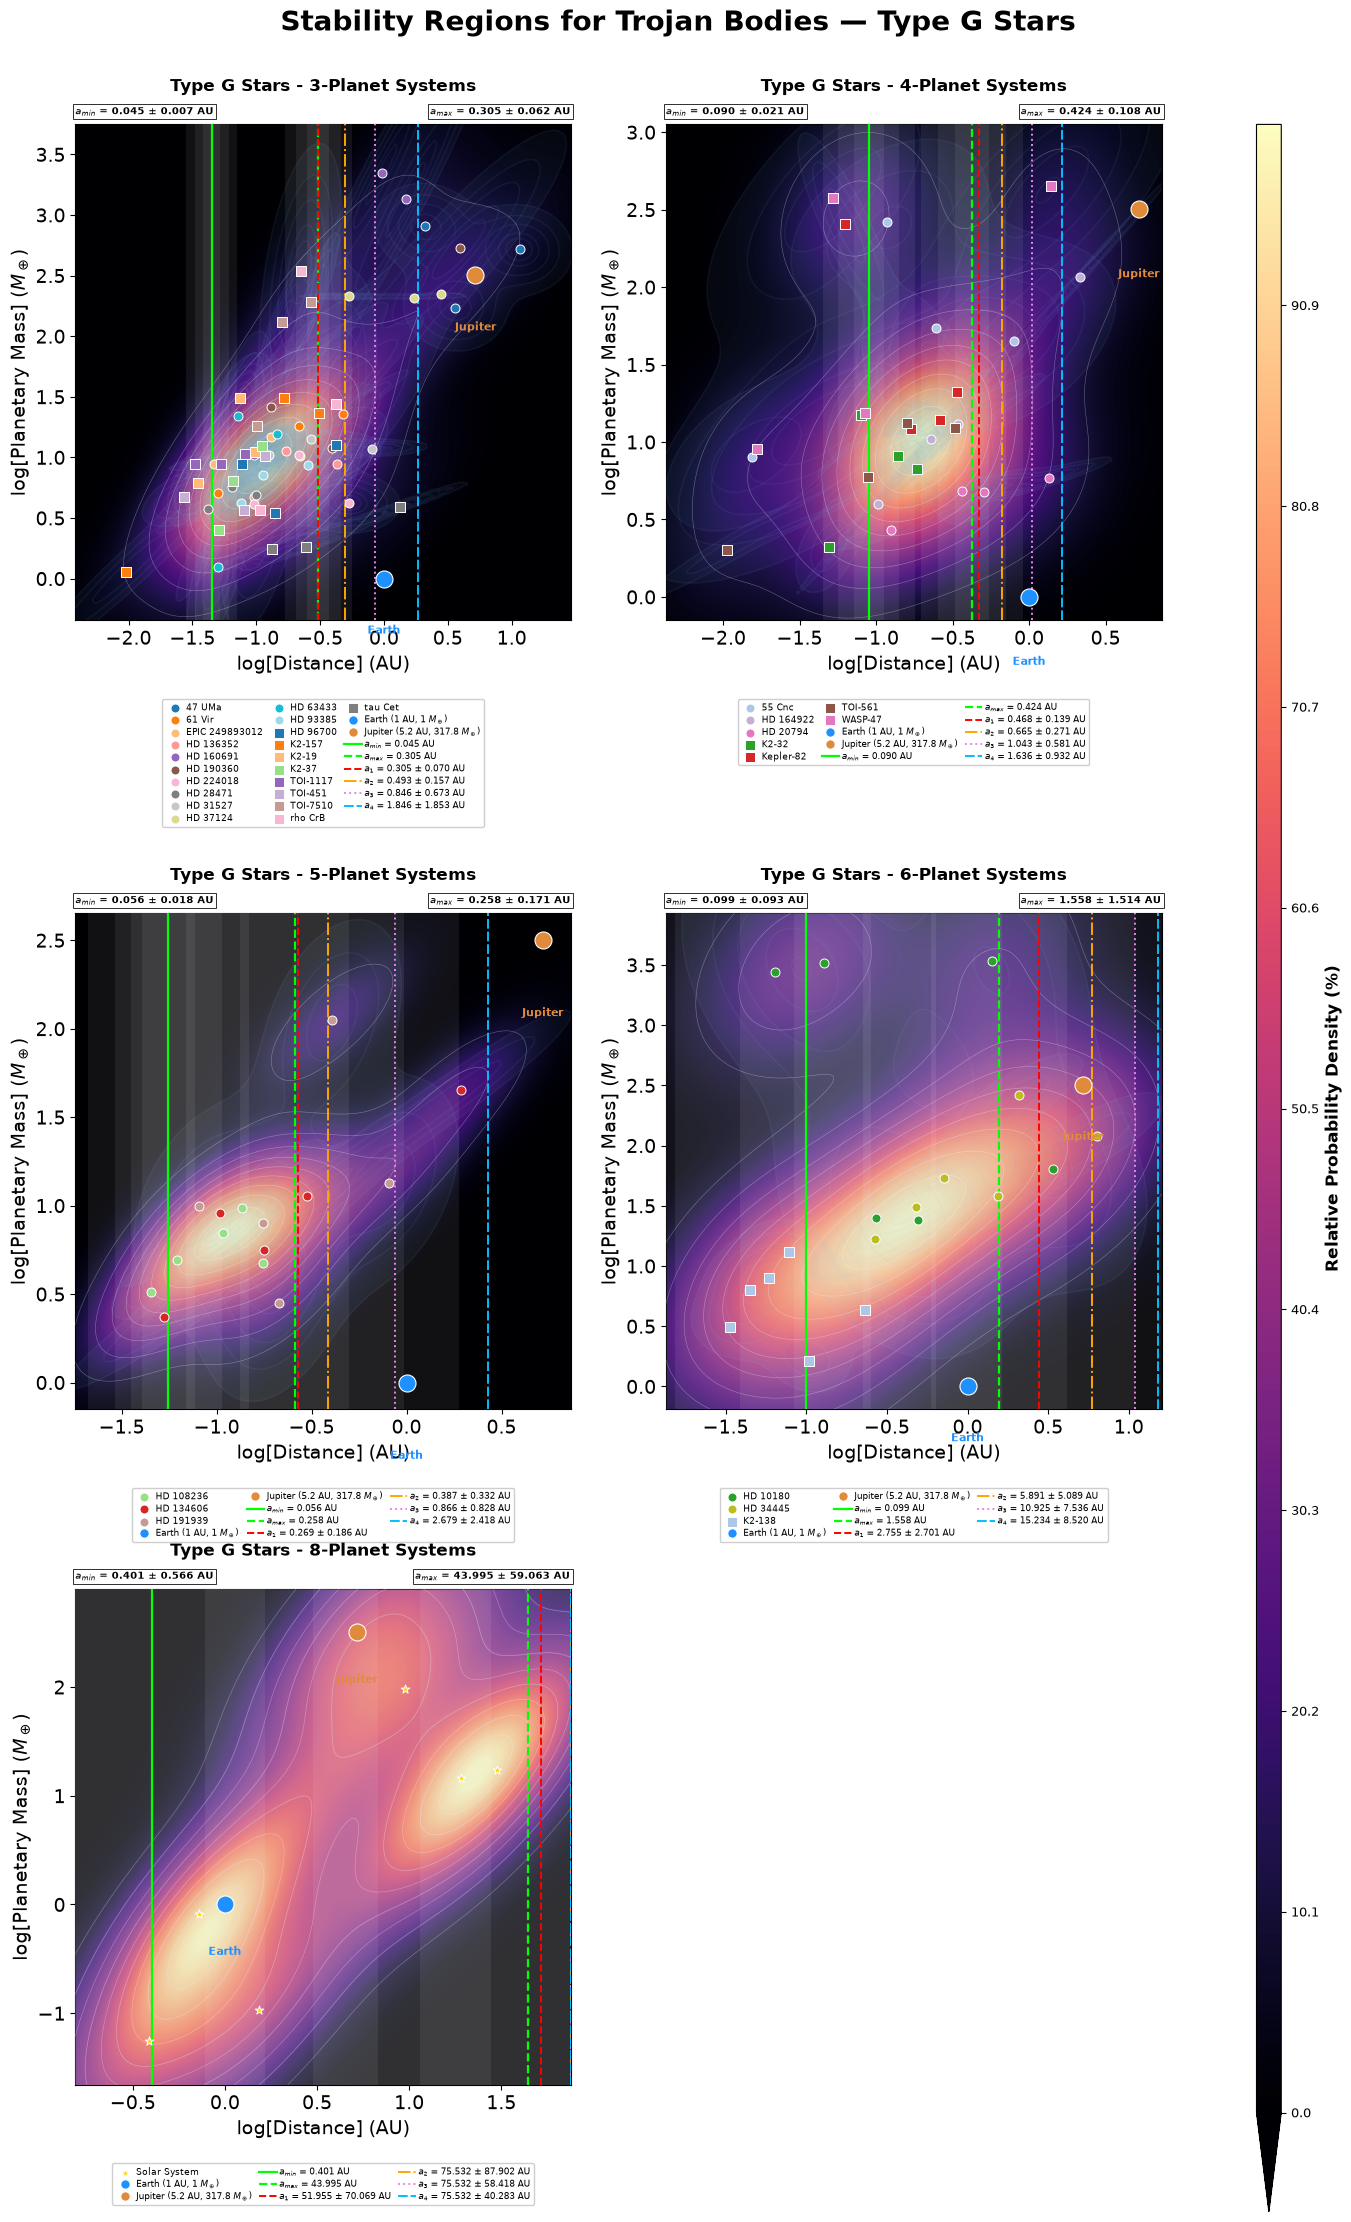

Intervalos σ guardados en: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_G\graficos_magma_con_sistemas_azules\intervalos_sigma.csv
   Aviso: con 999 réplicas cada cola de 3σ queda apoyada en ~1.3 réplicas; el 3σ por percentil es poco fiable. Sube kde['n_bootstrap'] a 5000-10000 si lo vas a reportar.

Análisis del Sistema Solar frente a estrellas tipo G...


Planeta   a_UA  Masa_Mtierra  Area_Estable_km2  Densidad_rel_G_% Intervalo_barra_%  Percentil_en_planetas_G_%  a_min_G_UA  a_max_G_UA  Dentro_[a_min,a_max]  a_min-3σ_UA  a_max+3σ_UA  Dentro_[a_min-3σ,a_max+3σ]
  Earth  1.000        1.0000      2.590000e+13          1.961979          0.0-10.1                   0.000000    0.047702    0.455608                 False     0.032959     0.705976                       False
Jupiter  5.203      317.8000      6.820000e+15         14.863266         10.1-20.2                  15.322581    0.047702    0.455608                 False     0.032959     0.705976                       False
   Mars  1.524        0.1070      5.160000e+13          0.000521          0.0-10.1                   0.000000    0.047702    0.455608                 False     0.032959     0.705976                       False
Mercury  0.387        0.0553      3.010000e+12          0.001145          0.0-10.1                   0.000000    0.047702    0.455608                  True     

Comparación con/sin Sistema Solar guardada en: comparacion_G_con_sin_sistema_solar.csv


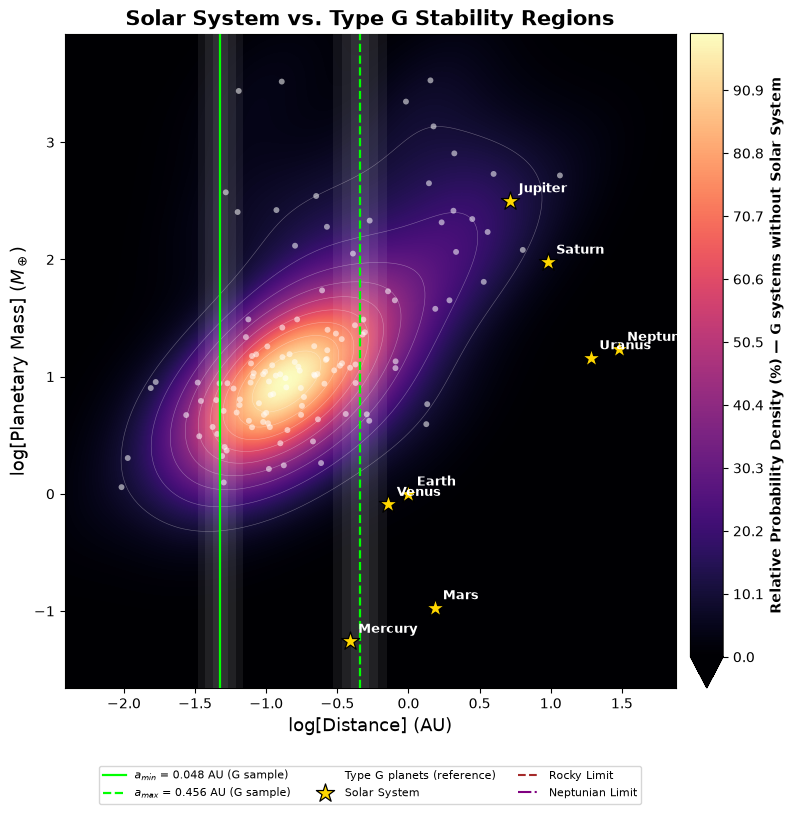

Gráficos guardados en: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_G\graficos_magma_con_sistemas_azules


In [2]:
"""
Mapas de regiones de estabilidad (KDE) para cuerpos troyanos por tipo espectral.

NOVEDADES respecto a la versión anterior (marcadas con [NUEVO] / [MOD]):
  1. Sistema Solar agregado al tipo G (CONFIG["sistema_solar"]) + análisis de
     coherencia con el resto de sistemas G (analizar_sistema_solar).
  2. Intervalos 1σ, 2σ y 3σ para a_min, a_max y a_1..a_4 (CONFIG["limites"]):
     bandas dibujadas, y tabla "intervalos_sigma.csv" en formato largo.
"""
import os
import re
import sys
import math
import json
import hashlib
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize, ListedColormap
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde
from scipy.interpolate import RegularGridInterpolator      # [NUEVO]
import tkinter as tk
from tkinter import filedialog, simpledialog, messagebox   # [MOD] + messagebox

try:
    from tqdm import tqdm  # pip install tqdm
except ImportError:
    def tqdm(iterable, total=None, desc=None, **kwargs):
        """
        Fallback mínimo si la librería 'tqdm' no está instalada: imprime el
        progreso como porcentaje sobre la misma línea de la terminal.
        """
        if total is None:
            try:
                total = len(iterable)
            except TypeError:
                total = None
        prefijo = f"{desc}: " if desc else ""
        for i, item in enumerate(iterable, start=1):
            yield item
            if total:
                pct = 100 * i / total
                print(f"\r{prefijo}{pct:5.1f}% ({i}/{total})", end="", flush=True)
        if total:
            print()


CONFIG = {
    # ------------------------------------------------------------------ general
    "general": {
        "carpeta_salida": "graficos_magma_con_sistemas_azules",  # dentro de la 1ª carpeta elegida
        "dpi": 300,
        "mostrar_figuras": True,            # False = solo guarda (útil sin pantalla)
        "tipos_espectrales": ("F", "G", "K", "M"),
        "max_carpetas": 10,                 # tope del diálogo de selección
        "marcadores": ["o", "s", "^", "D", "v", "p", "*", "h",
                       "H", "X", "d", "P", "<", ">"],
        "paleta_colores": "tab20",
        # [NUEVO] True = también genera la figura 2x2 "All systems — Type X"
        # (en la versión anterior ejecutar() nombraba la función pero no la llamaba).
        "generar_figura_por_tipo": False,
    },

    # ---------------------------------------------------------------------- KDE
    "kde": {
        "bw_method": 0.6,
        "grid_res": 150,                    # malla del KDE global de cada panel
        "grid_res_individual": 125,         # malla de cada sistema individual
        "grid_res_bootstrap": 150,          # malla de cada réplica bootstrap
        # Para intervalos de 3σ por percentil se recomienda >= 5000 réplicas
        # (con 1000, cada cola de 3σ queda apoyada en ~1 réplica).
        "n_bootstrap": 1000,                # réplicas por panel
        "semilla_bootstrap": None,          # entero para resultados reproducibles
        # Peso de cada planeta ("area" | "fraccion" | "neto"), ver _calcular_pesos
        "modo_peso_islas": "area",          # figuras por tipo y por multiplicidad general
        "modo_peso_matriz": "area",         # figura F horizontal + G/K/M en 2x2
    },

    # ------------------------------------------------------------- caché (.txt)
    "cache": {
        "activo": True,
        "carpeta": "kde_cache",             # dentro de la carpeta de salida
        "forzar_recalculo": False,          # True = ignora los .txt y los reescribe
        "cachear_individuales": False,      # True = también un .txt por cada sistema
        "cachear_bootstrap": True,          # guarda las réplicas bootstrap (lo más lento)
    },

    # ------------------------------------------------------------------ colores
    "colores": {
        "cmap_global": "magma",             # densidad del conjunto completo
        "cmap_individual": "Blues",         # densidad de cada sistema individual
        "contorno_individual": "#8fb8ff",
        "color_limites_matriz": "lime",     # a_min / a_max en la figura matriz
        "color_limites_islas": "white",     # a_min / a_max en las figuras por tipo
        "color_banda_sigma": "white",
        "color_grid": "white",
    },

    # --------------------------------------------------------- orden de las capas
    "capas": {
        "alpha_global": 1.0,
        "zorder_global": 2.5,
        "estilo_global": "suave",
        "niveles_global": None,
        "lineas_bandas": True,
        "color_lineas_bandas": "white",
        "lw_lineas_bandas": 0.4,
        "alpha_lineas_bandas": 0.35,
        "zorder_individual_fill": 1.5,
        "dibujar_relleno_individual": True,
        "contornos_individuales_encima": False,
        "individuales_difusos_encima": True,
        "zorder_individual_fill_encima": 2.505,
        "zorder_individual_line_difuso": 2.505,
        "alpha_individual_fill_difuso": 0.05,
        "alpha_individual_line_difuso": 0.07,
        "zorder_individual_line_encima": 4.0,
        "zorder_individual_line_debajo": 1.7,
        "alpha_individual_fill": 0.95,
        "alpha_individual_line": 0.95,
        "niveles_individuales": (20.2, 40.4, 60.6, 80.8, 90.9, 100.0),
        "lw_contorno_individual": 1.1,
        "azul_recorte_inferior": 0.45,
        "zorder_grid": 3,
        "zorder_banda_sigma": 3,
        "zorder_lineas_limite": 6,
        "zorder_cajas_texto": 7,
        "zorder_puntos": 5,
        "zorder_puntos_matriz": 8,
        "zorder_referencias": 9,
        "zorder_tierra_islas": 10,
    },

    # ------------------------------------------------------ límites críticos a_*
    "limites": {
        "percentil_inf": 10,
        "percentil_sup": 98,
        "n_niveles_percentil": 25,
        "indice_umbral_percentil": -4,
        "nivel_region_estable": 90.9,
        "niveles_a1_a4": (70.7, 50.5, 30.3, 20.2),
        "lado_a1_a4": "derecho",
        "estilos_a1_a4": {
            "a_1": ("red", "--"),
            "a_2": ("orange", "-."),
            "a_3": ("violet", ":"),
            "a_4": ("deepskyblue", (0, (5, 1.5))),
        },
        "tick_max": 90.9,
        "n_ticks": 10,

        # [NUEVO] ---------------- incertidumbre 1σ / 2σ / 3σ ----------------
        # Qué k-sigma se calculan y se exportan a intervalos_sigma.csv
        "sigmas": (1, 2, 3),
        # Qué k-sigma se DIBUJAN como bandas sobre a_min / a_max (anidadas)
        "dibujar_sigmas": (1, 2, 3),
        # Cómo se construye la banda dibujada:
        #   "std"       : centro ± k·std(réplicas)  (consistente con el "±" de las cajas de texto)
        #   "percentil" : percentiles de las réplicas con cobertura gaussiana de k·σ
        #                 (68.27 %, 95.45 %, 99.73 %); no asume normalidad.
        "metodo_sigma_dibujo": "std",
        "alpha_banda_sigma": 0.07,          # alpha de cada banda cuando se dibuja más de una
    },

    # --------------------------------------------------------------- referencias
    "referencias": {
        "jupiter_ua": 5.2,
        "jupiter_masa": 317.8,
        "color_tierra": "#1e90ff",
        "color_jupiter": "#e08a3c",
        "limite_rocoso_masa": 2.0,
        "limite_neptuniano_masa": 10.0,
        "color_rocoso": "brown",
        "color_neptuniano": "purple",
        "etiqueta_tierra_islas": r"Earth (1 AU, 1 $M_\oplus$, $A_{stab}=1.27 \times 10^{13}$ km$^2$)",
    },

    # [NUEVO] ------------------------------------------------------ Sistema Solar
    "sistema_solar": {
        "activo": True,
        "preguntar": True,                  # True = pregunta con un diálogo si incluirlo
        "tipo_estrella": "G",
        "nombre_sistema": "Solar System",
        # "config"  : usa la tabla de "planetas" de abajo (necesita las áreas estables)
        # "carpeta" : escanea una carpeta con la MISMA estructura (resumen.txt + README.txt)
        #             que tus simulaciones; es la opción recomendada si ya lo simulaste.
        "fuente": "config",
        "n_planetas_total": 8,              # multiplicidad con la que aparece el Sistema Solar
        "marcador": "*", "color": "gold",
        # nombre: (a [UA], masa [M_tierra], A_estable, A_inestable, A_colisión_m2 [km²],
        #          zonas_estables, zonas_inestables, zonas_colisión_m2)
        # Datos de tus tablas Sol-Planeta (colisión con m1 = 0 en todos los casos).
        # Un A_estable None se omite con un aviso.
        "planetas": {
            "Mercury": (0.387, 0.0553, 3.01e12, 5.33e14, 2.15e12,  56, 9904, 40),
            "Venus":   (0.723, 0.815,  1.27e13, 1.85e15, 4.29e12,  68, 9909, 23),
            "Earth":   (1.000, 1.000,  2.59e13, 3.57e15, 7.92e12,  72, 9906, 22),
            "Mars":    (1.524, 0.107,  5.16e13, 8.24e15, 2.58e13,  62, 9907, 31),
            "Jupiter": (5.203, 317.8,  6.82e15, 9.00e16, 9.68e12, 704, 9295,  1),
            "Saturn":  (9.537, 95.16,  1.29e16, 3.13e17, 2.61e14, 397, 9595,  8),
            "Uranus":  (19.19, 14.54,  2.03e16, 1.30e18, 1.85e15, 154, 9832, 14),
            "Neptune": (30.07, 17.15,  5.57e16, 3.18e18, 4.53e15, 172, 9814, 14),
        },
        # KDE del Sistema Solar por sí solo (analizar_kde_sistema_solar / ejecutar_sistema_solar)
        "kde_solo": {
            "carpeta": "graficos_sistema_solar",   # dentro del directorio de trabajo
            "figura": "KDE_Sistema_Solar",
            # Peso de cada planeta (ver _calcular_pesos):
            #   "area"     : log10(A_estable + 1)                     (solo regiones estables)
            #   "fraccion" : A_est / (A_est + A_inest + A_colisión m2) (usa inestables y colisión)
            #   "neto"     : log10(max(A_est - (A_inest + A_col), 0) + 1)
            # ejecutar_sistema_solar() corre todos los de "modos_peso".
            "modo_peso": "fraccion",
            "modos_peso": ("area", "fraccion", "neto"),
            "criterio_limites": None,              # None = el de fig_matriz; "percentil" | "nivel"
            "margen": 0.5,                         # holgura de ejes (dex)
            "n_bootstrap": 5000,                   # sube la fiabilidad del 3σ por percentil
            "csv_planetas": "kde_sistema_solar_planetas.csv",
            "csv_sigma": "kde_sistema_solar_intervalos_sigma.csv",
        },
        "analisis": {
            "margen": 0.4,                  # holgura de ejes (dex) en la figura de comparación
            "csv_planetas": "analisis_sistema_solar_planetas.csv",
            "csv_comparacion": "comparacion_G_con_sin_sistema_solar.csv",
            "figura": "Solar_System_vs_G_Type",
            "comparar_con_y_sin": True,     # recalcula a_* de G con y sin el Sistema Solar
        },
    },

    # ---------------------------------------------- paneles (figuras por tipo/mult.)
    "panel_islas": {
        "titulo_fs": 18, "titulo_pad": 15,
        "label_fs": 14,
        "tick_fs": 14,
        "cbar_label_fs": 12, "cbar_tick_fs": 10,
        "cbar_pad": 0.02, "cbar_aspect": 35, "cbar_fraction": 0.046,
        "texto_limite_fs": 11, "texto_dx": 0.05, "texto_y": 0.92,
        "lw_limite": 2.5, "alpha_banda": 0.15,
        "marker_size": 110, "marker_edge_lw": 1.0,
        "tierra_size": 400, "tierra_edge_lw": 1.2,
        "grid_alpha": 0.3,
        "leyenda_bbox": (0.5, -0.14),
        "leyenda_tramos": ((20, 4, 8.5), (10, 3, 9.5), (5, 2, 10)),
        "leyenda_defecto": (1, 10.5),
        "leyenda_refs_fs": 10.5,
    },

    # --------------------------------------------------------- figura por tipo (2x2)
    "fig_tipo": {
        "ncols": 2,
        "ancho": 17.0, "alto_por_fila": 11.5,
        "suptitle_fs": 26, "suptitle_y": 0.99,
        "rect": (0, 0, 1, 0.96),
        "hspace": 0.65, "wspace": 0.28,
        "margen_ejes": 0.4,
    },

    # ------------------------------------------------ figura horizontal multiplicidad
    "fig_horizontal": {
        "ancho_por_panel": 7.8, "alto": 10.0,
        "suptitle_fs": 26, "suptitle_y": 0.99,
        "rect": (0, 0, 1, 0.95),
        "margen_ejes": 0.4,
    },

    # --------------------------------- figura matriz (F en fila, G/K/M en 2 columnas)
    "fig_matriz": {
        "tipo_en_fila": "F",
        "ncols_resto": 2,
        "ancho_por_panel": 6.0, "ancho_extra": 1.4,
        "alto_base": 6.0, "alto_por_fila_leyenda": 0.2, "alto_extra": 1.0,
        "margen_sup_in": 1.3,
        "suptitle_fs": 20, "suptitle_dy_in": 0.15,
        "cbar_ancho_ratio": 0.05,
        "left": 0.05, "right": 0.95, "bottom": 0.01,
        "hspace": 0.05, "wspace": 0.28,
        "cbar_label_fs": 12, "cbar_tick_fs": 9,
        "criterio_limites": "percentil",    # "percentil" | "nivel"
        "limites_por_panel": True,
        "margen_panel": 0.4,
        "holgura_tierra": 0.15, "holgura_jupiter": 0.15,
        "margen_x_comun": 0.4, "margen_y_inf_comun": 0.8, "margen_y_sup_comun": 0.5,
    },

    # -------------------------------------------------------------- panel matriz
    "panel_matriz": {
        "titulo_fs": 12, "titulo_pad": 24,
        "label_fs": 14, "tick_fs": 14,
        "lw_limite": 1.6, "lw_a": 1.4, "lw_extra": 1.4,
        "alpha_banda": 0.15,
        "caja_fs": 7.5, "caja_alpha": 0.95, "caja_borde_lw": 0.6, "caja_y": 1.015,
        "marker_size": 42, "marker_edge_lw": 0.7,
        "tierra_size": 150, "ref_edge_lw": 0.8, "ref_texto_fs": 8, "ref_texto_dy": 0.38,
        "ref_leyenda_ms": 7,
        "grid_alpha": 0.15,
        "leyenda_fs": 6.3, "leyenda_bbox": (0.5, -0.15), "leyenda_framealpha": 0.95,
        "leyenda_umbral_ncol": 8, "leyenda_ncol_chica": 2, "leyenda_ncol_grande": 3,
        "leyenda_handletextpad": 0.3, "leyenda_columnspacing": 0.8,
        "leyenda_borderpad": 0.4, "leyenda_labelspacing": 0.25,
    },
}


_ESTADO = {"base_dir": None}   # carpeta de salida (la fija ejecutar() o cada plot_*)


def _fijar_base(base_dir):
    _ESTADO["base_dir"] = base_dir


def _safe_log10(x):
    """log10 blindado: retorna log10(x + 1) para evitar log(0) = -inf."""
    return np.log10(np.asarray(x, dtype=float) + 1.0)


def _ticks_barra():
    lim = CONFIG["limites"]
    return np.linspace(0.0, lim["tick_max"], lim["n_ticks"])


def _mostrar_o_cerrar(fig):
    if CONFIG["general"]["mostrar_figuras"]:
        plt.show()
    plt.close(fig)


def _asignar_estilos_sistema(df: pd.DataFrame) -> dict:
    """
    Genera combinaciones únicas de marcador/color para cada sistema estelar.
    Devuelve un dict {nombre_sistema: {'marker': ..., 'color': ...}}.
    [MOD] El Sistema Solar siempre se dibuja con su estilo propio (estrella dorada).
    """
    g = CONFIG["general"]
    if "Sistema" not in df.columns:
        df = df.copy()
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])

    sistemas_unicos = df["Sistema"].unique()
    colores_base = plt.get_cmap(g["paleta_colores"]).colors
    combinaciones = itertools.product(g["marcadores"], colores_base)

    estilos = {}
    for sist, (marker, color) in zip(sistemas_unicos, combinaciones):
        estilos[sist] = {"marker": marker, "color": color}

    ss = CONFIG["sistema_solar"]
    if ss["activo"] and ss["nombre_sistema"] in estilos:
        estilos[ss["nombre_sistema"]] = {"marker": ss["marcador"], "color": ss["color"]}
    return estilos


def _calcular_limites_criticos(Z_pct: np.ndarray, X: np.ndarray):
    """
    Dado el campo de densidad KDE normalizado en porcentaje (0 a 100%) y su malla X,
    determina los límites críticos de la región más estable (criterio "percentil").
    """
    lim = CONFIG["limites"]
    Z_flat = Z_pct.flatten()
    niveles = np.linspace(np.percentile(Z_flat, lim["percentil_inf"]),
                          np.percentile(Z_flat, lim["percentil_sup"]),
                          lim["n_niveles_percentil"])
    umbral = niveles[lim["indice_umbral_percentil"]]
    x_alta_densidad = X[np.where(Z_pct >= umbral)]
    if len(x_alta_densidad) == 0:
        return None, None
    return float(np.min(x_alta_densidad)), float(np.max(x_alta_densidad))


# ---------------------------------------------------------------------------
# [NUEVO] INTERVALOS 1σ / 2σ / 3σ A PARTIR DEL BOOTSTRAP
# ---------------------------------------------------------------------------
def _cobertura_gauss(k):
    """Cobertura de una gaussiana en ±kσ: 0.6827, 0.9545, 0.9973 para k = 1, 2, 3."""
    return math.erf(k / math.sqrt(2.0))


def _intervalo_sigma(valores_log, k, central=None, metodo=None):
    """
    Intervalo k-sigma (en log10 UA) de un límite a partir de sus réplicas bootstrap.
      "std"       : central ± k·std(réplicas)
      "percentil" : percentiles de las réplicas con la cobertura gaussiana de k·σ
    Devuelve (inf_log, sup_log) o None si hay menos de 5 réplicas válidas.
    """
    v = np.asarray(valores_log, dtype=float)
    v = v[np.isfinite(v)]
    if v.size < 5:
        return None
    metodo = metodo or CONFIG["limites"]["metodo_sigma_dibujo"]
    if metodo == "std":
        c = float(np.mean(v)) if central is None else float(central)
        s = float(np.std(v))
        return c - k * s, c + k * s
    cob = _cobertura_gauss(k)
    lo, hi = np.percentile(v, [50.0 * (1.0 - cob), 50.0 * (1.0 + cob)])
    return float(lo), float(hi)


def _dibujar_bandas_sigma(ax, valores_log, central, color, zorder, alpha_unico):
    """Bandas anidadas k-sigma (las más anchas primero). Con un solo k usa alpha_unico."""
    lim = CONFIG["limites"]
    ks = sorted(lim["dibujar_sigmas"], reverse=True)
    alpha = alpha_unico if len(ks) == 1 else lim["alpha_banda_sigma"]
    for k in ks:
        iv = _intervalo_sigma(valores_log, k, central)
        if iv is not None:
            ax.axvspan(iv[0], iv[1], color=color, alpha=alpha, zorder=zorder, linewidth=0)


def _filas_sigma(contexto: dict, boot: dict, ks=None):
    """
    boot: {nombre_limite: (centro_log10, réplicas_log10)}.
    Devuelve filas en formato largo con los intervalos k-sigma por ambos métodos
    ("std" y "percentil"), para comparar y detectar no-gaussianidad.
    """
    ks = ks or CONFIG["limites"]["sigmas"]
    filas = []
    for nombre, (central, vals) in boot.items():
        v = np.asarray(vals, dtype=float)
        v = v[np.isfinite(v)]
        if central is None or v.size < 5:
            continue
        valor_ua = 10 ** central
        sigma_ua = valor_ua * np.log(10) * float(np.std(v))
        for metodo in ("std", "percentil"):
            for k in ks:
                iv = _intervalo_sigma(v, k, central, metodo)
                filas.append({**contexto,
                              "Limite": nombre, "Valor_UA": valor_ua,
                              "Sigma_std_UA": sigma_ua, "N_replicas": int(v.size),
                              "Metodo": metodo, "k_sigma": k,
                              "Cobertura_%": 100.0 * _cobertura_gauss(k),
                              "Inf_UA": 10 ** iv[0], "Sup_UA": 10 ** iv[1]})
    return filas


def _guardar_tabla_sigma(filas, ruta):
    if not filas:
        return
    pd.DataFrame(filas).to_csv(ruta, index=False, encoding="utf-8-sig")
    n_rep = min(f["N_replicas"] for f in filas)
    ks = CONFIG["limites"]["sigmas"]
    if max(ks) >= 3:
        cola = n_rep * (1 - _cobertura_gauss(3)) / 2
        print(f"Intervalos σ guardados en: {ruta}")
        if cola < 10:
            print(f"   Aviso: con {n_rep} réplicas cada cola de 3σ queda apoyada en ~{cola:.1f} "
                  f"réplicas; el 3σ por percentil es poco fiable. Sube kde['n_bootstrap'] "
                  f"a 5000-10000 si lo vas a reportar.")


# ---------------------------------------------------------------------------
# CACHÉ EN .TXT (mallas KDE y réplicas bootstrap)
# ---------------------------------------------------------------------------
def _dir_cache():
    base = _ESTADO["base_dir"] or os.getcwd()
    ruta = os.path.join(base, CONFIG["cache"]["carpeta"])
    os.makedirs(ruta, exist_ok=True)
    return ruta


def _slug(texto):
    return re.sub(r"[^A-Za-z0-9]+", "_", str(texto)).strip("_")[:80] or "panel"


def _clave_cache(*arrays, **params):
    """
    Hash corto de los datos de entrada + parámetros. Si cambian los datos o
    algún parámetro (bw, malla, límites...), cambia el nombre del .txt y se
    recalcula solo; así nunca se carga una malla desactualizada.
    """
    h = hashlib.md5()
    for a in arrays:
        h.update(np.ascontiguousarray(a, dtype=float).tobytes())
    h.update(json.dumps(params, sort_keys=True, default=str).encode("utf-8"))
    return h.hexdigest()[:10]


def guardar_malla_txt(ruta, X, Y, Z):
    """Guarda X, Y, Z (mallas 2D) en un .txt de 3 columnas: X, Y, Z."""
    datos = np.column_stack([X.ravel(), Y.ravel(), Z.ravel()])
    cabecera = (f"shape {X.shape[0]} {X.shape[1]}\n"
                "columnas: X=log10(Distancia/UA)  Y=log10(Masa/M_tierra)  Z=densidad relativa (%)")
    np.savetxt(ruta, datos, fmt="%.8e", header=cabecera)


def cargar_malla_txt(ruta):
    """Lee un .txt escrito por guardar_malla_txt y devuelve X, Y, Z con su forma 2D."""
    with open(ruta, "r", encoding="utf-8") as f:
        primera = f.readline()
    _, n0, n1 = primera.lstrip("# ").split()
    forma = (int(n0), int(n1))
    datos = np.loadtxt(ruta)
    return (datos[:, 0].reshape(forma),
            datos[:, 1].reshape(forma),
            datos[:, 2].reshape(forma))


def obtener_malla_kde(x, y, weights, xlims, ylims, res, etiqueta, individual=False):
    """
    Devuelve (X, Y, Z_pct) con Z normalizado a 0-100 %.
    1) Si existe el .txt de caché correspondiente, lo carga.
    2) Si no, calcula el KDE y escribe el .txt.
    """
    cfg = CONFIG["cache"]
    bw = CONFIG["kde"]["bw_method"]
    X, Y = np.mgrid[xlims[0]:xlims[1]:complex(0, res),
                    ylims[0]:ylims[1]:complex(0, res)]

    usar_cache = cfg["activo"] and (cfg["cachear_individuales"] or not individual)
    ruta = None
    if usar_cache:
        clave = _clave_cache(x, y, weights, xlims=list(xlims), ylims=list(ylims),
                             res=res, bw=bw)
        ruta = os.path.join(_dir_cache(), f"kde_{_slug(etiqueta)}_{clave}.txt")
        if os.path.isfile(ruta) and not cfg["forzar_recalculo"]:
            try:
                Xc, Yc, Zc = cargar_malla_txt(ruta)
                if Zc.shape == X.shape:
                    return Xc, Yc, Zc
            except Exception as exc:
                print(f"Aviso: caché ilegible ({os.path.basename(ruta)}): {exc}. Se recalcula.")

    kde = gaussian_kde(np.vstack([x, y]), weights=weights, bw_method=bw)
    Z = np.reshape(kde(np.vstack([X.ravel(), Y.ravel()])), X.shape)
    if Z.max() > 0:
        Z = (Z / Z.max()) * 100.0

    if ruta is not None:
        guardar_malla_txt(ruta, X, Y, Z)
    return X, Y, Z


# ---------------------------------------------------------------------------
# BOOTSTRAP DE LÍMITES
# ---------------------------------------------------------------------------
def _limites_por_nivel(Z_pct: np.ndarray, X: np.ndarray, nivel: float):
    """Mínimo y máximo de log(distancia) donde la densidad relativa >= nivel (%)."""
    xs = X[Z_pct >= nivel]
    if xs.size == 0:
        return None, None
    return float(xs.min()), float(xs.max())


def _borde_nivel(Z_pct, X, nivel, lado="derecho"):
    """log10(distancia) del borde izquierdo o derecho de la región con densidad >= nivel."""
    lo, hi = _limites_por_nivel(Z_pct, X, nivel)
    return hi if lado == "derecho" else lo


def _limites_segun_criterio(Z_pct, X, criterio):                       # [NUEVO]
    if criterio == "percentil":
        return _calcular_limites_criticos(Z_pct, X)
    return _limites_por_nivel(Z_pct, X, CONFIG["limites"]["nivel_region_estable"])


def _bootstrap_limites_multi(x, y, weights, xlims, ylims, niveles_a, lado=None,
                             criterio="nivel", etiqueta="panel"):
    """
    Un único bootstrap por panel que estima a la vez la incertidumbre de
    a_min / a_max y de los bordes a_1..a_4 (niveles de densidad).
    Devuelve (dict_min_max, dict_a) con listas de log10(UA) por réplica.
    Los resultados se guardan/cargan en .txt (CONFIG["cache"]["cachear_bootstrap"]).
    """
    kcfg, ccfg, lim = CONFIG["kde"], CONFIG["cache"], CONFIG["limites"]
    lado = lado or lim["lado_a1_a4"]
    n_boot, res_b, bw = kcfg["n_bootstrap"], kcfg["grid_res_bootstrap"], kcfg["bw_method"]
    nombres_a = list(lim["estilos_a1_a4"].keys())
    columnas = ["min", "max"] + nombres_a

    ruta = None
    if ccfg["activo"] and ccfg["cachear_bootstrap"]:
        clave = _clave_cache(x, y, weights, xlims=list(xlims), ylims=list(ylims),
                             niveles=list(niveles_a) if niveles_a else None,
                             lado=lado, criterio=criterio, n=n_boot, res=res_b, bw=bw,
                             semilla=kcfg["semilla_bootstrap"],
                             nivel_estable=lim["nivel_region_estable"],
                             perc=[lim["percentil_inf"], lim["percentil_sup"],
                                   lim["n_niveles_percentil"], lim["indice_umbral_percentil"]])
        ruta = os.path.join(_dir_cache(), f"bootstrap_{_slug(etiqueta)}_{clave}.txt")
        if os.path.isfile(ruta) and not ccfg["forzar_recalculo"]:
            try:
                M = np.loadtxt(ruta, ndmin=2)
                listas = {c: M[:, i][~np.isnan(M[:, i])].tolist()
                          for i, c in enumerate(columnas)}
                return ({"min": listas["min"], "max": listas["max"]},
                        {a: listas[a] for a in nombres_a})
            except Exception as exc:
                print(f"Aviso: caché bootstrap ilegible ({os.path.basename(ruta)}): {exc}.")

    rng = np.random.default_rng(kcfg["semilla_bootstrap"])
    n = len(x)
    out_mm = {"min": [], "max": []}
    out_a = {a: [] for a in nombres_a}

    Xb, Yb = np.mgrid[xlims[0]:xlims[1]:complex(0, res_b),
                      ylims[0]:ylims[1]:complex(0, res_b)]
    pos_b = np.vstack([Xb.ravel(), Yb.ravel()])

    for _ in tqdm(range(n_boot), desc="   Bootstrap límites", leave=False, unit="rep"):
        idx = rng.integers(0, n, size=n)
        x_b, y_b, w_b = x[idx], y[idx], weights[idx]
        if x_b.var() < 1e-12 or y_b.var() < 1e-12 or w_b.sum() <= 0:
            continue
        try:
            kde_b = gaussian_kde(np.vstack([x_b, y_b]), weights=w_b, bw_method=bw)
            Z_b = np.reshape(kde_b(pos_b), Xb.shape)
            if Z_b.max() > 0:
                Z_b = (Z_b / Z_b.max()) * 100.0
        except (np.linalg.LinAlgError, ValueError):
            continue

        if criterio == "percentil":
            lo, hi = _calcular_limites_criticos(Z_b, Xb)
        else:
            lo, hi = _limites_por_nivel(Z_b, Xb, lim["nivel_region_estable"])
        if lo is not None:
            out_mm["min"].append(lo)
            out_mm["max"].append(hi)

        if niveles_a:
            bordes = [_borde_nivel(Z_b, Xb, nv, lado) for nv in niveles_a]
            if None not in bordes:
                for nombre, b in zip(nombres_a, bordes):
                    out_a[nombre].append(b)

    if ruta is not None:
        listas = {**out_mm, **out_a}
        largo = max((len(v) for v in listas.values()), default=0)
        if largo > 0:
            M = np.full((largo, len(columnas)), np.nan)
            for i, c in enumerate(columnas):
                M[:len(listas[c]), i] = listas[c]
            np.savetxt(ruta, M, fmt="%.10e", header=" ".join(columnas))

    return out_mm, out_a


def _bootstrap_limites_criticos(x, y, weights, xlims, ylims, etiqueta="panel"):
    """Bootstrap solo de a_min / a_max con el criterio original ("percentil")."""
    mm, _ = _bootstrap_limites_multi(x, y, weights, xlims, ylims, None,
                                     criterio="percentil", etiqueta=etiqueta)
    return mm["min"], mm["max"]


# ---------------------------------------------------------------------------
# EXTRACCIÓN DE DATOS
# ---------------------------------------------------------------------------
def _escanear_directorio(directorio_raiz, tipo_estrella):
    """
    [NUEVO: extraído de extraer_datos_personalizados para reutilizarlo con el Sistema Solar]
    Escanea una carpeta (os.walk) buscando pares resumen.txt + README*.txt y
    devuelve una lista de registros (dicts), uno por planeta.
    """
    registros = []
    for root, dirs, files in os.walk(directorio_raiz):
        resumen_file = None
        readme_file = None

        for file in files:
            if file.endswith(" resumen.txt") or file.endswith("_resumen.txt"):
                resumen_file = file
            elif file.startswith("README") and file.endswith(".txt"):
                readme_file = file

        if resumen_file and readme_file:
            nombre_planeta = os.path.basename(root).replace("_", " ")
            nombre_sistema = os.path.basename(os.path.dirname(root)).replace("_", " ")

            ruta_resumen = os.path.join(root, resumen_file)
            ruta_readme = os.path.join(root, readme_file)

            try:
                # 1. LEER RESUMEN
                with open(ruta_resumen, 'r', encoding='utf-8', errors='ignore') as f:
                    contenido_resumen = f.read()

                z_est_match = re.search(r'Total estables:\s*(\d+)', contenido_resumen, re.IGNORECASE)
                z_inest_match = re.search(r'Total inestables:\s*(\d+)', contenido_resumen, re.IGNORECASE)
                z_m1_match = re.search(r'Total colisi[oó]n m1:\s*(\d+)', contenido_resumen, re.IGNORECASE)
                z_m2_match = re.search(r'Total colisi[oó]n m2:\s*(\d+)', contenido_resumen, re.IGNORECASE)

                z_est = int(z_est_match.group(1)) if z_est_match else 0
                z_inest = int(z_inest_match.group(1)) if z_inest_match else 0
                z_m1 = int(z_m1_match.group(1)) if z_m1_match else 0
                z_m2 = int(z_m2_match.group(1)) if z_m2_match else 0

                a_est_match = re.search(r'[AÁaá]rea estable:\s*([0-9.,eE+-]+)', contenido_resumen, re.IGNORECASE)
                a_inest_match = re.search(r'[AÁaá]rea inestable:\s*([0-9.,eE+-]+)', contenido_resumen, re.IGNORECASE)
                a_col_match = re.search(r'[AÁaá]rea.*colisi[oó]n.*m2:\s*([0-9.,eE+-]+)', contenido_resumen, re.IGNORECASE)

                a_est = float(a_est_match.group(1).replace(',', '.')) if a_est_match else 0.0
                a_inest = float(a_inest_match.group(1).replace(',', '.')) if a_inest_match else 0.0
                a_col = float(a_col_match.group(1).replace(',', '.')) if a_col_match else 0.0

                # 2. LEER README
                with open(ruta_readme, 'r', encoding='utf-8', errors='ignore') as f:
                    contenido_readme = f.read()

                dist_match = re.search(r'Semi-eje mayor.*:\s*([0-9.,eE+-]+)', contenido_readme, re.IGNORECASE)
                masa_p_match = re.search(r'Masa del Planeta.*:\s*([0-9.,eE+-]+)', contenido_readme, re.IGNORECASE)
                masa_e_match = re.search(r'Masa de.*estrella.*:\s*([0-9.,eE+-]+)', contenido_readme, re.IGNORECASE)

                distancia = float(dist_match.group(1).replace(',', '.')) if dist_match else 0.0
                masa_planeta = float(masa_p_match.group(1).replace(',', '.')) if masa_p_match else 0.0
                masa_estel = float(masa_e_match.group(1).replace(',', '.')) if masa_e_match else 1.0

                registros.append({
                    "Sistema": nombre_sistema,
                    "Planeta": nombre_planeta,
                    "Tipo_Estrella": tipo_estrella,
                    "Distancia_UA": distancia,
                    "Masa_Tierra": masa_planeta,
                    "Masa_Estrella": masa_estel,
                    "Num_Planetas": 0,
                    "Zonas Estables": z_est,
                    "Zonas Inestables": z_inest,
                    "Zonas Colisión m1": z_m1,
                    "Zonas Colisión m2": z_m2,
                    "Area_Estable_km2": a_est,
                    "Area_Inestable": a_inest,
                    "Area_Colision_m2": a_col
                })
            except Exception as e:
                print(f"❌ Error interno procesando {nombre_planeta}: {e}")
    return registros


def extraer_datos_personalizados():
    """
    Combina la selección manual de carpetas con el escaneo profundo
    usando expresiones regulares para extraer parámetros físicos y estabilidad.
    """
    root_tk = tk.Tk()
    root_tk.withdraw()
    root_tk.attributes("-topmost", True)

    num_carpetas = simpledialog.askinteger(
        "Cantidad de carpetas",
        "¿Cuántas carpetas principales vas a seleccionar en total?",
        minvalue=1, maxvalue=CONFIG["general"]["max_carpetas"], parent=root_tk
    )

    if not num_carpetas:
        root_tk.destroy()
        return pd.DataFrame(), ""

    datos_recopilados = []
    primer_directorio = ""

    for i in range(num_carpetas):
        tipo_estrella = simpledialog.askstring(
            "Tipo de Estrella",
            f"Carpeta {i+1} de {num_carpetas}:\n¿Qué tipo de estrella contiene? (Ej: F, G, K, M)",
            parent=root_tk
        )

        if not tipo_estrella:
            root_tk.destroy()
            return pd.DataFrame(), ""

        tipo_estrella = tipo_estrella.upper().strip()
        directorio_raiz = filedialog.askdirectory(
            title=f"Selecciona la carpeta para los datos de estrellas {tipo_estrella}",
            parent=root_tk
        )

        if not directorio_raiz:
            root_tk.destroy()
            return pd.DataFrame(), ""

        if i == 0:
            primer_directorio = directorio_raiz

        print(f"\n🔍 Escaneando directorio: {directorio_raiz} (Tipo {tipo_estrella})...")
        datos_recopilados += _escanear_directorio(directorio_raiz, tipo_estrella)

    root_tk.destroy()
    df_resultados = pd.DataFrame(datos_recopilados)
    if not df_resultados.empty:
        df_resultados["Num_Planetas"] = df_resultados.groupby(["Tipo_Estrella", "Sistema"])["Planeta"].transform("nunique")
        df_resultados = df_resultados.sort_values(by=["Sistema", "Planeta"]).reset_index(drop=True)
        print(f"✅ Lectura completada. Se extrajeron datos de {len(df_resultados)} planetas.")

    return df_resultados, primer_directorio


# ---------------------------------------------------------------------------
# [NUEVO] SISTEMA SOLAR
# ---------------------------------------------------------------------------
def construir_sistema_solar(fuente=None):
    """
    Devuelve un DataFrame con los planetas del Sistema Solar en el mismo formato
    que extraer_datos_personalizados().
      fuente "config"  : usa CONFIG["sistema_solar"]["planetas"]; omite los que no
                         tienen Area_Estable_km2 (se avisa por consola).
      fuente "carpeta" : pide una carpeta con la estructura de tus simulaciones.
    """
    ss = CONFIG["sistema_solar"]
    nombre, tipo = ss["nombre_sistema"], ss["tipo_estrella"]
    fuente = fuente or ss["fuente"]
    registros = []

    if fuente == "carpeta":
        root_tk = tk.Tk()
        root_tk.withdraw()
        root_tk.attributes("-topmost", True)
        directorio = filedialog.askdirectory(
            title="Selecciona la carpeta de simulaciones del Sistema Solar", parent=root_tk)
        root_tk.destroy()
        if not directorio:
            return pd.DataFrame()
        print(f"\n🔍 Escaneando Sistema Solar en: {directorio}...")
        for r in _escanear_directorio(directorio, tipo):
            r["Sistema"] = nombre
            registros.append(r)
    else:
        omitidos = []
        for pl, (a, m, area, a_in, a_col, z_e, z_i, z_c) in ss["planetas"].items():
            if area is None or area <= 0:
                omitidos.append(pl)
                continue
            registros.append({
                "Sistema": nombre, "Planeta": f"{nombre} {pl}", "Tipo_Estrella": tipo,
                "Distancia_UA": float(a), "Masa_Tierra": float(m), "Masa_Estrella": 1.0,
                "Num_Planetas": ss["n_planetas_total"],
                "Zonas Estables": z_e, "Zonas Inestables": z_i,
                "Zonas Colisión m1": 0, "Zonas Colisión m2": z_c,
                "Area_Estable_km2": float(area), "Area_Inestable": float(a_in),
                "Area_Colision_m2": float(a_col),
            })
        if omitidos:
            print("⚠️  Sistema Solar: sin Area_Estable_km2 en CONFIG para "
                  f"{', '.join(omitidos)}. Se omiten (rellena CONFIG['sistema_solar']['planetas'] "
                  "o usa fuente='carpeta').")
    return pd.DataFrame(registros)


def agregar_sistema_solar(df: pd.DataFrame) -> pd.DataFrame:
    """Agrega el Sistema Solar al DataFrame (tipo G por defecto) y recalcula Num_Planetas."""
    ss = CONFIG["sistema_solar"]
    if not ss["activo"]:
        return df

    if ss["preguntar"]:
        root_tk = tk.Tk()
        root_tk.withdraw()
        root_tk.attributes("-topmost", True)
        ok = messagebox.askyesno(
            "Sistema Solar",
            f"¿Agregar el Sistema Solar a las estrellas tipo {ss['tipo_estrella']}?",
            parent=root_tk)
        root_tk.destroy()
        if not ok:
            return df

    df_ss = construir_sistema_solar()
    if df_ss.empty:
        print("⚠️  No se agregó el Sistema Solar (sin planetas con área estable).")
        return df

    nombre = ss["nombre_sistema"]
    df = df[df["Sistema"] != nombre]                       # evita duplicados
    df = pd.concat([df, df_ss], ignore_index=True)

    es_ss = df["Sistema"] == nombre
    df.loc[~es_ss, "Num_Planetas"] = (
        df[~es_ss].groupby(["Tipo_Estrella", "Sistema"])["Planeta"].transform("nunique"))
    df.loc[es_ss, "Num_Planetas"] = ss["n_planetas_total"]
    df = df.sort_values(by=["Sistema", "Planeta"]).reset_index(drop=True)

    n_ok = int((df_ss["Area_Estable_km2"] > 0).sum())
    print(f"✅ Sistema Solar agregado: {n_ok} de {ss['n_planetas_total']} planetas con área estable "
          f"(tipo {ss['tipo_estrella']}, panel de {ss['n_planetas_total']} planetas).")
    if n_ok < 3:
        print("   Aviso: con menos de 3 planetas el KDE de ese panel no se puede calcular "
              "(se dibujan solo los puntos). El análisis de coherencia sí funciona.")
    return df


def analizar_sistema_solar(df: pd.DataFrame, base_dir: str, cmap=None):
    """
    Compara el Sistema Solar con el resto de sistemas del mismo tipo espectral (G):
      1) KDE de G SIN el Sistema Solar (la "referencia").
      2) Para cada planeta solar: densidad relativa (%) de esa referencia en su posición,
         intervalo de la barra de color en que cae, percentil dentro de los planetas G,
         y si su distancia está dentro de [a_min, a_max] (nominal y con ±3σ).
      3) (opcional) a_min, a_max, a_1..a_4 de G con y sin el Sistema Solar, con 1/2/3σ.
      4) Figura Solar_System_vs_G_Type.png/pdf.
    """
    ss, lim, kcfg = CONFIG["sistema_solar"], CONFIG["limites"], CONFIG["kde"]
    ref, col, g, an = CONFIG["referencias"], CONFIG["colores"], CONFIG["general"], ss["analisis"]
    cmap = cmap or col["cmap_global"]
    _fijar_base(base_dir)
    nombre, tipo = ss["nombre_sistema"], ss["tipo_estrella"]
    criterio = CONFIG["fig_matriz"]["criterio_limites"]

    d = df.copy()
    d["Tipo_Estrella"] = d["Tipo_Estrella"].astype(str).str.upper().str.strip()
    dG = d[(d["Tipo_Estrella"] == tipo) & (d["Area_Estable_km2"] > 0) &
           (d["Distancia_UA"] > 0) & (d["Masa_Tierra"] > 0)].copy()
    d_ss = dG[dG["Sistema"] == nombre]
    d_ref = dG[dG["Sistema"] != nombre]
    if d_ss.empty or len(d_ref) < 3:
        print("Análisis del Sistema Solar omitido: faltan planetas solares o sistemas G de referencia.")
        return None

    # --- ejes comunes (incluyen Tierra y Júpiter, como en la figura matriz)
    xa, ya = np.log10(dG["Distancia_UA"].values), np.log10(dG["Masa_Tierra"].values)
    m = an["margen"]
    xlims = (min(xa.min(), 0.0) - m, max(xa.max(), np.log10(ref["jupiter_ua"])) + m)
    ylims = (min(ya.min(), 0.0) - m, max(ya.max(), np.log10(ref["jupiter_masa"])) + m)

    def _ajuste(sub, etiqueta):
        x = np.log10(sub["Distancia_UA"].values)
        y = np.log10(sub["Masa_Tierra"].values)
        w = _calcular_pesos(sub, kcfg["modo_peso_islas"])
        X, Y, Z = obtener_malla_kde(x, y, w, xlims, ylims, kcfg["grid_res"], etiqueta=etiqueta)
        lmin, lmax = _limites_segun_criterio(Z, X, criterio)
        niveles_a, lado = lim["niveles_a1_a4"], lim["lado_a1_a4"]
        mm, ba = _bootstrap_limites_multi(x, y, w, xlims, ylims, niveles_a, lado=lado,
                                          criterio=criterio, etiqueta=etiqueta)
        boot = {}
        if lmin is not None:
            boot["a_min"] = (lmin, mm["min"])
            boot["a_max"] = (lmax, mm["max"])
        for k, nv in enumerate(niveles_a, start=1):
            nom = f"a_{k}"
            lval = _borde_nivel(Z, X, nv, lado)
            if lval is not None:
                boot[nom] = (lval, ba[nom])
        return x, y, X, Y, Z, boot

    print(f"\nAnálisis del Sistema Solar frente a estrellas tipo {tipo}...")
    x_r, y_r, X, Y, Z, boot_ref = _ajuste(d_ref, f"SSref_{tipo}_sin_{nombre}")

    # --- densidad de la referencia en cada planeta solar
    interp = RegularGridInterpolator((X[:, 0], Y[0, :]), Z, bounds_error=False, fill_value=0.0)
    dens_ref = interp(np.column_stack([x_r, y_r]))
    xs_p = np.log10(d_ss["Distancia_UA"].values)
    ys_p = np.log10(d_ss["Masa_Tierra"].values)
    dens_p = interp(np.column_stack([xs_p, ys_p]))

    bordes = np.append(_ticks_barra(), 100.0)
    idx_int = np.clip(np.searchsorted(bordes, dens_p, side="right") - 1, 0, len(bordes) - 2)

    a_min = a_max = a_min_3 = a_max_3 = np.nan
    if "a_min" in boot_ref:
        a_min, a_max = 10 ** boot_ref["a_min"][0], 10 ** boot_ref["a_max"][0]
        iv_lo = _intervalo_sigma(boot_ref["a_min"][1], 3, boot_ref["a_min"][0])
        iv_hi = _intervalo_sigma(boot_ref["a_max"][1], 3, boot_ref["a_max"][0])
        if iv_lo and iv_hi:
            a_min_3, a_max_3 = 10 ** iv_lo[0], 10 ** iv_hi[1]

    filas_pl = []
    for i, (_, fila) in enumerate(d_ss.iterrows()):
        a = fila["Distancia_UA"]
        filas_pl.append({
            "Planeta": str(fila["Planeta"]).replace(nombre + " ", ""),
            "a_UA": a, "Masa_Mtierra": fila["Masa_Tierra"],
            "Area_Estable_km2": fila["Area_Estable_km2"],
            "Densidad_rel_G_%": float(dens_p[i]),
            "Intervalo_barra_%": f"{bordes[idx_int[i]]:.1f}-{bordes[idx_int[i] + 1]:.1f}",
            "Percentil_en_planetas_G_%": float((dens_ref <= dens_p[i]).mean() * 100.0),
            "a_min_G_UA": a_min, "a_max_G_UA": a_max,
            "Dentro_[a_min,a_max]": bool(a_min <= a <= a_max) if np.isfinite(a_min) else None,
            "a_min-3σ_UA": a_min_3, "a_max+3σ_UA": a_max_3,
            "Dentro_[a_min-3σ,a_max+3σ]": bool(a_min_3 <= a <= a_max_3) if np.isfinite(a_min_3) else None,
        })
    tabla = pd.DataFrame(filas_pl)
    tabla.to_csv(os.path.join(base_dir, an["csv_planetas"]), index=False, encoding="utf-8-sig")
    print(tabla.to_string(index=False))

    # --- comparación de a_* de G con y sin Sistema Solar
    if an["comparar_con_y_sin"]:
        _, _, _, _, _, boot_con = _ajuste(dG, f"SSref_{tipo}_con_{nombre}")
        filas = (_filas_sigma({"Muestra": f"{tipo} sin {nombre}"}, boot_ref) +
                 _filas_sigma({"Muestra": f"{tipo} con {nombre}"}, boot_con))
        if filas:
            pd.DataFrame(filas).to_csv(os.path.join(base_dir, an["csv_comparacion"]),
                                       index=False, encoding="utf-8-sig")
            print(f"Comparación con/sin Sistema Solar guardada en: {an['csv_comparacion']}")

    # --- figura
    fig, ax = plt.subplots(figsize=(9.5, 8.5))
    _fondo_oscuro(ax, cmap)
    _capa_global(ax, Z, xlims, ylims, cmap=cmap, X=X, Y=Y)
    sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
    cbar = fig.colorbar(sm, ax=ax, pad=0.02, ticks=_ticks_barra(), extend="min")
    cbar.set_label("Relative Probability Density (%) — G systems without Solar System",
                   fontsize=10, fontweight="bold")

    for nom_lim, ls in (("a_min", "-"), ("a_max", "--")):
        if nom_lim in boot_ref:
            c_log, vals = boot_ref[nom_lim]
            _dibujar_bandas_sigma(ax, vals, c_log, col["color_banda_sigma"],
                                  CONFIG["capas"]["zorder_banda_sigma"],
                                  CONFIG["panel_matriz"]["alpha_banda"])
            ax.axvline(c_log, color=col["color_limites_matriz"], linestyle=ls, linewidth=1.6,
                       label=f"${nom_lim[:1]}_{{{nom_lim[2:]}}}$ = {10 ** c_log:.3f} AU (G sample)",
                       zorder=CONFIG["capas"]["zorder_lineas_limite"])

    ax.scatter(x_r, y_r, s=18, color="white", alpha=0.55, edgecolor="none",
               label=f"Type {tipo} planets (reference)", zorder=5)
    ax.scatter(xs_p, ys_p, s=190, marker=ss["marcador"], color=ss["color"],
               edgecolor="black", linewidth=0.9, label=nombre, zorder=9)
    for xp, yp, pl in zip(xs_p, ys_p, tabla["Planeta"]):
        ax.annotate(pl, (xp, yp), xytext=(6, 6), textcoords="offset points",
                    color="white", fontsize=9, fontweight="bold", zorder=10)

    ax.axhline(np.log10(ref["limite_rocoso_masa"]), color=ref["color_rocoso"],
               linestyle="--", label="Rocky Limit")
    ax.axhline(np.log10(ref["limite_neptuniano_masa"]), color=ref["color_neptuniano"],
               linestyle="-.", label="Neptunian Limit")
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_xlabel("log[Distance] (AU)", fontsize=13)
    ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=13)
    ax.set_title(f"Solar System vs. Type {tipo} Stability Regions", fontsize=15, fontweight="bold")
    ax.grid(True, ls="--", color=col["color_grid"], alpha=0.15, zorder=CONFIG["capas"]["zorder_grid"])
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=3, fontsize=8, frameon=True)

    ruta = os.path.join(base_dir, an["figura"])
    fig.savefig(ruta + ".png", dpi=g["dpi"], bbox_inches="tight")
    fig.savefig(ruta + ".pdf", format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)
    return tabla


def analizar_kde_sistema_solar(df=None, base_dir=None, cmap=None, modo_peso=None):
    """
    KDE ponderado del Sistema Solar por sí solo (sus 8 planetas), en el mismo plano
    log(distancia) vs log(masa) y con el mismo tratamiento que los demás paneles:
      - densidad relativa 0-100 % ponderada por el área estable de cada planeta,
      - a_min / a_max y fronteras a_1..a_4,
      - incertidumbre 1σ/2σ/3σ por bootstrap (métodos "std" y "percentil").
    Salidas en base_dir: figura PNG/PDF y dos CSV (planetas e intervalos σ).
    Con df=None usa los datos de CONFIG["sistema_solar"]["planetas"].
    """
    ss, lim, kcfg = CONFIG["sistema_solar"], CONFIG["limites"], CONFIG["kde"]
    ref, col, g = CONFIG["referencias"], CONFIG["colores"], CONFIG["general"]
    cfg = ss["kde_solo"]
    cmap = cmap or col["cmap_global"]
    base_dir = base_dir or os.path.join(os.getcwd(), cfg["carpeta"])
    os.makedirs(base_dir, exist_ok=True)
    _fijar_base(base_dir)
    nombre = ss["nombre_sistema"]
    criterio = cfg["criterio_limites"] or CONFIG["fig_matriz"]["criterio_limites"]
    modo = modo_peso or cfg["modo_peso"]
    suf = f"_{modo}"
    _suf = lambda nom: os.path.splitext(nom)[0] + suf + os.path.splitext(nom)[1]

    if df is None:
        df = construir_sistema_solar(fuente="config")
    d = df[(df["Sistema"] == nombre) & (df["Area_Estable_km2"] > 0) &
           (df["Distancia_UA"] > 0) & (df["Masa_Tierra"] > 0)].sort_values("Distancia_UA")
    if len(d) < 3:
        print("KDE del Sistema Solar omitido: se necesitan al menos 3 planetas con área estable.")
        return None

    x = np.log10(d["Distancia_UA"].to_numpy(dtype=float))
    y = np.log10(d["Masa_Tierra"].to_numpy(dtype=float))
    w = _calcular_pesos(d, modo)
    if not np.isfinite(w).all() or w.sum() <= 0 or np.ptp(w) < 1e-12:
        print(f"KDE del Sistema Solar omitido con modo_peso=\"{modo}\": todos los pesos son nulos o iguales "
              "(en este sistema A_inestable + A_colisión supera a A_estable en cada planeta).")
        return None
    nombres = [str(p).replace(nombre + " ", "") for p in d["Planeta"]]
    m_ax = cfg["margen"]
    xlims = (x.min() - m_ax, x.max() + m_ax)
    ylims = (y.min() - m_ax, y.max() + m_ax)

    n_prev = kcfg["n_bootstrap"]
    kcfg["n_bootstrap"] = cfg["n_bootstrap"]
    try:
        etq = f"SolarSystem_solo_{modo}_{criterio}"
        X, Y, Z = obtener_malla_kde(x, y, w, xlims, ylims, kcfg["grid_res"], etiqueta=etq)
        lmin, lmax = _limites_segun_criterio(Z, X, criterio)
        niveles_a, lado = lim["niveles_a1_a4"], lim["lado_a1_a4"]
        mm, ba = _bootstrap_limites_multi(x, y, w, xlims, ylims, niveles_a, lado=lado,
                                          criterio=criterio, etiqueta=etq)
    finally:
        kcfg["n_bootstrap"] = n_prev

    boot = {}
    if lmin is not None:
        boot["a_min"] = (lmin, mm["min"])
        boot["a_max"] = (lmax, mm["max"])
    for k, nv in enumerate(niveles_a, start=1):
        nom = f"a_{k}"
        lval = _borde_nivel(Z, X, nv, lado)
        if lval is not None:
            boot[nom] = (lval, ba[nom])

    # --- tablas ---
    interp = RegularGridInterpolator((X[:, 0], Y[0, :]), Z, bounds_error=False, fill_value=0.0)
    dens = interp(np.column_stack([x, y]))
    bordes = np.append(_ticks_barra(), 100.0)
    idx = np.clip(np.searchsorted(bordes, dens, side="right") - 1, 0, len(bordes) - 2)
    tabla = pd.DataFrame({
        "Planeta": nombres, "a_UA": d["Distancia_UA"].values, "Masa_Mtierra": d["Masa_Tierra"].values,
        "Area_Estable_km2": d["Area_Estable_km2"].values, "Peso_KDE": w, "A_inestable_km2": d["Area_Inestable"].values,
        "A_colision_m2_km2": d["Area_Colision_m2"].values,
        "Densidad_rel_%": dens,
        "Intervalo_barra_%": [f"{bordes[i]:.1f}-{bordes[i + 1]:.1f}" for i in idx],
    })
    tabla.to_csv(os.path.join(base_dir, _suf(cfg["csv_planetas"])), index=False, encoding="utf-8-sig")
    filas = _filas_sigma({"Muestra": nombre}, boot)
    _guardar_tabla_sigma(filas, os.path.join(base_dir, _suf(cfg["csv_sigma"])))
    print("\nKDE del Sistema Solar (criterio de límites: %s, pesos: %s)" % (criterio, modo))
    print(tabla.to_string(index=False))
    for nom, (c_log, vals) in boot.items():
        v = np.asarray(vals, dtype=float)
        if v.size >= 5:
            s_ua = 10 ** c_log * np.log(10) * np.std(v)
            print(f"   {nom} = {10 ** c_log:.3f} ± {s_ua:.3f} UA (1σ, {v.size} réplicas)")

    # --- figura ---
    pm, cap = CONFIG["panel_matriz"], CONFIG["capas"]
    fig, ax = plt.subplots(figsize=(9.5, 9.5))
    _fondo_oscuro(ax, cmap)
    _capa_global(ax, Z, xlims, ylims, cmap=cmap, X=X, Y=Y)
    sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
    cbar = fig.colorbar(sm, ax=ax, pad=0.02, ticks=_ticks_barra(), extend="min", fraction=0.046)
    cbar.set_label("Relative Probability Density (%)", fontsize=12, fontweight="bold")

    handles = []
    color_l = col["color_limites_matriz"]
    for nom_lim, ls in (("a_min", "-"), ("a_max", "--")):
        if nom_lim in boot:
            c_log, vals = boot[nom_lim]
            _dibujar_bandas_sigma(ax, vals, c_log, col["color_banda_sigma"],
                                  cap["zorder_banda_sigma"], pm["alpha_banda"])
            ax.axvline(c_log, color=color_l, linestyle=ls, linewidth=pm["lw_limite"],
                       zorder=cap["zorder_lineas_limite"])
            v = np.asarray(vals, dtype=float)
            s_ua = 10 ** c_log * np.log(10) * np.std(v) if v.size >= 5 else 0.0
            txt = f"$a_{{{nom_lim[2:]}}}$ = {10 ** c_log:.3f}" + (f" $\\pm$ {s_ua:.3f}" if s_ua > 0 else "") + " AU"
            handles.append(Line2D([], [], color=color_l, ls=ls, lw=pm["lw_limite"], label=txt))
    for nom, (c_log, vals) in boot.items():
        if nom in lim["estilos_a1_a4"]:
            color, ls = lim["estilos_a1_a4"][nom]
            ax.axvline(c_log, color=color, linestyle=ls, linewidth=pm["lw_a"],
                       zorder=cap["zorder_lineas_limite"])
            v = np.asarray(vals, dtype=float)
            s_ua = 10 ** c_log * np.log(10) * np.std(v) if v.size >= 5 else 0.0
            txt = f"$a_{nom.split('_')[1]}$ = {10 ** c_log:.3f}" + (f" $\\pm$ {s_ua:.3f}" if s_ua > 0 else "") + " AU"
            handles.append(Line2D([], [], color=color, ls=ls, lw=pm["lw_a"], label=txt))

    cmap_pl = plt.get_cmap("tab10")
    for i, (xp, yp, nm) in enumerate(zip(x, y, nombres)):
        ax.scatter(xp, yp, s=130, marker="o", color=cmap_pl(i), edgecolor="white",
                   linewidth=0.9, zorder=cap["zorder_puntos_matriz"])
        ax.annotate(nm, (xp, yp), xytext=(7, 7), textcoords="offset points", color="white",
                    fontsize=10, fontweight="bold", zorder=cap["zorder_referencias"])
        handles.append(Line2D([], [], marker="o", ls="", color=cmap_pl(i), markeredgecolor="white",
                              markersize=7, label=f"{nm} ({d['Distancia_UA'].iloc[i]:.3g} AU)"))
    ax.axhline(np.log10(ref["limite_rocoso_masa"]), color=ref["color_rocoso"], linestyle="--", lw=1.2)
    ax.axhline(np.log10(ref["limite_neptuniano_masa"]), color=ref["color_neptuniano"], linestyle="-.", lw=1.2)
    handles += [Line2D([], [], color=ref["color_rocoso"], ls="--", label="Rocky Limit"),
                Line2D([], [], color=ref["color_neptuniano"], ls="-.", label="Neptunian Limit")]

    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_xlabel("log[Distance] (AU)", fontsize=14)
    ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=14)
    ax.set_title(f"Stability Regions for Trojan Bodies — Solar System (weights: {modo})",
                 fontsize=14, fontweight="bold")
    ax.grid(True, ls="--", color=col["color_grid"], alpha=0.15, zorder=cap["zorder_grid"])
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3,
              fontsize=8, frameon=True, framealpha=0.95)
    ruta = os.path.join(base_dir, cfg["figura"] + suf)
    fig.savefig(ruta + ".png", dpi=g["dpi"], bbox_inches="tight")
    fig.savefig(ruta + ".pdf", format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)
    print(f"Figura y tablas guardadas en: {base_dir}")
    return tabla


def ejecutar_sistema_solar(carpeta_salida=None, modos=None):
    """
    KDE del Sistema Solar solo, sin diálogos: python mapas_estabilidad_troyanos.py solar
    Corre cada modo de peso de CONFIG["sistema_solar"]["kde_solo"]["modos_peso"]
    (estable / fracción con inestables+colisión / neto) y guarda un juego de salidas por modo.
    """
    modos = modos or CONFIG["sistema_solar"]["kde_solo"]["modos_peso"]
    return {m: analizar_kde_sistema_solar(base_dir=carpeta_salida, modo_peso=m) for m in modos}


# ---------------------------------------------------------------------------
# CAPAS: FONDO, KDE GLOBAL, KDE INDIVIDUALES
# ---------------------------------------------------------------------------
def _cmap_azul_vivo():
    """Cmap individual recortado (sin el extremo casi blanco) para que se vea sobre fondo oscuro."""
    c = CONFIG["capas"]["azul_recorte_inferior"]
    base = plt.get_cmap(CONFIG["colores"]["cmap_individual"])
    return ListedColormap(base(np.linspace(c, 1.0, 256)))


def _fondo_oscuro(ax, cmap):
    """Fondo con el color de densidad 0 del cmap global (negro en magma)."""
    ax.set_facecolor(plt.get_cmap(cmap)(0.0))


def _niveles_global():
    """Límites (%) de las franjas del KDE global."""
    cap = CONFIG["capas"]
    if cap["niveles_global"] is not None:
        return np.asarray(cap["niveles_global"], dtype=float)
    return np.append(_ticks_barra(), 100.0)


def _capa_global(ax, Z_pct, xlims, ylims, cmap, alpha=None, X=None, Y=None):
    """
    KDE global (magma). Va POR DELANTE del relleno de los KDE individuales
    (zorder_global > zorder_individual_fill) y, con alpha_global = 1.0, es opaco.
    estilo_global="bandas": franjas discretas por intervalo de densidad (necesita X, Y).
    estilo_global="suave" : degradado continuo con imshow.
    """
    cap = CONFIG["capas"]
    a = cap["alpha_global"] if alpha is None else alpha
    tiene_malla = X is not None and Y is not None
    niveles = _niveles_global()

    if cap["estilo_global"] == "bandas" and tiene_malla:
        capa = ax.contourf(X, Y, Z_pct, levels=niveles, cmap=cmap,
                           norm=Normalize(0.0, 100.0), alpha=a, antialiased=True,
                           zorder=cap["zorder_global"])
    else:
        capa = ax.imshow(
            Z_pct.T, origin="lower", extent=[xlims[0], xlims[1], ylims[0], ylims[1]],
            cmap=cmap, vmin=0.0, vmax=100.0, alpha=a,
            aspect="auto", interpolation="bilinear", zorder=cap["zorder_global"],
        )

    if cap["lineas_bandas"] and tiene_malla and len(niveles) > 2:
        ax.contour(X, Y, Z_pct, levels=niveles[1:-1],
                   colors=cap["color_lineas_bandas"],
                   linewidths=cap["lw_lineas_bandas"],
                   alpha=cap["alpha_lineas_bandas"],
                   zorder=cap["zorder_global"] + 0.01)
    return capa


def _calcular_pesos(df_sub: pd.DataFrame, modo: str) -> np.ndarray:
    """
    Peso de cada planeta para el KDE usando las áreas leídas del resumen.txt.
      "area"     : log10(A_estable + 1)
      "fraccion" : A_estable / (A_estable + A_inestable + A_colisión_m2)
      "neto"     : log10(max(A_estable - (A_inestable + A_colisión_m2), 0) + 1)
    """
    est = df_sub["Area_Estable_km2"].to_numpy(dtype=float)
    ine = (df_sub["Area_Inestable"].to_numpy(dtype=float)
           if "Area_Inestable" in df_sub.columns else np.zeros_like(est))
    col = (df_sub["Area_Colision_m2"].to_numpy(dtype=float)
           if "Area_Colision_m2" in df_sub.columns else np.zeros_like(est))
    if modo == "area":
        return _safe_log10(est)
    if modo == "fraccion":
        total = est + ine + col
        return np.divide(est, total, out=np.zeros_like(est), where=total > 0)
    if modo == "neto":
        return _safe_log10(np.clip(est - (ine + col), 0.0, None))
    raise ValueError(f"modo_peso desconocido: {modo!r} (usa 'area', 'fraccion' o 'neto')")


def _superponer_sistemas(ax, df, estilos, xlims, ylims, modo_peso, puntos=True,
                         etiqueta_base="panel"):
    """
    Superpone la densidad KDE de cada sistema individual.
    - Relleno (cmap_individual) por DETRÁS del magma global.
    - Contorno fino por encima o por debajo según capas["contornos_individuales_encima"].
    - Los sistemas con menos de 3 puntos válidos no generan KDE, pero sí muestran sus puntos.
    """
    cap, col, kcfg = CONFIG["capas"], CONFIG["colores"], CONFIG["kde"]
    pm = CONFIG["panel_matriz"]
    if cap["individuales_difusos_encima"]:
        z_fill = cap["zorder_individual_fill_encima"]
        z_linea = cap["zorder_individual_line_difuso"]
        a_fill = cap["alpha_individual_fill_difuso"]
        a_line = cap["alpha_individual_line_difuso"]
    else:
        z_fill = cap["zorder_individual_fill"]
        z_linea = (cap["zorder_individual_line_encima"] if cap["contornos_individuales_encima"]
                   else cap["zorder_individual_line_debajo"])
        a_fill = cap["alpha_individual_fill"]
        a_line = cap["alpha_individual_line"]
    niveles = cap["niveles_individuales"]
    handles = []

    for sist, grupo in df.groupby("Sistema", sort=True):
        valid = grupo[(grupo["Distancia_UA"] > 0) & (grupo["Masa_Tierra"] > 0)].copy()
        if valid.empty:
            continue

        x = np.log10(valid["Distancia_UA"].to_numpy(dtype=float))
        y = np.log10(valid["Masa_Tierra"].to_numpy(dtype=float))

        if len(valid) >= 3:
            w = _calcular_pesos(valid, modo_peso)
            if (np.isfinite(w).all() and w.sum() > 0 and
                    np.var(x) > 1e-12 and np.var(y) > 1e-12):
                try:
                    Xs, Ys, Zs = obtener_malla_kde(
                        x, y, w, xlims, ylims, kcfg["grid_res_individual"],
                        etiqueta=f"{etiqueta_base}_{sist}", individual=True)
                    if Zs.max() > 0:
                        if cap["dibujar_relleno_individual"]:
                            ax.contourf(Xs, Ys, Zs, levels=niveles,
                                        cmap=_cmap_azul_vivo(),
                                        alpha=a_fill,
                                        antialiased=True,
                                        zorder=z_fill)
                        ax.contour(Xs, Ys, Zs, levels=niveles[:-1],
                                   colors=col["contorno_individual"],
                                   linewidths=cap["lw_contorno_individual"],
                                   alpha=a_line,
                                   zorder=z_linea)
                except (ValueError, np.linalg.LinAlgError) as exc:
                    print(f"Aviso: KDE individual omitido para {sist}: {exc}")

        if puntos:
            prop = estilos.get(sist, {"marker": "o", "color": "#2877bf"})
            handles.append(
                ax.scatter(x, y, s=pm["marker_size"], marker=prop["marker"],
                           color=prop["color"], edgecolor="white",
                           linewidth=pm["marker_edge_lw"],
                           zorder=cap["zorder_puntos_matriz"], label=sist)
            )
    return handles


# ---------------------------------------------------------------------------
# FUNCIÓN AUXILIAR DE DIBUJO DE PANELES (figuras por tipo / multiplicidad)
# ---------------------------------------------------------------------------
def _dibujar_panel_islas(fig, ax, df_subset, titulo, metrica, metrica_label,
                         estilos_sistema, xlims, ylims, cmap=None,
                         mostrar_sistemas_en_leyenda=True, mostrar_colorbar=True):
    cp, cap, ref = CONFIG["panel_islas"], CONFIG["capas"], CONFIG["referencias"]
    kcfg, col = CONFIG["kde"], CONFIG["colores"]
    cmap = cmap or col["cmap_global"]
    boot_out = {}                                                        # [NUEVO]

    if df_subset.empty:
        ax.set_title(titulo + " (No data)", fontsize=cp["titulo_fs"], fontweight="bold",
                     pad=cp["titulo_pad"])
        ax.axis("off")
        return {"boot": boot_out}

    mask_valid = (df_subset["Distancia_UA"] > 0) & (df_subset["Masa_Tierra"] > 0)
    df_valid = df_subset[mask_valid].copy()

    if df_valid.empty:
        ax.set_title(titulo + " (No valid data)", fontsize=cp["titulo_fs"], fontweight="bold",
                     pad=cp["titulo_pad"])
        ax.axis("off")
        return {"boot": boot_out}

    x = np.log10(df_valid["Distancia_UA"].values)
    y = np.log10(df_valid["Masa_Tierra"].values)
    weights = np.maximum(_safe_log10(df_valid[metrica].values), 1e-12)

    if len(df_valid) >= 3 and x.var() > 0 and y.var() > 0:
        try:
            X, Y, Z_pct = obtener_malla_kde(x, y, weights, xlims, ylims,
                                            kcfg["grid_res"], etiqueta=titulo)

            _fondo_oscuro(ax, cmap)
            _capa_global(ax, Z_pct, xlims, ylims, cmap=cmap, X=X, Y=Y)

            if mostrar_colorbar:
                ticks_barra = _ticks_barra()
                sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
                cbar = fig.colorbar(sm, ax=ax, pad=cp["cbar_pad"], aspect=cp["cbar_aspect"],
                                    fraction=cp["cbar_fraction"], ticks=ticks_barra,
                                    extend="min")
                cbar.ax.set_yticklabels([f"{val:.1f}" for val in ticks_barra],
                                        fontsize=cp["cbar_tick_fs"])
                cbar.set_label("Relative Probability Density (%)",
                               fontsize=cp["cbar_label_fs"], fontweight="bold")

            log_dist_minima, log_dist_maxima = _calcular_limites_criticos(Z_pct, X)

            if log_dist_minima is not None:
                log_min_boot, log_max_boot = _bootstrap_limites_criticos(
                    x, y, weights, xlims, ylims, etiqueta=titulo)

                dist_minima_ua = 10 ** log_dist_minima
                dist_maxima_ua = 10 ** log_dist_maxima
                c_lim = col["color_limites_islas"]
                caja = dict(facecolor="white", alpha=0.9, edgecolor="black",
                            boxstyle="round,pad=0.3")

                # --- Límite inferior (a_min) ---
                if len(log_min_boot) >= 5:
                    sigma_log_min = np.std(log_min_boot)
                    sigma_min_ua = dist_minima_ua * np.log(10) * sigma_log_min
                    texto_min = f"$a_{{min}}=${dist_minima_ua:.2f} $\\pm$ {sigma_min_ua:.2f} AU"
                else:
                    texto_min = f"$a_{{min}}=${dist_minima_ua:.2f} AU"
                # [MOD] bandas 1σ/2σ/3σ (CONFIG["limites"]["dibujar_sigmas"])
                _dibujar_bandas_sigma(ax, log_min_boot, log_dist_minima,
                                      col["color_banda_sigma"], cap["zorder_banda_sigma"],
                                      cp["alpha_banda"])
                boot_out["a_min"] = (log_dist_minima, log_min_boot)

                ax.axvline(x=log_dist_minima, color=c_lim, linestyle="-",
                           linewidth=cp["lw_limite"],
                           label=f"Lower Critical Limit ({dist_minima_ua:.2f} AU)",
                           zorder=cap["zorder_lineas_limite"])
                ax.text(log_dist_minima - cp["texto_dx"], cp["texto_y"], texto_min,
                        transform=ax.get_xaxis_transform(), color="black",
                        fontsize=cp["texto_limite_fs"], fontweight="bold",
                        zorder=cap["zorder_cajas_texto"], ha="right", bbox=caja)

                # --- Límite superior (a_max) ---
                if len(log_max_boot) >= 5:
                    sigma_log_max = np.std(log_max_boot)
                    sigma_max_ua = dist_maxima_ua * np.log(10) * sigma_log_max
                    texto_max = f"$a_{{max}}=${dist_maxima_ua:.2f} $\\pm$ {sigma_max_ua:.2f} AU"
                else:
                    texto_max = f"$a_{{max}}=${dist_maxima_ua:.2f} AU"
                _dibujar_bandas_sigma(ax, log_max_boot, log_dist_maxima,
                                      col["color_banda_sigma"], cap["zorder_banda_sigma"],
                                      cp["alpha_banda"])
                boot_out["a_max"] = (log_dist_maxima, log_max_boot)

                ax.axvline(x=log_dist_maxima, color=c_lim, linestyle="--",
                           linewidth=cp["lw_limite"],
                           label=f"Upper Critical Limit ({dist_maxima_ua:.2f} AU)",
                           zorder=cap["zorder_lineas_limite"])
                ax.text(log_dist_maxima + cp["texto_dx"], cp["texto_y"], texto_max,
                        transform=ax.get_xaxis_transform(), color="black",
                        fontsize=cp["texto_limite_fs"], fontweight="bold",
                        zorder=cap["zorder_cajas_texto"], ha="left", bbox=caja)

        except (np.linalg.LinAlgError, ValueError):
            pass

    _superponer_sistemas(ax, df_valid, estilos_sistema, xlims, ylims,
                         modo_peso=kcfg["modo_peso_islas"], puntos=False,
                         etiqueta_base=titulo)

    # Dibujar todos los sistemas del subconjunto con su etiqueta siempre activa
    for sist in df_valid["Sistema"].unique():
        df_sist = df_valid[df_valid["Sistema"] == sist]
        props = estilos_sistema.get(sist, {"marker": "o", "color": "white"})
        label_sist = sist if mostrar_sistemas_en_leyenda else None
        ax.scatter(np.log10(df_sist["Distancia_UA"]),
                   np.log10(df_sist["Masa_Tierra"]),
                   marker=props["marker"], color=props["color"],
                   s=cp["marker_size"], edgecolor="white", linewidth=cp["marker_edge_lw"],
                   label=label_sist, zorder=cap["zorder_puntos"])

    ax.axhline(y=np.log10(ref["limite_rocoso_masa"]), color=ref["color_rocoso"],
               linestyle='--', label='Rocky Limit')
    ax.axhline(y=np.log10(ref["limite_neptuniano_masa"]), color=ref["color_neptuniano"],
               linestyle='-.', label='Neptunian Limit')
    ax.scatter(0, 0, marker="*", color="gold", s=cp["tierra_size"], edgecolor="black",
               linewidth=cp["tierra_edge_lw"], label=ref["etiqueta_tierra_islas"],
               zorder=cap["zorder_tierra_islas"])

    ax.set_title(titulo, fontsize=cp["titulo_fs"], fontweight="bold", pad=cp["titulo_pad"])
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_box_aspect(1)

    ax.set_xlabel("log[Distance] (AU)", fontsize=cp["label_fs"])
    ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=cp["label_fs"])
    ax.tick_params(axis="both", labelsize=cp["tick_fs"])

    ax.grid(True, which="both", ls="--", color=col["color_grid"], alpha=cp["grid_alpha"],
            zorder=cap["zorder_grid"])

    handles, labels = ax.get_legend_handles_labels()
    criterios_referencia = ["Limit", "Earth"]

    if mostrar_sistemas_en_leyenda:
        sys_handles = [h for h, l in zip(handles, labels) if not any(c in l for c in criterios_referencia)]
        sys_labels = [l for l in labels if not any(c in l for c in criterios_referencia)]
        if sys_handles:
            n_sistemas = len(sys_labels)
            ncol, fsize = cp["leyenda_defecto"]
            for umbral, nc, fs in cp["leyenda_tramos"]:
                if n_sistemas > umbral:
                    ncol, fsize = nc, fs
                    break
            ax.legend(sys_handles, sys_labels, loc="upper center",
                      bbox_to_anchor=cp["leyenda_bbox"], frameon=True, shadow=True,
                      title="Systems", ncol=ncol, fontsize=fsize)
    else:
        line_handles = [h for h, l in zip(handles, labels) if any(c in l for c in criterios_referencia)]
        line_labels = [l for l in labels if any(c in l for c in criterios_referencia)]
        if line_handles:
            ax.legend(line_handles, line_labels, loc="upper center",
                      bbox_to_anchor=cp["leyenda_bbox"], frameon=True, shadow=True,
                      fontsize=cp["leyenda_refs_fs"])
    return {"boot": boot_out}


# ---------------------------------------------------------------------------
# PANEL COMPACTO DE LA FIGURA MATRIZ
# ---------------------------------------------------------------------------
def _dibujar_panel_matriz(ax, df_subset, titulo, estilos_sistema, xlims, ylims,
                          cmap=None, mostrar_ylabel=True, lineas_extra=None,
                          niveles_a=None, lado_a=None, modo_peso=None,
                          criterio_limites="nivel"):
    """
    criterio_limites: definición de a_min / a_max
        "nivel"     -> borde de la región con densidad relativa >= nivel_region_estable
        "percentil" -> criterio original (_calcular_limites_criticos)

    Panel compacto: KDE ponderado + límites a_min / a_max (con bandas ±1σ/2σ/3σ bootstrap)
    en cajas sobre el panel, líneas a_1..a_4, puntos por sistema, Tierra y Júpiter
    y una única leyenda debajo.
    """
    pm, cap, ref = CONFIG["panel_matriz"], CONFIG["capas"], CONFIG["referencias"]
    kcfg, col, lim = CONFIG["kde"], CONFIG["colores"], CONFIG["limites"]
    cmap = cmap or col["cmap_global"]
    lado_a = lado_a or lim["lado_a1_a4"]
    modo_peso = modo_peso or kcfg["modo_peso_matriz"]
    color_limites = col["color_limites_matriz"]
    estilos_a = lim["estilos_a1_a4"]

    _fondo_oscuro(ax, cmap)
    df_valid = df_subset[(df_subset["Distancia_UA"] > 0) &
                         (df_subset["Masa_Tierra"] > 0)].copy()

    x = np.log10(df_valid["Distancia_UA"].values)
    y = np.log10(df_valid["Masa_Tierra"].values)
    weights = _calcular_pesos(df_valid, modo_peso)

    a_min = s_min = a_max = s_max = np.nan
    res_a = {k: (np.nan, np.nan) for k in estilos_a}
    handles_lim = []
    boot_out = {}                                                        # [NUEVO]

    # ---------------- KDE normalizado (0–100 %) ----------------
    if len(df_valid) >= 3 and x.var() > 1e-12 and y.var() > 1e-12 and weights.sum() > 0:
        try:
            X, Y, Z_pct = obtener_malla_kde(x, y, weights, xlims, ylims,
                                            kcfg["grid_res"], etiqueta=titulo)
            _capa_global(ax, Z_pct, xlims, ylims, cmap=cmap, X=X, Y=Y)

            if criterio_limites == "percentil":
                lmin, lmax = _calcular_limites_criticos(Z_pct, X)
            else:
                lmin, lmax = _limites_por_nivel(Z_pct, X, lim["nivel_region_estable"])
            if lmin is not None:
                boot_mm, boot_a = _bootstrap_limites_multi(
                    x, y, weights, xlims, ylims, niveles_a, lado=lado_a,
                    criterio=criterio_limites, etiqueta=titulo)
                bmin, bmax = boot_mm["min"], boot_mm["max"]
                a_min, a_max = 10 ** lmin, 10 ** lmax
                boot_out["a_min"] = (lmin, bmin)
                boot_out["a_max"] = (lmax, bmax)

                sl_min = np.std(bmin) if len(bmin) >= 5 else 0.0
                sl_max = np.std(bmax) if len(bmax) >= 5 else 0.0
                s_min = a_min * np.log(10) * sl_min
                s_max = a_max * np.log(10) * sl_max

                for lval, vals, ls in ((lmin, bmin, "-"), (lmax, bmax, "--")):
                    # [MOD] bandas anidadas 1σ/2σ/3σ en vez de una sola banda ±1σ
                    _dibujar_bandas_sigma(ax, vals, lval, col["color_banda_sigma"],
                                          cap["zorder_banda_sigma"], pm["alpha_banda"])
                    ax.axvline(lval, color=color_limites, linestyle=ls,
                               linewidth=pm["lw_limite"], zorder=cap["zorder_lineas_limite"])

                handles_lim += [
                    Line2D([], [], color=color_limites, ls="-", lw=pm["lw_limite"],
                           label=f"$a_{{min}}$ = {a_min:.3f} AU"),
                    Line2D([], [], color=color_limites, ls="--", lw=pm["lw_limite"],
                           label=f"$a_{{max}}$ = {a_max:.3f} AU"),
                ]

                caja = dict(facecolor="white", alpha=pm["caja_alpha"], edgecolor="black",
                            boxstyle="square,pad=0.2", linewidth=pm["caja_borde_lw"])
                t_min = (f"$a_{{min}}$ = {a_min:.3f} $\\pm$ {s_min:.3f} AU" if sl_min > 0
                         else f"$a_{{min}}$ = {a_min:.3f} AU")
                t_max = (f"$a_{{max}}$ = {a_max:.3f} $\\pm$ {s_max:.3f} AU" if sl_max > 0
                         else f"$a_{{max}}$ = {a_max:.3f} AU")
                ax.text(0.0, pm["caja_y"], t_min, transform=ax.transAxes, ha="left",
                        va="bottom", fontsize=pm["caja_fs"], fontweight="bold", bbox=caja)
                ax.text(1.0, pm["caja_y"], t_max, transform=ax.transAxes, ha="right",
                        va="bottom", fontsize=pm["caja_fs"], fontweight="bold", bbox=caja)

                # ---- Líneas a_1 .. a_4: bordes de las regiones por nivel de densidad ----
                if niveles_a:
                    centrales = {f"a_{k}": _borde_nivel(Z_pct, X, nv, lado_a)
                                 for k, nv in enumerate(niveles_a, start=1)}
                    for nombre, lval in centrales.items():
                        if lval is None:
                            continue
                        val_ua = 10 ** lval
                        b = boot_a[nombre]
                        boot_out[nombre] = (lval, b)                     # [NUEVO]
                        sig_ua = (val_ua * np.log(10) * np.std(b)) if len(b) >= 5 else 0.0
                        res_a[nombre] = (val_ua, sig_ua)
                        color, ls = estilos_a[nombre]
                        ax.axvline(lval, color=color, linestyle=ls, linewidth=pm["lw_a"],
                                   zorder=cap["zorder_lineas_limite"])
                        sub = nombre.split("_")[1]
                        txt = (f"$a_{sub}$ = {val_ua:.3f} $\\pm$ {sig_ua:.3f} AU" if sig_ua > 0
                               else f"$a_{sub}$ = {val_ua:.3f} AU")
                        handles_lim.append(Line2D([], [], color=color, ls=ls, lw=pm["lw_a"], label=txt))
        except (np.linalg.LinAlgError, ValueError):
            pass

    # ---------------- Líneas verticales extra opcionales ----------------
    handles_extra = []
    for etiqueta, ua, color, ls in (lineas_extra or []):
        ax.axvline(np.log10(ua), color=color, linestyle=ls, linewidth=pm["lw_extra"],
                   zorder=cap["zorder_lineas_limite"])
        handles_extra.append(Line2D([], [], color=color, ls=ls, lw=pm["lw_extra"],
                                    label=f"{etiqueta} = {ua:.3f} AU"))

    # Contornos individuales (cada sistema usa su propio KDE, no el global)
    handles_sis = _superponer_sistemas(
        ax, df_valid, estilos_sistema, xlims, ylims,
        modo_peso=modo_peso, puntos=True, etiqueta_base=titulo)

    # ---------------- Tierra y Júpiter ----------------
    c_t, c_j = ref["color_tierra"], ref["color_jupiter"]
    ax.scatter(0, 0, s=pm["tierra_size"], color=c_t, edgecolor="white",
               linewidth=pm["ref_edge_lw"], zorder=cap["zorder_referencias"])
    ax.text(0, -pm["ref_texto_dy"], "Earth", color=c_t, fontsize=pm["ref_texto_fs"],
            fontweight="bold", ha="center", va="top", zorder=cap["zorder_referencias"])
    xj, yj = np.log10(ref["jupiter_ua"]), np.log10(ref["jupiter_masa"])
    ax.scatter(xj, yj, s=pm["tierra_size"], color=c_j, edgecolor="white",
               linewidth=pm["ref_edge_lw"], zorder=cap["zorder_referencias"])
    ax.text(xj, yj - pm["ref_texto_dy"], "Jupiter", color=c_j, fontsize=pm["ref_texto_fs"],
            fontweight="bold", ha="center", va="top", zorder=cap["zorder_referencias"])
    handles_ref = [
        Line2D([], [], marker="o", ls="", color=c_t, markeredgecolor="white",
               markersize=pm["ref_leyenda_ms"], label=r"Earth (1 AU, 1 $M_\oplus$)"),
        Line2D([], [], marker="o", ls="", color=c_j, markeredgecolor="white",
               markersize=pm["ref_leyenda_ms"],
               label=rf"Jupiter ({ref['jupiter_ua']} AU, {ref['jupiter_masa']} $M_\oplus$)"),
    ]

    # ---------------- Formato ----------------
    ax.set_title(titulo, fontsize=pm["titulo_fs"], fontweight="bold", pad=pm["titulo_pad"])
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_box_aspect(1)
    ax.set_anchor("N")                       # alinear arriba; la leyenda cae debajo
    ax.set_xlabel("log[Distance] (AU)", fontsize=pm["label_fs"])
    if mostrar_ylabel:
        ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=pm["label_fs"])
    ax.tick_params(labelsize=pm["tick_fs"])
    ax.grid(True, ls="--", color=col["color_grid"], alpha=pm["grid_alpha"],
            zorder=cap["zorder_grid"])

    handles = handles_sis + handles_ref + handles_lim + handles_extra
    n = len(handles)
    ncol = pm["leyenda_ncol_chica"] if n <= pm["leyenda_umbral_ncol"] else pm["leyenda_ncol_grande"]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=pm["leyenda_bbox"],
              ncol=ncol, fontsize=pm["leyenda_fs"], frameon=True,
              framealpha=pm["leyenda_framealpha"],
              handletextpad=pm["leyenda_handletextpad"],
              columnspacing=pm["leyenda_columnspacing"],
              borderpad=pm["leyenda_borderpad"], labelspacing=pm["leyenda_labelspacing"])

    return {"a_min": a_min, "sigma_a_min": s_min, "a_max": a_max, "sigma_a_max": s_max,
            "a_i": res_a, "n_leyenda": n, "boot": boot_out}


# ---------------------------------------------------------------------------
# 1. FIGURA: F EN FILA (1xN) Y G, K, M EN 2 COLUMNAS, POR MULTIPLICIDAD
# ---------------------------------------------------------------------------
def plot_sistemas_f_horizontal_gkm_cuadrados(df: pd.DataFrame, base_dir: str,
                                             cmap=None,
                                             lineas_extra=None,
                                             niveles_a="default",
                                             lado_a="default",
                                             modo_peso="default",
                                             criterio_limites=None,
                                             limites_por_panel=None):
    """
    Una figura por tipo espectral (F, G, K, M), separada por multiplicidad:
    - Tipo CONFIG["fig_matriz"]["tipo_en_fila"] (F): todos los paneles en una fila (1 x N).
    - Resto de tipos: cuadrícula de ncols_resto columnas.
    - Cada panel (vía _dibujar_panel_matriz) incluye a_min / a_max con bandas σ bootstrap,
      líneas a_1..a_4, Tierra y Júpiter, puntos por sistema, KDE individual y KDE global.
    - Una barra de color compartida por figura.

    Devuelve un DataFrame con a_min, a_max, a_1..a_4 y sus sigma por tipo y multiplicidad.
    [NUEVO] También escribe intervalos_sigma.csv (1σ/2σ/3σ de cada límite, formato largo).
    """
    fm, lim, ref = CONFIG["fig_matriz"], CONFIG["limites"], CONFIG["referencias"]
    kcfg, col, g = CONFIG["kde"], CONFIG["colores"], CONFIG["general"]
    _fijar_base(base_dir)
    cmap = cmap or col["cmap_global"]

    if niveles_a == "default":
        niveles_a = lim["niveles_a1_a4"]
    if lado_a == "default":
        lado_a = lim["lado_a1_a4"]
    if modo_peso == "default":
        modo_peso = kcfg["modo_peso_matriz"]
    if criterio_limites is None:
        criterio_limites = fm["criterio_limites"]
    if limites_por_panel is None:
        limites_por_panel = fm["limites_por_panel"]

    metrica = "Area_Estable_km2"
    print(f"\nGenerando mapas separados (fila para {fm['tipo_en_fila']}, resto en cuadrícula) para: {metrica}...")

    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])
    if "Tipo_Estrella" not in df.columns:
        print("La columna 'Tipo_Estrella' no existe en el DataFrame.")
        return pd.DataFrame()

    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    estilos_sistema = _asignar_estilos_sistema(df)

    df_f = df[(df[metrica] > 0) & (df["Distancia_UA"] > 0) & (df["Masa_Tierra"] > 0)].copy()
    if len(df_f) < 3:
        print(f"No hay suficientes datos válidos (>0) para generar el mapa de {metrica}.")
        return pd.DataFrame()

    # Límites comunes a todos los paneles (incluyen Tierra y Júpiter)
    x_all = np.log10(df_f["Distancia_UA"])
    y_all = np.log10(df_f["Masa_Tierra"])
    xlims = (min(x_all.min(), 0.0) - fm["margen_x_comun"],
             max(x_all.max(), np.log10(ref["jupiter_ua"])) + fm["margen_x_comun"])
    ylims = (min(y_all.min(), 0.0) - fm["margen_y_inf_comun"],
             max(y_all.max(), np.log10(ref["jupiter_masa"])) + fm["margen_y_sup_comun"])

    resumen = []
    filas_sigma = []                                                    # [NUEVO]
    ticks_barra = _ticks_barra()

    for tipo in [t for t in g["tipos_espectrales"] if t in df_f["Tipo_Estrella"].unique()]:
        d_t = df_f[df_f["Tipo_Estrella"] == tipo]
        mults = sorted(d_t["Num_Planetas"].unique())
        n_paneles = len(mults)
        if n_paneles == 0:
            continue

        if tipo == fm["tipo_en_fila"]:
            ncols = n_paneles
            filas_idx = [mults]
        else:
            ncols = fm["ncols_resto"] if n_paneles > 1 else 1
            filas_idx = [mults[i:i + ncols] for i in range(0, n_paneles, ncols)]
        nrows = len(filas_idx)

        # Altura de cada fila según el tamaño de su leyenda más grande
        alturas = []
        for fila in filas_idx:
            max_filas_leyenda = 0
            for pn in fila:
                n_ent = (d_t[d_t["Num_Planetas"] == pn]["Sistema"].nunique() + 4
                         + (len(niveles_a) if niveles_a else 0) + len(lineas_extra or []))
                ncol_leg = 2 if n_ent <= 8 else 3
                max_filas_leyenda = max(max_filas_leyenda, math.ceil(n_ent / ncol_leg))
            alturas.append(fm["alto_base"] + fm["alto_por_fila_leyenda"] * max_filas_leyenda)

        fig_h = sum(alturas) + fm["alto_extra"]
        margen_sup_in = fm["margen_sup_in"]
        fig = plt.figure(figsize=(fm["ancho_por_panel"] * ncols + fm["ancho_extra"], fig_h))
        gs = fig.add_gridspec(nrows, ncols + 1,
                              width_ratios=[1.0] * ncols + [fm["cbar_ancho_ratio"]],
                              height_ratios=alturas,
                              left=fm["left"], right=fm["right"],
                              top=1.0 - margen_sup_in / fig_h, bottom=fm["bottom"],
                              hspace=fm["hspace"], wspace=fm["wspace"])
        fig.suptitle(f"Stability Regions for Trojan Bodies — Type {tipo} Stars",
                     fontsize=fm["suptitle_fs"], fontweight="bold",
                     y=1.0 - fm["suptitle_dy_in"] / fig_h, va="top")

        # Barra de color única y compartida por figura
        cax = fig.add_subplot(gs[:, ncols])
        sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
        cbar = fig.colorbar(sm, cax=cax, ticks=ticks_barra, extend="min")
        cbar.ax.set_yticklabels([f"{v:.1f}" for v in ticks_barra], fontsize=fm["cbar_tick_fs"])
        cbar.set_label("Relative Probability Density (%)", fontsize=fm["cbar_label_fs"],
                       fontweight="bold")

        tareas = [(r, c, pn) for r, fila in enumerate(filas_idx) for c, pn in enumerate(fila)]
        for r, c, pn in tqdm(tareas, desc=f"Generando paneles Tipo {tipo}", unit="panel"):
            ax = fig.add_subplot(gs[r, c])
            d_sub = d_t[d_t["Num_Planetas"] == pn].copy()

            if limites_por_panel:
                xs = np.log10(d_sub["Distancia_UA"])
                ys = np.log10(d_sub["Masa_Tierra"])
                mp = fm["margen_panel"]
                xl = (min(xs.min() - mp, -fm["holgura_tierra"]),
                      max(xs.max() + mp, np.log10(ref["jupiter_ua"]) + fm["holgura_jupiter"]))
                yl = (min(ys.min() - mp, -fm["holgura_tierra"]),
                      max(ys.max() + mp, np.log10(ref["jupiter_masa"]) + fm["holgura_jupiter"]))
            else:
                xl, yl = xlims, ylims

            r_p = _dibujar_panel_matriz(
                ax, d_sub, f"Type {tipo} Stars - {pn}-Planet Systems", estilos_sistema,
                xl, yl, cmap=cmap, mostrar_ylabel=True,
                lineas_extra=lineas_extra, niveles_a=niveles_a, lado_a=lado_a,
                modo_peso=modo_peso, criterio_limites=criterio_limites)
            fila_res = {"Tipo": tipo, "Num_Planetas": pn,
                        "a_min_UA": r_p["a_min"], "sigma_a_min": r_p["sigma_a_min"],
                        "a_max_UA": r_p["a_max"], "sigma_a_max": r_p["sigma_a_max"]}
            for nombre, (val, sig) in r_p["a_i"].items():
                fila_res[f"{nombre}_UA"] = val
                fila_res[f"sigma_{nombre}"] = sig
            resumen.append(fila_res)
            filas_sigma += _filas_sigma({"Tipo": tipo, "Num_Planetas": pn}, r_p["boot"])  # [NUEVO]

        nombre_base = metrica.replace(" ", "_")
        ruta_png = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Tipo_{tipo}.png")
        ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Tipo_{tipo}.pdf")
        fig.savefig(ruta_png, dpi=g["dpi"], bbox_inches="tight")
        fig.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
        _mostrar_o_cerrar(fig)

    _guardar_tabla_sigma(filas_sigma, os.path.join(base_dir, "intervalos_sigma.csv"))  # [NUEVO]
    return pd.DataFrame(resumen)


# ---------------------------------------------------------------------------
# 2. FIGURA: TODOS LOS SISTEMAS POR TIPO DE ESTRELLA
# ---------------------------------------------------------------------------
def plot_islands_por_tipo_estrella(df: pd.DataFrame, base_dir: str,
                                   tipos=None, cmap=None):
    """
    Gráfico 2x2 con un panel por cada tipo espectral ("All systems — Type X"),
    mostrando todos los sistemas de cada tipo en la leyenda inferior.
    [NUEVO] Escribe intervalos_sigma_por_tipo.csv con 1σ/2σ/3σ de a_min / a_max.
    """
    ft, g, col = CONFIG["fig_tipo"], CONFIG["general"], CONFIG["colores"]
    _fijar_base(base_dir)
    tipos = tipos or g["tipos_espectrales"]
    cmap = cmap or col["cmap_global"]

    metrica = "Area_Estable_km2"
    metrica_label = "Stable Area (km²)"
    print(f"\nGenerating 2D contour map by stellar type for: {metrica}...")

    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])
    if "Tipo_Estrella" not in df.columns:
        print("La columna 'Tipo_Estrella' no existe en el DataFrame.")
        return

    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    estilos_sistema = _asignar_estilos_sistema(df)

    df_f = df[df[metrica] > 0].copy()
    if df_f.empty or len(df_f) < 3:
        print(f"Not enough valid data (>0) to generate the {metrica} map by stellar type.")
        return

    dist_pos = df_f["Distancia_UA"][df_f["Distancia_UA"] > 0]
    masa_pos = df_f["Masa_Tierra"][df_f["Masa_Tierra"] > 0]
    if dist_pos.empty or masa_pos.empty:
        print("Not enough positive Distance/Mass data for KDE.")
        return

    x_all = np.log10(dist_pos)
    y_all = np.log10(masa_pos)
    m = ft["margen_ejes"]
    xlims = (x_all.min() - m, x_all.max() + m)
    ylims = (y_all.min() - m, y_all.max() + m)

    num_paneles = len(tipos)
    ncols = ft["ncols"] if num_paneles > 1 else 1
    nrows = math.ceil(num_paneles / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(ft["ancho"], ft["alto_por_fila"] * nrows),
                             squeeze=False)
    fig.suptitle(f"2D Contour Maps: Islands of {metrica_label} by Stellar Type",
                 fontsize=ft["suptitle_fs"], fontweight="bold", y=ft["suptitle_y"])

    axes_flat = axes.flatten()

    tareas_paneles = [
        (i, axes_flat[i], df_f[df_f["Tipo_Estrella"] == tipo].copy(), f"All systems — Type {tipo}")
        for i, tipo in enumerate(tipos)
    ]

    filas_sigma = []                                                    # [NUEVO]
    for i, ax, df_subset, titulo in tqdm(tareas_paneles, desc="Generando paneles por tipo", unit="panel"):
        r_p = _dibujar_panel_islas(
            fig=fig, ax=ax, df_subset=df_subset, titulo=titulo,
            metrica=metrica, metrica_label=metrica_label,
            estilos_sistema=estilos_sistema, xlims=xlims, ylims=ylims,
            cmap=cmap, mostrar_sistemas_en_leyenda=True)
        if r_p:
            filas_sigma += _filas_sigma({"Tipo": tipos[i], "Num_Planetas": "todos"}, r_p["boot"])

    for idx in range(num_paneles, len(axes_flat)):
        axes_flat[idx].axis("off")

    plt.tight_layout(rect=ft["rect"])
    if nrows > 1:
        plt.subplots_adjust(hspace=ft["hspace"], wspace=ft["wspace"])

    nombre_base = metrica.replace(" ", "_")
    ruta_png = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_PorTipoEstrella.png")
    ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_PorTipoEstrella.pdf")
    plt.savefig(ruta_png, dpi=g["dpi"], bbox_inches="tight")
    plt.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)
    _guardar_tabla_sigma(filas_sigma, os.path.join(base_dir, "intervalos_sigma_por_tipo.csv"))


# ---------------------------------------------------------------------------
# 3. FIGURA: GRÁFICO HORIZONTAL POR MULTIPLICIDAD GENERAL
# ---------------------------------------------------------------------------
def plot_islands_zonas_estables2(df: pd.DataFrame, base_dir: str, cmap=None):
    """
    Gráfico general horizontal por multiplicidad (sin separar por tipo estelar),
    con densidad normalizada (0 a 100%) y todos los sistemas en la leyenda.
    """
    fh, g, col = CONFIG["fig_horizontal"], CONFIG["general"], CONFIG["colores"]
    _fijar_base(base_dir)
    cmap = cmap or col["cmap_global"]

    metrica = "Area_Estable_km2"
    metrica_label = "Stable Area (km²)"
    print(f"\nGenerating 2D contour map for: {metrica}...")

    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])

    estilos_sistema = _asignar_estilos_sistema(df)
    df_f = df[df[metrica] > 0].copy()

    if df_f.empty or len(df_f) < 3:
        print(f"Not enough valid data (>0) to generate the {metrica} map.")
        return

    pnums_unicos = sorted(df_f["Num_Planetas"].unique())
    num_paneles = len(pnums_unicos) + 1

    fig, axes = plt.subplots(1, num_paneles, figsize=(fh["ancho_por_panel"] * num_paneles, fh["alto"]))
    fig.suptitle(f"2D Contour Maps: Islands of {metrica_label} by Multiplicity",
                 fontsize=fh["suptitle_fs"], fontweight="bold", y=fh["suptitle_y"])

    if num_paneles == 1:
        axes = [axes]

    dist_pos = df_f["Distancia_UA"][df_f["Distancia_UA"] > 0]
    masa_pos = df_f["Masa_Tierra"][df_f["Masa_Tierra"] > 0]

    if dist_pos.empty or masa_pos.empty:
        print("Not enough positive Distance/Mass data for KDE.")
        return

    x_all = np.log10(dist_pos)
    y_all = np.log10(masa_pos)
    m = fh["margen_ejes"]
    xlims = (x_all.min() - m, x_all.max() + m)
    ylims = (y_all.min() - m, y_all.max() + m)

    tareas_paneles = [(axes[0], df_f, "Global View: All systems", True)]
    for i, pnum in enumerate(pnums_unicos):
        df_sub = df_f[df_f["Num_Planetas"] == pnum].copy()
        tareas_paneles.append((axes[i + 1], df_sub, f"Systems with {pnum} planets", True))

    for ax, df_subset, titulo, mostrar_sist in tqdm(tareas_paneles, desc="Generando paneles", unit="panel"):
        _dibujar_panel_islas(
            fig=fig, ax=ax, df_subset=df_subset, titulo=titulo,
            metrica=metrica, metrica_label=metrica_label,
            estilos_sistema=estilos_sistema, xlims=xlims, ylims=ylims,
            cmap=cmap, mostrar_sistemas_en_leyenda=mostrar_sist)

    plt.tight_layout(rect=fh["rect"])

    nombre_base = metrica.replace(" ", "_")
    ruta_png = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Horizontal.png")
    ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Horizontal.pdf")
    plt.savefig(ruta_png, dpi=g["dpi"], bbox_inches="tight")
    plt.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)


# ---------------------------------------------------------------------------
# EJECUCIÓN
# ---------------------------------------------------------------------------
def ejecutar():
    """Selecciona carpetas y produce mapas por tipo/multiplicidad + análisis del Sistema Solar."""
    df, base = extraer_datos_personalizados()
    if df.empty:
        print("No se encontraron sistemas. Verifica los README y archivos resumen.")
        return
    df = agregar_sistema_solar(df)                                       # [NUEVO]
    out = os.path.join(base, CONFIG["general"]["carpeta_salida"])
    os.makedirs(out, exist_ok=True)
    _fijar_base(out)
    df.to_csv(os.path.join(out, "datos_extraidos.csv"), index=False, encoding="utf-8-sig")

    if CONFIG["general"]["generar_figura_por_tipo"]:                     # [MOD] antes: sin paréntesis
        plot_islands_por_tipo_estrella(df, out)

    resumen = plot_sistemas_f_horizontal_gkm_cuadrados(df, out)
    if not resumen.empty:
        resumen.to_csv(os.path.join(out, "limites_estabilidad.csv"), index=False)

    if CONFIG["sistema_solar"]["activo"]:                                # [NUEVO]
        analizar_sistema_solar(df, out)

    print(f"Gráficos guardados en: {out}")


if __name__ == "__main__":
    if len(sys.argv) > 1 and sys.argv[1].lower() == "solar":
        ejecutar_sistema_solar()
    else:
        ejecutar()


🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_G (Tipo G)...
✅ Lectura completada. Se extrajeron datos de 124 planetas.
✅ Sistema Solar agregado: 8 de 8 planetas con área estable (tipo G, panel de 8 planetas).

===== Modo de peso: fraccion =====

Generando mapas separados (fila para F, resto en cuadrícula) para: Area_Estable_km2...


Generando paneles Tipo G: 100%|██████████| 5/5 [02:19<00:00, 27.81s/panel]


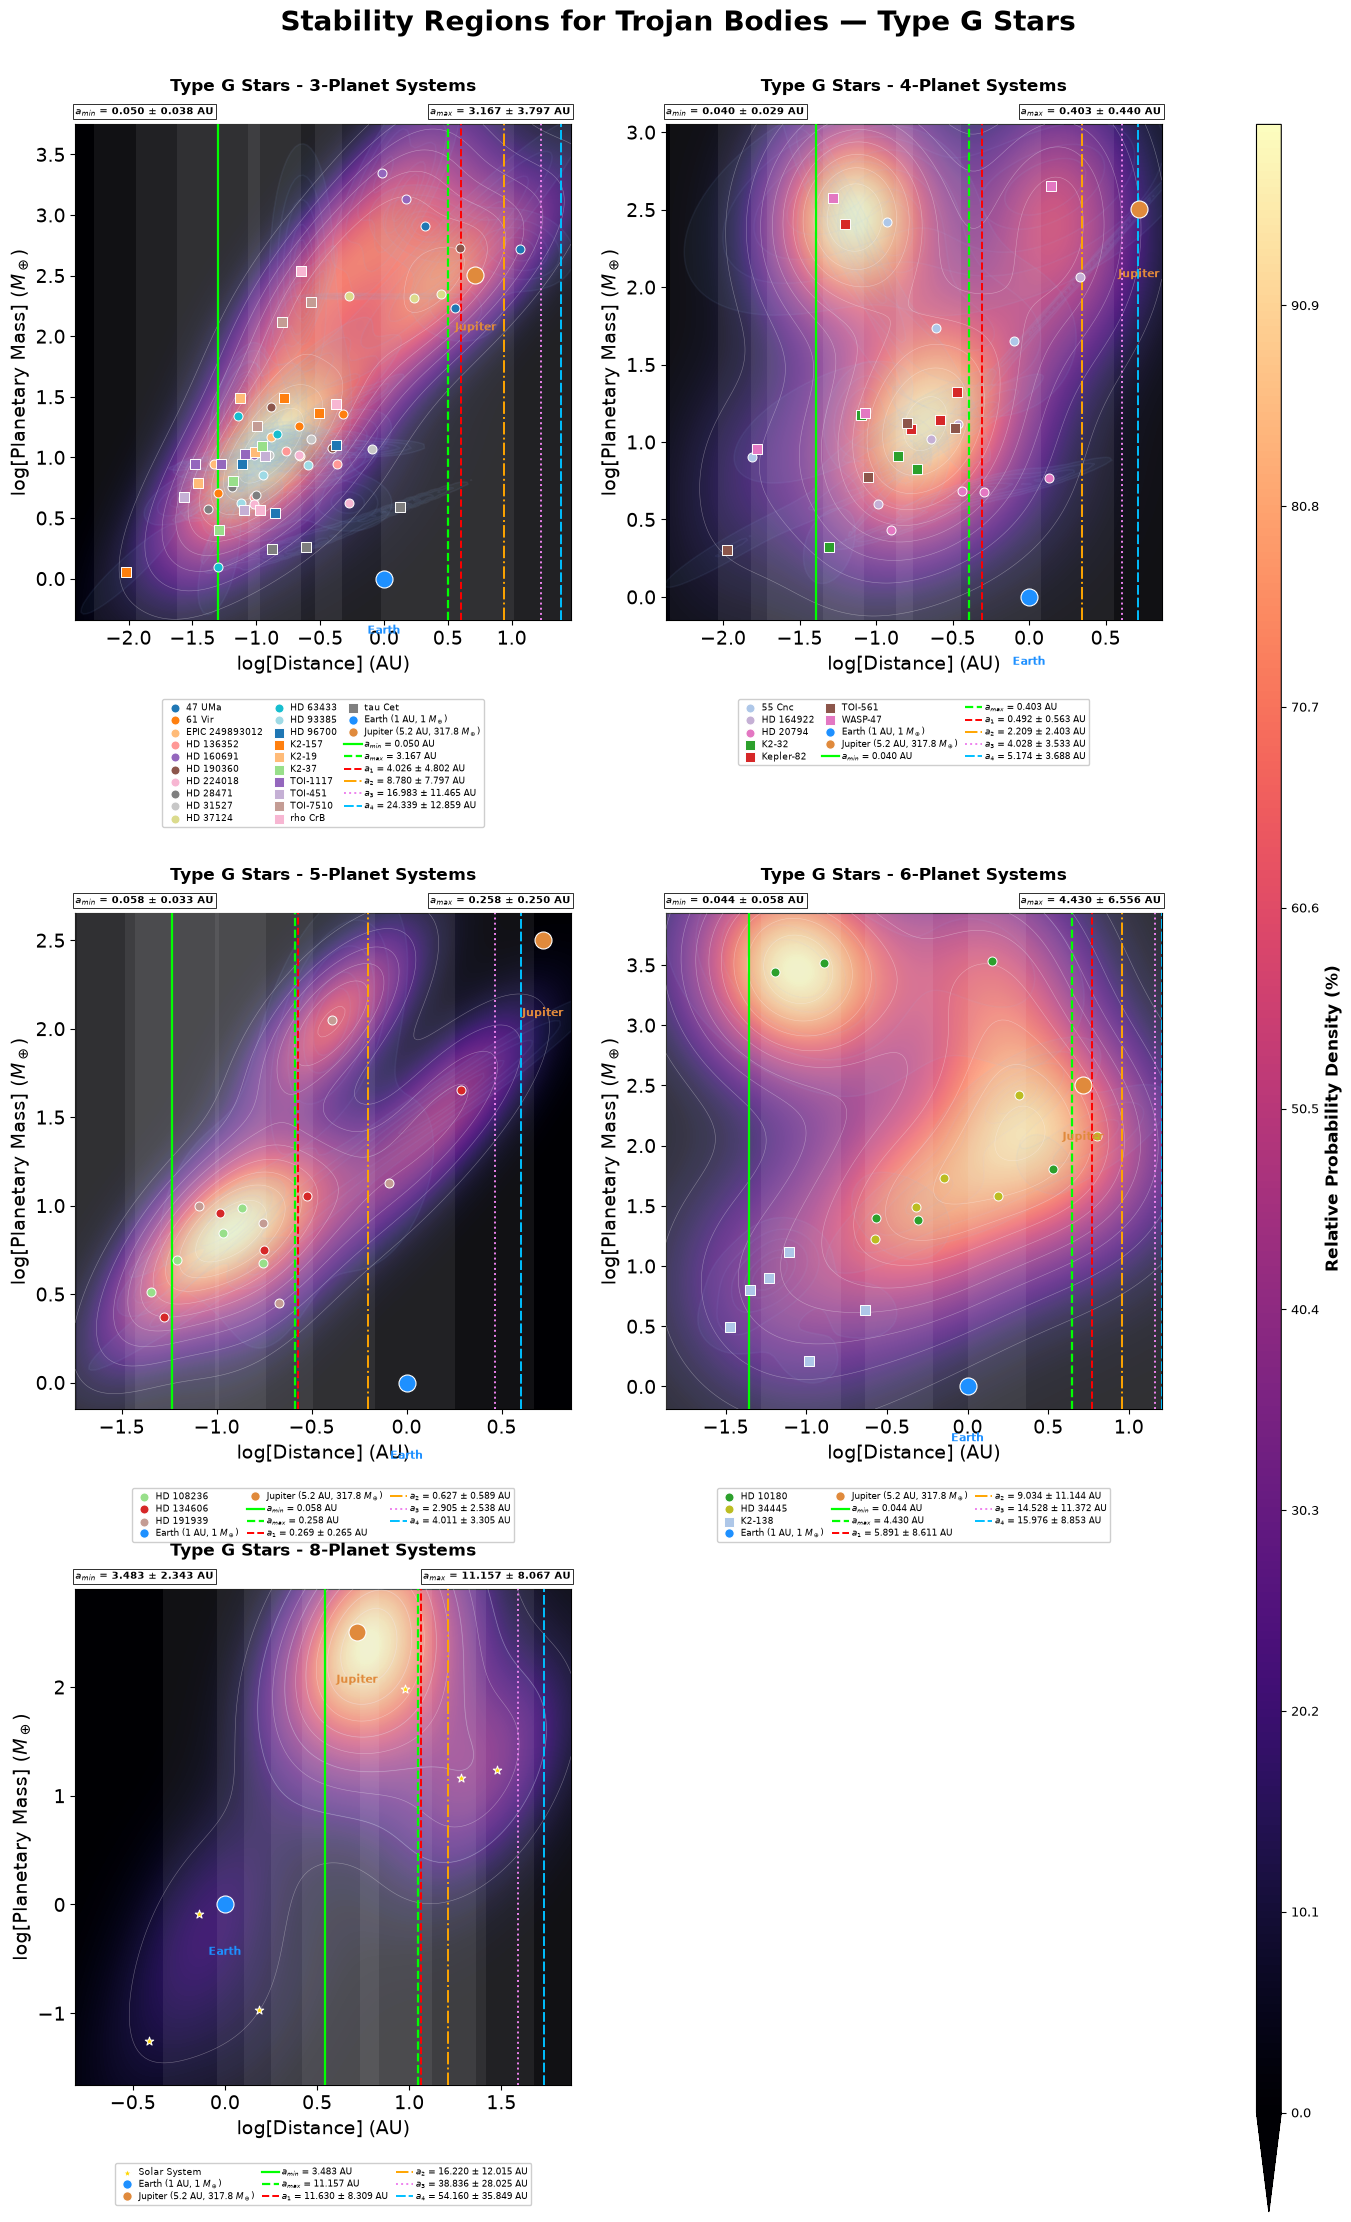

Intervalos σ guardados en: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_G\graficos_magma_con_sistemas_azules\intervalos_sigma_fraccion.csv
   Aviso: con 999 réplicas cada cola de 3σ queda apoyada en ~1.3 réplicas; el 3σ por percentil es poco fiable. Sube kde['n_bootstrap'] a 5000-10000 si lo vas a reportar.

Análisis del Sistema Solar frente a estrellas tipo G...


Planeta   a_UA  Masa_Mtierra  Area_Estable_km2  Densidad_rel_G_% Intervalo_barra_%  Percentil_en_planetas_G_%  a_min_G_UA  a_max_G_UA  Dentro_[a_min,a_max]  a_min-3σ_UA  a_max+3σ_UA  Dentro_[a_min-3σ,a_max+3σ]
  Earth  1.000        1.0000      2.590000e+13          2.818535          0.0-10.1                   0.000000    0.058212    1.607942                  True     0.025145     25.29556                        True
Jupiter  5.203      317.8000      6.820000e+15         52.761392         50.5-60.6                  28.225806    0.058212    1.607942                 False     0.025145     25.29556                        True
   Mars  1.524        0.1070      5.160000e+13          0.011131          0.0-10.1                   0.000000    0.058212    1.607942                  True     0.025145     25.29556                        True
Mercury  0.387        0.0553      3.010000e+12          0.017210          0.0-10.1                   0.000000    0.058212    1.607942                  True     

Comparación con/sin Sistema Solar guardada en: comparacion_G_con_sin_sistema_solar_fraccion.csv


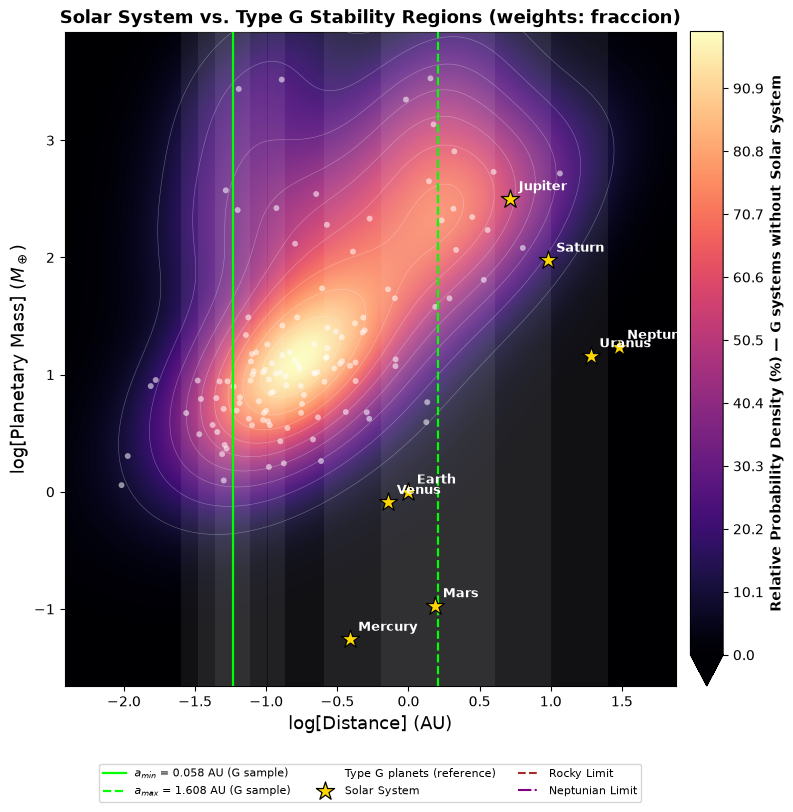

Gráficos guardados en: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_G\graficos_magma_con_sistemas_azules


In [3]:

import os
import re
import sys
import math
import json
import hashlib
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize, ListedColormap
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde
from scipy.interpolate import RegularGridInterpolator      # [NUEVO]
import tkinter as tk
from tkinter import filedialog, simpledialog, messagebox   # [MOD] + messagebox

try:
    from tqdm import tqdm  # pip install tqdm
except ImportError:
    def tqdm(iterable, total=None, desc=None, **kwargs):
        """
        Fallback mínimo si la librería 'tqdm' no está instalada: imprime el
        progreso como porcentaje sobre la misma línea de la terminal.
        """
        if total is None:
            try:
                total = len(iterable)
            except TypeError:
                total = None
        prefijo = f"{desc}: " if desc else ""
        for i, item in enumerate(iterable, start=1):
            yield item
            if total:
                pct = 100 * i / total
                print(f"\r{prefijo}{pct:5.1f}% ({i}/{total})", end="", flush=True)
        if total:
            print()


CONFIG = {
    # ------------------------------------------------------------------ general
    "general": {
        "carpeta_salida": "graficos_magma_con_sistemas_azules",  # dentro de la 1ª carpeta elegida
        "dpi": 300,
        "mostrar_figuras": True,            # False = solo guarda (útil sin pantalla)
        "tipos_espectrales": ("F", "G", "K", "M"),
        "max_carpetas": 10,                 # tope del diálogo de selección
        "marcadores": ["o", "s", "^", "D", "v", "p", "*", "h",
                       "H", "X", "d", "P", "<", ">"],
        "paleta_colores": "tab20",
        # [NUEVO] True = también genera la figura 2x2 "All systems — Type X"
        # (en la versión anterior ejecutar() nombraba la función pero no la llamaba).
        "generar_figura_por_tipo": False,
    },

    # ---------------------------------------------------------------------- KDE
    "kde": {
        "bw_method": 0.6,
        "grid_res": 150,                    # malla del KDE global de cada panel
        "grid_res_individual": 125,         # malla de cada sistema individual
        "grid_res_bootstrap": 150,          # malla de cada réplica bootstrap
        # Para intervalos de 3σ por percentil se recomienda >= 5000 réplicas
        # (con 1000, cada cola de 3σ queda apoyada en ~1 réplica).
        "n_bootstrap": 1000,                # réplicas por panel
        "semilla_bootstrap": None,          # entero para resultados reproducibles
        # Peso de cada planeta ("area" | "fraccion" | "neto"), ver _calcular_pesos
        # "fraccion" = A_est / (A_est + A_inest + A_colisión m2): usa las tres regiones.
        "modo_peso_islas": "fraccion",      # figuras por tipo y por multiplicidad general
        "modo_peso_matriz": "fraccion",     # figura F horizontal + G/K/M en 2x2
        # ejecutar() genera las figuras de F, G, K y M una vez por cada modo de esta lista
        # (cada modo con sus archivos, sufijo _<modo>); p. ej. ("area", "fraccion") compara.
        "modos_peso_figuras": ("fraccion",),
    },

    # ------------------------------------------------------------- caché (.txt)
    "cache": {
        "activo": True,
        "carpeta": "kde_cache",             # dentro de la carpeta de salida
        "forzar_recalculo": False,          # True = ignora los .txt y los reescribe
        "cachear_individuales": False,      # True = también un .txt por cada sistema
        "cachear_bootstrap": True,          # guarda las réplicas bootstrap (lo más lento)
    },

    # ------------------------------------------------------------------ colores
    "colores": {
        "cmap_global": "magma",             # densidad del conjunto completo
        "cmap_individual": "Blues",         # densidad de cada sistema individual
        "contorno_individual": "#8fb8ff",
        "color_limites_matriz": "lime",     # a_min / a_max en la figura matriz
        "color_limites_islas": "white",     # a_min / a_max en las figuras por tipo
        "color_banda_sigma": "white",
        "color_grid": "white",
    },

    # --------------------------------------------------------- orden de las capas
    "capas": {
        "alpha_global": 1.0,
        "zorder_global": 2.5,
        "estilo_global": "suave",
        "niveles_global": None,
        "lineas_bandas": True,
        "color_lineas_bandas": "white",
        "lw_lineas_bandas": 0.4,
        "alpha_lineas_bandas": 0.35,
        "zorder_individual_fill": 1.5,
        "dibujar_relleno_individual": True,
        "contornos_individuales_encima": False,
        "individuales_difusos_encima": True,
        "zorder_individual_fill_encima": 2.505,
        "zorder_individual_line_difuso": 2.505,
        "alpha_individual_fill_difuso": 0.05,
        "alpha_individual_line_difuso": 0.07,
        "zorder_individual_line_encima": 4.0,
        "zorder_individual_line_debajo": 1.7,
        "alpha_individual_fill": 0.95,
        "alpha_individual_line": 0.95,
        "niveles_individuales": (20.2, 40.4, 60.6, 80.8, 90.9, 100.0),
        "lw_contorno_individual": 1.1,
        "azul_recorte_inferior": 0.45,
        "zorder_grid": 3,
        "zorder_banda_sigma": 3,
        "zorder_lineas_limite": 6,
        "zorder_cajas_texto": 7,
        "zorder_puntos": 5,
        "zorder_puntos_matriz": 8,
        "zorder_referencias": 9,
        "zorder_tierra_islas": 10,
    },

    # ------------------------------------------------------ límites críticos a_*
    "limites": {
        "percentil_inf": 10,
        "percentil_sup": 98,
        "n_niveles_percentil": 25,
        "indice_umbral_percentil": -4,
        "nivel_region_estable": 90.9,
        "niveles_a1_a4": (70.7, 50.5, 30.3, 20.2),
        "lado_a1_a4": "derecho",
        "estilos_a1_a4": {
            "a_1": ("red", "--"),
            "a_2": ("orange", "-."),
            "a_3": ("violet", ":"),
            "a_4": ("deepskyblue", (0, (5, 1.5))),
        },
        "tick_max": 90.9,
        "n_ticks": 10,

        # [NUEVO] ---------------- incertidumbre 1σ / 2σ / 3σ ----------------
        # Qué k-sigma se calculan y se exportan a intervalos_sigma.csv
        "sigmas": (1, 2, 3),
        # Qué k-sigma se DIBUJAN como bandas sobre a_min / a_max (anidadas)
        "dibujar_sigmas": (1, 2, 3),
        # Cómo se construye la banda dibujada:
        #   "std"       : centro ± k·std(réplicas)  (consistente con el "±" de las cajas de texto)
        #   "percentil" : percentiles de las réplicas con cobertura gaussiana de k·σ
        #                 (68.27 %, 95.45 %, 99.73 %); no asume normalidad.
        "metodo_sigma_dibujo": "std",
        "alpha_banda_sigma": 0.07,          # alpha de cada banda cuando se dibuja más de una
    },

    # --------------------------------------------------------------- referencias
    "referencias": {
        "jupiter_ua": 5.2,
        "jupiter_masa": 317.8,
        "color_tierra": "#1e90ff",
        "color_jupiter": "#e08a3c",
        "limite_rocoso_masa": 2.0,
        "limite_neptuniano_masa": 10.0,
        "color_rocoso": "brown",
        "color_neptuniano": "purple",
        "etiqueta_tierra_islas": r"Earth (1 AU, 1 $M_\oplus$, $A_{stab}=1.27 \times 10^{13}$ km$^2$)",
    },

    # [NUEVO] ------------------------------------------------------ Sistema Solar
    "sistema_solar": {
        "activo": True,
        "preguntar": True,                  # True = pregunta con un diálogo si incluirlo
        "tipo_estrella": "G",
        "nombre_sistema": "Solar System",
        # "config"  : usa la tabla de "planetas" de abajo (necesita las áreas estables)
        # "carpeta" : escanea una carpeta con la MISMA estructura (resumen.txt + README.txt)
        #             que tus simulaciones; es la opción recomendada si ya lo simulaste.
        "fuente": "config",
        "n_planetas_total": 8,              # multiplicidad con la que aparece el Sistema Solar
        "marcador": "*", "color": "gold",
        # nombre: (a [UA], masa [M_tierra], A_estable, A_inestable, A_colisión_m2 [km²],
        #          zonas_estables, zonas_inestables, zonas_colisión_m2)
        # Datos de tus tablas Sol-Planeta (colisión con m1 = 0 en todos los casos).
        # Un A_estable None se omite con un aviso.
        "planetas": {
            "Mercury": (0.387, 0.0553, 3.01e12, 5.33e14, 2.15e12,  56, 9904, 40),
            "Venus":   (0.723, 0.815,  1.27e13, 1.85e15, 4.29e12,  68, 9909, 23),
            "Earth":   (1.000, 1.000,  2.59e13, 3.57e15, 7.92e12,  72, 9906, 22),
            "Mars":    (1.524, 0.107,  5.16e13, 8.24e15, 2.58e13,  62, 9907, 31),
            "Jupiter": (5.203, 317.8,  6.82e15, 9.00e16, 9.68e12, 704, 9295,  1),
            "Saturn":  (9.537, 95.16,  1.29e16, 3.13e17, 2.61e14, 397, 9595,  8),
            "Uranus":  (19.19, 14.54,  2.03e16, 1.30e18, 1.85e15, 154, 9832, 14),
            "Neptune": (30.07, 17.15,  5.57e16, 3.18e18, 4.53e15, 172, 9814, 14),
        },
        # KDE del Sistema Solar por sí solo (analizar_kde_sistema_solar / ejecutar_sistema_solar)
        "kde_solo": {
            "carpeta": "graficos_sistema_solar",   # dentro del directorio de trabajo
            "figura": "KDE_Sistema_Solar",
            # Peso de cada planeta (ver _calcular_pesos):
            #   "area"     : log10(A_estable + 1)                     (solo regiones estables)
            #   "fraccion" : A_est / (A_est + A_inest + A_colisión m2) (usa inestables y colisión)
            #   "neto"     : log10(max(A_est - (A_inest + A_col), 0) + 1)
            # ejecutar_sistema_solar() corre todos los de "modos_peso".
            "modo_peso": "fraccion",
            "modos_peso": ("area", "fraccion", "neto"),
            "criterio_limites": None,              # None = el de fig_matriz; "percentil" | "nivel"
            "margen": 0.5,                         # holgura de ejes (dex)
            "n_bootstrap": 5000,                   # sube la fiabilidad del 3σ por percentil
            "csv_planetas": "kde_sistema_solar_planetas.csv",
            "csv_sigma": "kde_sistema_solar_intervalos_sigma.csv",
        },
        "analisis": {
            "margen": 0.4,                  # holgura de ejes (dex) en la figura de comparación
            "csv_planetas": "analisis_sistema_solar_planetas.csv",
            "csv_comparacion": "comparacion_G_con_sin_sistema_solar.csv",
            "figura": "Solar_System_vs_G_Type",
            "comparar_con_y_sin": True,     # recalcula a_* de G con y sin el Sistema Solar
        },
    },

    # ---------------------------------------------- paneles (figuras por tipo/mult.)
    "panel_islas": {
        "titulo_fs": 18, "titulo_pad": 15,
        "label_fs": 14,
        "tick_fs": 14,
        "cbar_label_fs": 12, "cbar_tick_fs": 10,
        "cbar_pad": 0.02, "cbar_aspect": 35, "cbar_fraction": 0.046,
        "texto_limite_fs": 11, "texto_dx": 0.05, "texto_y": 0.92,
        "lw_limite": 2.5, "alpha_banda": 0.15,
        "marker_size": 110, "marker_edge_lw": 1.0,
        "tierra_size": 400, "tierra_edge_lw": 1.2,
        "grid_alpha": 0.3,
        "leyenda_bbox": (0.5, -0.14),
        "leyenda_tramos": ((20, 4, 8.5), (10, 3, 9.5), (5, 2, 10)),
        "leyenda_defecto": (1, 10.5),
        "leyenda_refs_fs": 10.5,
    },

    # --------------------------------------------------------- figura por tipo (2x2)
    "fig_tipo": {
        "ncols": 2,
        "ancho": 17.0, "alto_por_fila": 11.5,
        "suptitle_fs": 26, "suptitle_y": 0.99,
        "rect": (0, 0, 1, 0.96),
        "hspace": 0.65, "wspace": 0.28,
        "margen_ejes": 0.4,
    },

    # ------------------------------------------------ figura horizontal multiplicidad
    "fig_horizontal": {
        "ancho_por_panel": 7.8, "alto": 10.0,
        "suptitle_fs": 26, "suptitle_y": 0.99,
        "rect": (0, 0, 1, 0.95),
        "margen_ejes": 0.4,
    },

    # --------------------------------- figura matriz (F en fila, G/K/M en 2 columnas)
    "fig_matriz": {
        "tipo_en_fila": "F",
        "ncols_resto": 2,
        "ancho_por_panel": 6.0, "ancho_extra": 1.4,
        "alto_base": 6.0, "alto_por_fila_leyenda": 0.2, "alto_extra": 1.0,
        "margen_sup_in": 1.3,
        "suptitle_fs": 20, "suptitle_dy_in": 0.15,
        "cbar_ancho_ratio": 0.05,
        "left": 0.05, "right": 0.95, "bottom": 0.01,
        "hspace": 0.05, "wspace": 0.28,
        "cbar_label_fs": 12, "cbar_tick_fs": 9,
        "criterio_limites": "percentil",    # "percentil" | "nivel"
        "limites_por_panel": True,
        "margen_panel": 0.4,
        "holgura_tierra": 0.15, "holgura_jupiter": 0.15,
        "margen_x_comun": 0.4, "margen_y_inf_comun": 0.8, "margen_y_sup_comun": 0.5,
    },

    # -------------------------------------------------------------- panel matriz
    "panel_matriz": {
        "titulo_fs": 12, "titulo_pad": 24,
        "label_fs": 14, "tick_fs": 14,
        "lw_limite": 1.6, "lw_a": 1.4, "lw_extra": 1.4,
        "alpha_banda": 0.15,
        "caja_fs": 7.5, "caja_alpha": 0.95, "caja_borde_lw": 0.6, "caja_y": 1.015,
        "marker_size": 42, "marker_edge_lw": 0.7,
        "tierra_size": 150, "ref_edge_lw": 0.8, "ref_texto_fs": 8, "ref_texto_dy": 0.38,
        "ref_leyenda_ms": 7,
        "grid_alpha": 0.15,
        "leyenda_fs": 6.3, "leyenda_bbox": (0.5, -0.15), "leyenda_framealpha": 0.95,
        "leyenda_umbral_ncol": 8, "leyenda_ncol_chica": 2, "leyenda_ncol_grande": 3,
        "leyenda_handletextpad": 0.3, "leyenda_columnspacing": 0.8,
        "leyenda_borderpad": 0.4, "leyenda_labelspacing": 0.25,
    },
}


_ESTADO = {"base_dir": None}   # carpeta de salida (la fija ejecutar() o cada plot_*)


def _fijar_base(base_dir):
    _ESTADO["base_dir"] = base_dir


def _safe_log10(x):
    """log10 blindado: retorna log10(x + 1) para evitar log(0) = -inf."""
    return np.log10(np.asarray(x, dtype=float) + 1.0)


def _ticks_barra():
    lim = CONFIG["limites"]
    return np.linspace(0.0, lim["tick_max"], lim["n_ticks"])


def _mostrar_o_cerrar(fig):
    if CONFIG["general"]["mostrar_figuras"]:
        plt.show()
    plt.close(fig)


def _asignar_estilos_sistema(df: pd.DataFrame) -> dict:
    """
    Genera combinaciones únicas de marcador/color para cada sistema estelar.
    Devuelve un dict {nombre_sistema: {'marker': ..., 'color': ...}}.
    [MOD] El Sistema Solar siempre se dibuja con su estilo propio (estrella dorada).
    """
    g = CONFIG["general"]
    if "Sistema" not in df.columns:
        df = df.copy()
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])

    sistemas_unicos = df["Sistema"].unique()
    colores_base = plt.get_cmap(g["paleta_colores"]).colors
    combinaciones = itertools.product(g["marcadores"], colores_base)

    estilos = {}
    for sist, (marker, color) in zip(sistemas_unicos, combinaciones):
        estilos[sist] = {"marker": marker, "color": color}

    ss = CONFIG["sistema_solar"]
    if ss["activo"] and ss["nombre_sistema"] in estilos:
        estilos[ss["nombre_sistema"]] = {"marker": ss["marcador"], "color": ss["color"]}
    return estilos


def _calcular_limites_criticos(Z_pct: np.ndarray, X: np.ndarray):
    """
    Dado el campo de densidad KDE normalizado en porcentaje (0 a 100%) y su malla X,
    determina los límites críticos de la región más estable (criterio "percentil").
    """
    lim = CONFIG["limites"]
    Z_flat = Z_pct.flatten()
    niveles = np.linspace(np.percentile(Z_flat, lim["percentil_inf"]),
                          np.percentile(Z_flat, lim["percentil_sup"]),
                          lim["n_niveles_percentil"])
    umbral = niveles[lim["indice_umbral_percentil"]]
    x_alta_densidad = X[np.where(Z_pct >= umbral)]
    if len(x_alta_densidad) == 0:
        return None, None
    return float(np.min(x_alta_densidad)), float(np.max(x_alta_densidad))


# ---------------------------------------------------------------------------
# [NUEVO] INTERVALOS 1σ / 2σ / 3σ A PARTIR DEL BOOTSTRAP
# ---------------------------------------------------------------------------
def _cobertura_gauss(k):
    """Cobertura de una gaussiana en ±kσ: 0.6827, 0.9545, 0.9973 para k = 1, 2, 3."""
    return math.erf(k / math.sqrt(2.0))


def _intervalo_sigma(valores_log, k, central=None, metodo=None):
    """
    Intervalo k-sigma (en log10 UA) de un límite a partir de sus réplicas bootstrap.
      "std"       : central ± k·std(réplicas)
      "percentil" : percentiles de las réplicas con la cobertura gaussiana de k·σ
    Devuelve (inf_log, sup_log) o None si hay menos de 5 réplicas válidas.
    """
    v = np.asarray(valores_log, dtype=float)
    v = v[np.isfinite(v)]
    if v.size < 5:
        return None
    metodo = metodo or CONFIG["limites"]["metodo_sigma_dibujo"]
    if metodo == "std":
        c = float(np.mean(v)) if central is None else float(central)
        s = float(np.std(v))
        return c - k * s, c + k * s
    cob = _cobertura_gauss(k)
    lo, hi = np.percentile(v, [50.0 * (1.0 - cob), 50.0 * (1.0 + cob)])
    return float(lo), float(hi)


def _dibujar_bandas_sigma(ax, valores_log, central, color, zorder, alpha_unico):
    """Bandas anidadas k-sigma (las más anchas primero). Con un solo k usa alpha_unico."""
    lim = CONFIG["limites"]
    ks = sorted(lim["dibujar_sigmas"], reverse=True)
    alpha = alpha_unico if len(ks) == 1 else lim["alpha_banda_sigma"]
    for k in ks:
        iv = _intervalo_sigma(valores_log, k, central)
        if iv is not None:
            ax.axvspan(iv[0], iv[1], color=color, alpha=alpha, zorder=zorder, linewidth=0)


def _filas_sigma(contexto: dict, boot: dict, ks=None):
    """
    boot: {nombre_limite: (centro_log10, réplicas_log10)}.
    Devuelve filas en formato largo con los intervalos k-sigma por ambos métodos
    ("std" y "percentil"), para comparar y detectar no-gaussianidad.
    """
    ks = ks or CONFIG["limites"]["sigmas"]
    filas = []
    for nombre, (central, vals) in boot.items():
        v = np.asarray(vals, dtype=float)
        v = v[np.isfinite(v)]
        if central is None or v.size < 5:
            continue
        valor_ua = 10 ** central
        sigma_ua = valor_ua * np.log(10) * float(np.std(v))
        for metodo in ("std", "percentil"):
            for k in ks:
                iv = _intervalo_sigma(v, k, central, metodo)
                filas.append({**contexto,
                              "Limite": nombre, "Valor_UA": valor_ua,
                              "Sigma_std_UA": sigma_ua, "N_replicas": int(v.size),
                              "Metodo": metodo, "k_sigma": k,
                              "Cobertura_%": 100.0 * _cobertura_gauss(k),
                              "Inf_UA": 10 ** iv[0], "Sup_UA": 10 ** iv[1]})
    return filas


def _con_sufijo(nombre, sufijo):
    """'archivo.png' + '_fraccion' -> 'archivo_fraccion.png'."""
    base, ext = os.path.splitext(nombre)
    return f"{base}{sufijo}{ext}"


def _guardar_tabla_sigma(filas, ruta):
    if not filas:
        return
    pd.DataFrame(filas).to_csv(ruta, index=False, encoding="utf-8-sig")
    n_rep = min(f["N_replicas"] for f in filas)
    ks = CONFIG["limites"]["sigmas"]
    if max(ks) >= 3:
        cola = n_rep * (1 - _cobertura_gauss(3)) / 2
        print(f"Intervalos σ guardados en: {ruta}")
        if cola < 10:
            print(f"   Aviso: con {n_rep} réplicas cada cola de 3σ queda apoyada en ~{cola:.1f} "
                  f"réplicas; el 3σ por percentil es poco fiable. Sube kde['n_bootstrap'] "
                  f"a 5000-10000 si lo vas a reportar.")


# ---------------------------------------------------------------------------
# CACHÉ EN .TXT (mallas KDE y réplicas bootstrap)
# ---------------------------------------------------------------------------
def _dir_cache():
    base = _ESTADO["base_dir"] or os.getcwd()
    ruta = os.path.join(base, CONFIG["cache"]["carpeta"])
    os.makedirs(ruta, exist_ok=True)
    return ruta


def _slug(texto):
    return re.sub(r"[^A-Za-z0-9]+", "_", str(texto)).strip("_")[:80] or "panel"


def _clave_cache(*arrays, **params):
    """
    Hash corto de los datos de entrada + parámetros. Si cambian los datos o
    algún parámetro (bw, malla, límites...), cambia el nombre del .txt y se
    recalcula solo; así nunca se carga una malla desactualizada.
    """
    h = hashlib.md5()
    for a in arrays:
        h.update(np.ascontiguousarray(a, dtype=float).tobytes())
    h.update(json.dumps(params, sort_keys=True, default=str).encode("utf-8"))
    return h.hexdigest()[:10]


def guardar_malla_txt(ruta, X, Y, Z):
    """Guarda X, Y, Z (mallas 2D) en un .txt de 3 columnas: X, Y, Z."""
    datos = np.column_stack([X.ravel(), Y.ravel(), Z.ravel()])
    cabecera = (f"shape {X.shape[0]} {X.shape[1]}\n"
                "columnas: X=log10(Distancia/UA)  Y=log10(Masa/M_tierra)  Z=densidad relativa (%)")
    np.savetxt(ruta, datos, fmt="%.8e", header=cabecera)


def cargar_malla_txt(ruta):
    """Lee un .txt escrito por guardar_malla_txt y devuelve X, Y, Z con su forma 2D."""
    with open(ruta, "r", encoding="utf-8") as f:
        primera = f.readline()
    _, n0, n1 = primera.lstrip("# ").split()
    forma = (int(n0), int(n1))
    datos = np.loadtxt(ruta)
    return (datos[:, 0].reshape(forma),
            datos[:, 1].reshape(forma),
            datos[:, 2].reshape(forma))


def obtener_malla_kde(x, y, weights, xlims, ylims, res, etiqueta, individual=False):
    """
    Devuelve (X, Y, Z_pct) con Z normalizado a 0-100 %.
    1) Si existe el .txt de caché correspondiente, lo carga.
    2) Si no, calcula el KDE y escribe el .txt.
    """
    cfg = CONFIG["cache"]
    bw = CONFIG["kde"]["bw_method"]
    X, Y = np.mgrid[xlims[0]:xlims[1]:complex(0, res),
                    ylims[0]:ylims[1]:complex(0, res)]

    usar_cache = cfg["activo"] and (cfg["cachear_individuales"] or not individual)
    ruta = None
    if usar_cache:
        clave = _clave_cache(x, y, weights, xlims=list(xlims), ylims=list(ylims),
                             res=res, bw=bw)
        ruta = os.path.join(_dir_cache(), f"kde_{_slug(etiqueta)}_{clave}.txt")
        if os.path.isfile(ruta) and not cfg["forzar_recalculo"]:
            try:
                Xc, Yc, Zc = cargar_malla_txt(ruta)
                if Zc.shape == X.shape:
                    return Xc, Yc, Zc
            except Exception as exc:
                print(f"Aviso: caché ilegible ({os.path.basename(ruta)}): {exc}. Se recalcula.")

    kde = gaussian_kde(np.vstack([x, y]), weights=weights, bw_method=bw)
    Z = np.reshape(kde(np.vstack([X.ravel(), Y.ravel()])), X.shape)
    if Z.max() > 0:
        Z = (Z / Z.max()) * 100.0

    if ruta is not None:
        guardar_malla_txt(ruta, X, Y, Z)
    return X, Y, Z


# ---------------------------------------------------------------------------
# BOOTSTRAP DE LÍMITES
# ---------------------------------------------------------------------------
def _limites_por_nivel(Z_pct: np.ndarray, X: np.ndarray, nivel: float):
    """Mínimo y máximo de log(distancia) donde la densidad relativa >= nivel (%)."""
    xs = X[Z_pct >= nivel]
    if xs.size == 0:
        return None, None
    return float(xs.min()), float(xs.max())


def _borde_nivel(Z_pct, X, nivel, lado="derecho"):
    """log10(distancia) del borde izquierdo o derecho de la región con densidad >= nivel."""
    lo, hi = _limites_por_nivel(Z_pct, X, nivel)
    return hi if lado == "derecho" else lo


def _limites_segun_criterio(Z_pct, X, criterio):                       # [NUEVO]
    if criterio == "percentil":
        return _calcular_limites_criticos(Z_pct, X)
    return _limites_por_nivel(Z_pct, X, CONFIG["limites"]["nivel_region_estable"])


def _bootstrap_limites_multi(x, y, weights, xlims, ylims, niveles_a, lado=None,
                             criterio="nivel", etiqueta="panel"):
    """
    Un único bootstrap por panel que estima a la vez la incertidumbre de
    a_min / a_max y de los bordes a_1..a_4 (niveles de densidad).
    Devuelve (dict_min_max, dict_a) con listas de log10(UA) por réplica.
    Los resultados se guardan/cargan en .txt (CONFIG["cache"]["cachear_bootstrap"]).
    """
    kcfg, ccfg, lim = CONFIG["kde"], CONFIG["cache"], CONFIG["limites"]
    lado = lado or lim["lado_a1_a4"]
    n_boot, res_b, bw = kcfg["n_bootstrap"], kcfg["grid_res_bootstrap"], kcfg["bw_method"]
    nombres_a = list(lim["estilos_a1_a4"].keys())
    columnas = ["min", "max"] + nombres_a

    ruta = None
    if ccfg["activo"] and ccfg["cachear_bootstrap"]:
        clave = _clave_cache(x, y, weights, xlims=list(xlims), ylims=list(ylims),
                             niveles=list(niveles_a) if niveles_a else None,
                             lado=lado, criterio=criterio, n=n_boot, res=res_b, bw=bw,
                             semilla=kcfg["semilla_bootstrap"],
                             nivel_estable=lim["nivel_region_estable"],
                             perc=[lim["percentil_inf"], lim["percentil_sup"],
                                   lim["n_niveles_percentil"], lim["indice_umbral_percentil"]])
        ruta = os.path.join(_dir_cache(), f"bootstrap_{_slug(etiqueta)}_{clave}.txt")
        if os.path.isfile(ruta) and not ccfg["forzar_recalculo"]:
            try:
                M = np.loadtxt(ruta, ndmin=2)
                listas = {c: M[:, i][~np.isnan(M[:, i])].tolist()
                          for i, c in enumerate(columnas)}
                return ({"min": listas["min"], "max": listas["max"]},
                        {a: listas[a] for a in nombres_a})
            except Exception as exc:
                print(f"Aviso: caché bootstrap ilegible ({os.path.basename(ruta)}): {exc}.")

    rng = np.random.default_rng(kcfg["semilla_bootstrap"])
    n = len(x)
    out_mm = {"min": [], "max": []}
    out_a = {a: [] for a in nombres_a}

    Xb, Yb = np.mgrid[xlims[0]:xlims[1]:complex(0, res_b),
                      ylims[0]:ylims[1]:complex(0, res_b)]
    pos_b = np.vstack([Xb.ravel(), Yb.ravel()])

    for _ in tqdm(range(n_boot), desc="   Bootstrap límites", leave=False, unit="rep"):
        idx = rng.integers(0, n, size=n)
        x_b, y_b, w_b = x[idx], y[idx], weights[idx]
        if x_b.var() < 1e-12 or y_b.var() < 1e-12 or w_b.sum() <= 0:
            continue
        try:
            kde_b = gaussian_kde(np.vstack([x_b, y_b]), weights=w_b, bw_method=bw)
            Z_b = np.reshape(kde_b(pos_b), Xb.shape)
            if Z_b.max() > 0:
                Z_b = (Z_b / Z_b.max()) * 100.0
        except (np.linalg.LinAlgError, ValueError):
            continue

        if criterio == "percentil":
            lo, hi = _calcular_limites_criticos(Z_b, Xb)
        else:
            lo, hi = _limites_por_nivel(Z_b, Xb, lim["nivel_region_estable"])
        if lo is not None:
            out_mm["min"].append(lo)
            out_mm["max"].append(hi)

        if niveles_a:
            bordes = [_borde_nivel(Z_b, Xb, nv, lado) for nv in niveles_a]
            if None not in bordes:
                for nombre, b in zip(nombres_a, bordes):
                    out_a[nombre].append(b)

    if ruta is not None:
        listas = {**out_mm, **out_a}
        largo = max((len(v) for v in listas.values()), default=0)
        if largo > 0:
            M = np.full((largo, len(columnas)), np.nan)
            for i, c in enumerate(columnas):
                M[:len(listas[c]), i] = listas[c]
            np.savetxt(ruta, M, fmt="%.10e", header=" ".join(columnas))

    return out_mm, out_a


def _bootstrap_limites_criticos(x, y, weights, xlims, ylims, etiqueta="panel"):
    """Bootstrap solo de a_min / a_max con el criterio original ("percentil")."""
    mm, _ = _bootstrap_limites_multi(x, y, weights, xlims, ylims, None,
                                     criterio="percentil", etiqueta=etiqueta)
    return mm["min"], mm["max"]


# ---------------------------------------------------------------------------
# EXTRACCIÓN DE DATOS
# ---------------------------------------------------------------------------
def _escanear_directorio(directorio_raiz, tipo_estrella):
    """
    [NUEVO: extraído de extraer_datos_personalizados para reutilizarlo con el Sistema Solar]
    Escanea una carpeta (os.walk) buscando pares resumen.txt + README*.txt y
    devuelve una lista de registros (dicts), uno por planeta.
    """
    registros = []
    for root, dirs, files in os.walk(directorio_raiz):
        resumen_file = None
        readme_file = None

        for file in files:
            if file.endswith(" resumen.txt") or file.endswith("_resumen.txt"):
                resumen_file = file
            elif file.startswith("README") and file.endswith(".txt"):
                readme_file = file

        if resumen_file and readme_file:
            nombre_planeta = os.path.basename(root).replace("_", " ")
            nombre_sistema = os.path.basename(os.path.dirname(root)).replace("_", " ")

            ruta_resumen = os.path.join(root, resumen_file)
            ruta_readme = os.path.join(root, readme_file)

            try:
                # 1. LEER RESUMEN
                with open(ruta_resumen, 'r', encoding='utf-8', errors='ignore') as f:
                    contenido_resumen = f.read()

                z_est_match = re.search(r'Total estables:\s*(\d+)', contenido_resumen, re.IGNORECASE)
                z_inest_match = re.search(r'Total inestables:\s*(\d+)', contenido_resumen, re.IGNORECASE)
                z_m1_match = re.search(r'Total colisi[oó]n m1:\s*(\d+)', contenido_resumen, re.IGNORECASE)
                z_m2_match = re.search(r'Total colisi[oó]n m2:\s*(\d+)', contenido_resumen, re.IGNORECASE)

                z_est = int(z_est_match.group(1)) if z_est_match else 0
                z_inest = int(z_inest_match.group(1)) if z_inest_match else 0
                z_m1 = int(z_m1_match.group(1)) if z_m1_match else 0
                z_m2 = int(z_m2_match.group(1)) if z_m2_match else 0

                a_est_match = re.search(r'[AÁaá]rea estable:\s*([0-9.,eE+-]+)', contenido_resumen, re.IGNORECASE)
                a_inest_match = re.search(r'[AÁaá]rea inestable:\s*([0-9.,eE+-]+)', contenido_resumen, re.IGNORECASE)
                a_col_match = re.search(r'[AÁaá]rea.*colisi[oó]n.*m2:\s*([0-9.,eE+-]+)', contenido_resumen, re.IGNORECASE)

                a_est = float(a_est_match.group(1).replace(',', '.')) if a_est_match else 0.0
                a_inest = float(a_inest_match.group(1).replace(',', '.')) if a_inest_match else 0.0
                a_col = float(a_col_match.group(1).replace(',', '.')) if a_col_match else 0.0

                # 2. LEER README
                with open(ruta_readme, 'r', encoding='utf-8', errors='ignore') as f:
                    contenido_readme = f.read()

                dist_match = re.search(r'Semi-eje mayor.*:\s*([0-9.,eE+-]+)', contenido_readme, re.IGNORECASE)
                masa_p_match = re.search(r'Masa del Planeta.*:\s*([0-9.,eE+-]+)', contenido_readme, re.IGNORECASE)
                masa_e_match = re.search(r'Masa de.*estrella.*:\s*([0-9.,eE+-]+)', contenido_readme, re.IGNORECASE)

                distancia = float(dist_match.group(1).replace(',', '.')) if dist_match else 0.0
                masa_planeta = float(masa_p_match.group(1).replace(',', '.')) if masa_p_match else 0.0
                masa_estel = float(masa_e_match.group(1).replace(',', '.')) if masa_e_match else 1.0

                registros.append({
                    "Sistema": nombre_sistema,
                    "Planeta": nombre_planeta,
                    "Tipo_Estrella": tipo_estrella,
                    "Distancia_UA": distancia,
                    "Masa_Tierra": masa_planeta,
                    "Masa_Estrella": masa_estel,
                    "Num_Planetas": 0,
                    "Zonas Estables": z_est,
                    "Zonas Inestables": z_inest,
                    "Zonas Colisión m1": z_m1,
                    "Zonas Colisión m2": z_m2,
                    "Area_Estable_km2": a_est,
                    "Area_Inestable": a_inest,
                    "Area_Colision_m2": a_col
                })
            except Exception as e:
                print(f"❌ Error interno procesando {nombre_planeta}: {e}")
    return registros


def extraer_datos_personalizados():
    """
    Combina la selección manual de carpetas con el escaneo profundo
    usando expresiones regulares para extraer parámetros físicos y estabilidad.
    """
    root_tk = tk.Tk()
    root_tk.withdraw()
    root_tk.attributes("-topmost", True)

    num_carpetas = simpledialog.askinteger(
        "Cantidad de carpetas",
        "¿Cuántas carpetas principales vas a seleccionar en total?",
        minvalue=1, maxvalue=CONFIG["general"]["max_carpetas"], parent=root_tk
    )

    if not num_carpetas:
        root_tk.destroy()
        return pd.DataFrame(), ""

    datos_recopilados = []
    primer_directorio = ""

    for i in range(num_carpetas):
        tipo_estrella = simpledialog.askstring(
            "Tipo de Estrella",
            f"Carpeta {i+1} de {num_carpetas}:\n¿Qué tipo de estrella contiene? (Ej: F, G, K, M)",
            parent=root_tk
        )

        if not tipo_estrella:
            root_tk.destroy()
            return pd.DataFrame(), ""

        tipo_estrella = tipo_estrella.upper().strip()
        directorio_raiz = filedialog.askdirectory(
            title=f"Selecciona la carpeta para los datos de estrellas {tipo_estrella}",
            parent=root_tk
        )

        if not directorio_raiz:
            root_tk.destroy()
            return pd.DataFrame(), ""

        if i == 0:
            primer_directorio = directorio_raiz

        print(f"\n🔍 Escaneando directorio: {directorio_raiz} (Tipo {tipo_estrella})...")
        datos_recopilados += _escanear_directorio(directorio_raiz, tipo_estrella)

    root_tk.destroy()
    df_resultados = pd.DataFrame(datos_recopilados)
    if not df_resultados.empty:
        df_resultados["Num_Planetas"] = df_resultados.groupby(["Tipo_Estrella", "Sistema"])["Planeta"].transform("nunique")
        df_resultados = df_resultados.sort_values(by=["Sistema", "Planeta"]).reset_index(drop=True)
        print(f"✅ Lectura completada. Se extrajeron datos de {len(df_resultados)} planetas.")

    return df_resultados, primer_directorio


# ---------------------------------------------------------------------------
# [NUEVO] SISTEMA SOLAR
# ---------------------------------------------------------------------------
def construir_sistema_solar(fuente=None):
    """
    Devuelve un DataFrame con los planetas del Sistema Solar en el mismo formato
    que extraer_datos_personalizados().
      fuente "config"  : usa CONFIG["sistema_solar"]["planetas"]; omite los que no
                         tienen Area_Estable_km2 (se avisa por consola).
      fuente "carpeta" : pide una carpeta con la estructura de tus simulaciones.
    """
    ss = CONFIG["sistema_solar"]
    nombre, tipo = ss["nombre_sistema"], ss["tipo_estrella"]
    fuente = fuente or ss["fuente"]
    registros = []

    if fuente == "carpeta":
        root_tk = tk.Tk()
        root_tk.withdraw()
        root_tk.attributes("-topmost", True)
        directorio = filedialog.askdirectory(
            title="Selecciona la carpeta de simulaciones del Sistema Solar", parent=root_tk)
        root_tk.destroy()
        if not directorio:
            return pd.DataFrame()
        print(f"\n🔍 Escaneando Sistema Solar en: {directorio}...")
        for r in _escanear_directorio(directorio, tipo):
            r["Sistema"] = nombre
            registros.append(r)
    else:
        omitidos = []
        for pl, (a, m, area, a_in, a_col, z_e, z_i, z_c) in ss["planetas"].items():
            if area is None or area <= 0:
                omitidos.append(pl)
                continue
            registros.append({
                "Sistema": nombre, "Planeta": f"{nombre} {pl}", "Tipo_Estrella": tipo,
                "Distancia_UA": float(a), "Masa_Tierra": float(m), "Masa_Estrella": 1.0,
                "Num_Planetas": ss["n_planetas_total"],
                "Zonas Estables": z_e, "Zonas Inestables": z_i,
                "Zonas Colisión m1": 0, "Zonas Colisión m2": z_c,
                "Area_Estable_km2": float(area), "Area_Inestable": float(a_in),
                "Area_Colision_m2": float(a_col),
            })
        if omitidos:
            print("⚠️  Sistema Solar: sin Area_Estable_km2 en CONFIG para "
                  f"{', '.join(omitidos)}. Se omiten (rellena CONFIG['sistema_solar']['planetas'] "
                  "o usa fuente='carpeta').")
    return pd.DataFrame(registros)


def agregar_sistema_solar(df: pd.DataFrame) -> pd.DataFrame:
    """Agrega el Sistema Solar al DataFrame (tipo G por defecto) y recalcula Num_Planetas."""
    ss = CONFIG["sistema_solar"]
    if not ss["activo"]:
        return df

    if ss["preguntar"]:
        root_tk = tk.Tk()
        root_tk.withdraw()
        root_tk.attributes("-topmost", True)
        ok = messagebox.askyesno(
            "Sistema Solar",
            f"¿Agregar el Sistema Solar a las estrellas tipo {ss['tipo_estrella']}?",
            parent=root_tk)
        root_tk.destroy()
        if not ok:
            return df

    df_ss = construir_sistema_solar()
    if df_ss.empty:
        print("⚠️  No se agregó el Sistema Solar (sin planetas con área estable).")
        return df

    nombre = ss["nombre_sistema"]
    df = df[df["Sistema"] != nombre]                       # evita duplicados
    df = pd.concat([df, df_ss], ignore_index=True)

    es_ss = df["Sistema"] == nombre
    df.loc[~es_ss, "Num_Planetas"] = (
        df[~es_ss].groupby(["Tipo_Estrella", "Sistema"])["Planeta"].transform("nunique"))
    df.loc[es_ss, "Num_Planetas"] = ss["n_planetas_total"]
    df = df.sort_values(by=["Sistema", "Planeta"]).reset_index(drop=True)

    n_ok = int((df_ss["Area_Estable_km2"] > 0).sum())
    print(f"✅ Sistema Solar agregado: {n_ok} de {ss['n_planetas_total']} planetas con área estable "
          f"(tipo {ss['tipo_estrella']}, panel de {ss['n_planetas_total']} planetas).")
    if n_ok < 3:
        print("   Aviso: con menos de 3 planetas el KDE de ese panel no se puede calcular "
              "(se dibujan solo los puntos). El análisis de coherencia sí funciona.")
    return df


def analizar_sistema_solar(df: pd.DataFrame, base_dir: str, cmap=None, modo_peso=None):
    """
    Compara el Sistema Solar con el resto de sistemas del mismo tipo espectral (G):
      1) KDE de G SIN el Sistema Solar (la "referencia").
      2) Para cada planeta solar: densidad relativa (%) de esa referencia en su posición,
         intervalo de la barra de color en que cae, percentil dentro de los planetas G,
         y si su distancia está dentro de [a_min, a_max] (nominal y con ±3σ).
      3) (opcional) a_min, a_max, a_1..a_4 de G con y sin el Sistema Solar, con 1/2/3σ.
      4) Figura Solar_System_vs_G_Type.png/pdf.
    """
    ss, lim, kcfg = CONFIG["sistema_solar"], CONFIG["limites"], CONFIG["kde"]
    ref, col, g, an = CONFIG["referencias"], CONFIG["colores"], CONFIG["general"], ss["analisis"]
    cmap = cmap or col["cmap_global"]
    _fijar_base(base_dir)
    nombre, tipo = ss["nombre_sistema"], ss["tipo_estrella"]
    criterio = CONFIG["fig_matriz"]["criterio_limites"]
    modo = modo_peso or kcfg["modo_peso_islas"]
    suf = f"_{modo}"

    d = df.copy()
    d["Tipo_Estrella"] = d["Tipo_Estrella"].astype(str).str.upper().str.strip()
    dG = d[(d["Tipo_Estrella"] == tipo) & (d["Area_Estable_km2"] > 0) &
           (d["Distancia_UA"] > 0) & (d["Masa_Tierra"] > 0)].copy()
    d_ss = dG[dG["Sistema"] == nombre]
    d_ref = dG[dG["Sistema"] != nombre]
    if d_ss.empty or len(d_ref) < 3:
        print("Análisis del Sistema Solar omitido: faltan planetas solares o sistemas G de referencia.")
        return None

    # --- ejes comunes (incluyen Tierra y Júpiter, como en la figura matriz)
    xa, ya = np.log10(dG["Distancia_UA"].values), np.log10(dG["Masa_Tierra"].values)
    m = an["margen"]
    xlims = (min(xa.min(), 0.0) - m, max(xa.max(), np.log10(ref["jupiter_ua"])) + m)
    ylims = (min(ya.min(), 0.0) - m, max(ya.max(), np.log10(ref["jupiter_masa"])) + m)

    def _ajuste(sub, etiqueta):
        x = np.log10(sub["Distancia_UA"].values)
        y = np.log10(sub["Masa_Tierra"].values)
        w = _calcular_pesos(sub, modo)
        X, Y, Z = obtener_malla_kde(x, y, w, xlims, ylims, kcfg["grid_res"], etiqueta=etiqueta)
        lmin, lmax = _limites_segun_criterio(Z, X, criterio)
        niveles_a, lado = lim["niveles_a1_a4"], lim["lado_a1_a4"]
        mm, ba = _bootstrap_limites_multi(x, y, w, xlims, ylims, niveles_a, lado=lado,
                                          criterio=criterio, etiqueta=etiqueta)
        boot = {}
        if lmin is not None:
            boot["a_min"] = (lmin, mm["min"])
            boot["a_max"] = (lmax, mm["max"])
        for k, nv in enumerate(niveles_a, start=1):
            nom = f"a_{k}"
            lval = _borde_nivel(Z, X, nv, lado)
            if lval is not None:
                boot[nom] = (lval, ba[nom])
        return x, y, X, Y, Z, boot

    print(f"\nAnálisis del Sistema Solar frente a estrellas tipo {tipo}...")
    x_r, y_r, X, Y, Z, boot_ref = _ajuste(d_ref, f"SSref_{tipo}_sin_{nombre}")

    # --- densidad de la referencia en cada planeta solar
    interp = RegularGridInterpolator((X[:, 0], Y[0, :]), Z, bounds_error=False, fill_value=0.0)
    dens_ref = interp(np.column_stack([x_r, y_r]))
    xs_p = np.log10(d_ss["Distancia_UA"].values)
    ys_p = np.log10(d_ss["Masa_Tierra"].values)
    dens_p = interp(np.column_stack([xs_p, ys_p]))

    bordes = np.append(_ticks_barra(), 100.0)
    idx_int = np.clip(np.searchsorted(bordes, dens_p, side="right") - 1, 0, len(bordes) - 2)

    a_min = a_max = a_min_3 = a_max_3 = np.nan
    if "a_min" in boot_ref:
        a_min, a_max = 10 ** boot_ref["a_min"][0], 10 ** boot_ref["a_max"][0]
        iv_lo = _intervalo_sigma(boot_ref["a_min"][1], 3, boot_ref["a_min"][0])
        iv_hi = _intervalo_sigma(boot_ref["a_max"][1], 3, boot_ref["a_max"][0])
        if iv_lo and iv_hi:
            a_min_3, a_max_3 = 10 ** iv_lo[0], 10 ** iv_hi[1]

    filas_pl = []
    for i, (_, fila) in enumerate(d_ss.iterrows()):
        a = fila["Distancia_UA"]
        filas_pl.append({
            "Planeta": str(fila["Planeta"]).replace(nombre + " ", ""),
            "a_UA": a, "Masa_Mtierra": fila["Masa_Tierra"],
            "Area_Estable_km2": fila["Area_Estable_km2"],
            "Densidad_rel_G_%": float(dens_p[i]),
            "Intervalo_barra_%": f"{bordes[idx_int[i]]:.1f}-{bordes[idx_int[i] + 1]:.1f}",
            "Percentil_en_planetas_G_%": float((dens_ref <= dens_p[i]).mean() * 100.0),
            "a_min_G_UA": a_min, "a_max_G_UA": a_max,
            "Dentro_[a_min,a_max]": bool(a_min <= a <= a_max) if np.isfinite(a_min) else None,
            "a_min-3σ_UA": a_min_3, "a_max+3σ_UA": a_max_3,
            "Dentro_[a_min-3σ,a_max+3σ]": bool(a_min_3 <= a <= a_max_3) if np.isfinite(a_min_3) else None,
        })
    tabla = pd.DataFrame(filas_pl)
    tabla.to_csv(os.path.join(base_dir, _con_sufijo(an["csv_planetas"], suf)), index=False, encoding="utf-8-sig")
    print(tabla.to_string(index=False))

    # --- comparación de a_* de G con y sin Sistema Solar
    if an["comparar_con_y_sin"]:
        _, _, _, _, _, boot_con = _ajuste(dG, f"SSref_{tipo}_con_{nombre}")
        filas = (_filas_sigma({"Muestra": f"{tipo} sin {nombre}"}, boot_ref) +
                 _filas_sigma({"Muestra": f"{tipo} con {nombre}"}, boot_con))
        if filas:
            pd.DataFrame(filas).to_csv(os.path.join(base_dir, _con_sufijo(an["csv_comparacion"], suf)),
                                       index=False, encoding="utf-8-sig")
            print(f"Comparación con/sin Sistema Solar guardada en: {_con_sufijo(an['csv_comparacion'], suf)}")

    # --- figura
    fig, ax = plt.subplots(figsize=(9.5, 8.5))
    _fondo_oscuro(ax, cmap)
    _capa_global(ax, Z, xlims, ylims, cmap=cmap, X=X, Y=Y)
    sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
    cbar = fig.colorbar(sm, ax=ax, pad=0.02, ticks=_ticks_barra(), extend="min")
    cbar.set_label("Relative Probability Density (%) — G systems without Solar System",
                   fontsize=10, fontweight="bold")

    for nom_lim, ls in (("a_min", "-"), ("a_max", "--")):
        if nom_lim in boot_ref:
            c_log, vals = boot_ref[nom_lim]
            _dibujar_bandas_sigma(ax, vals, c_log, col["color_banda_sigma"],
                                  CONFIG["capas"]["zorder_banda_sigma"],
                                  CONFIG["panel_matriz"]["alpha_banda"])
            ax.axvline(c_log, color=col["color_limites_matriz"], linestyle=ls, linewidth=1.6,
                       label=f"${nom_lim[:1]}_{{{nom_lim[2:]}}}$ = {10 ** c_log:.3f} AU (G sample)",
                       zorder=CONFIG["capas"]["zorder_lineas_limite"])

    ax.scatter(x_r, y_r, s=18, color="white", alpha=0.55, edgecolor="none",
               label=f"Type {tipo} planets (reference)", zorder=5)
    ax.scatter(xs_p, ys_p, s=190, marker=ss["marcador"], color=ss["color"],
               edgecolor="black", linewidth=0.9, label=nombre, zorder=9)
    for xp, yp, pl in zip(xs_p, ys_p, tabla["Planeta"]):
        ax.annotate(pl, (xp, yp), xytext=(6, 6), textcoords="offset points",
                    color="white", fontsize=9, fontweight="bold", zorder=10)

    ax.axhline(np.log10(ref["limite_rocoso_masa"]), color=ref["color_rocoso"],
               linestyle="--", label="Rocky Limit")
    ax.axhline(np.log10(ref["limite_neptuniano_masa"]), color=ref["color_neptuniano"],
               linestyle="-.", label="Neptunian Limit")
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_xlabel("log[Distance] (AU)", fontsize=13)
    ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=13)
    ax.set_title(f"Solar System vs. Type {tipo} Stability Regions (weights: {modo})",
                 fontsize=13, fontweight="bold")
    ax.grid(True, ls="--", color=col["color_grid"], alpha=0.15, zorder=CONFIG["capas"]["zorder_grid"])
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=3, fontsize=8, frameon=True)

    ruta = os.path.join(base_dir, an["figura"] + suf)
    fig.savefig(ruta + ".png", dpi=g["dpi"], bbox_inches="tight")
    fig.savefig(ruta + ".pdf", format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)
    return tabla


def analizar_kde_sistema_solar(df=None, base_dir=None, cmap=None, modo_peso=None):
    """
    KDE ponderado del Sistema Solar por sí solo (sus 8 planetas), en el mismo plano
    log(distancia) vs log(masa) y con el mismo tratamiento que los demás paneles:
      - densidad relativa 0-100 % ponderada por el área estable de cada planeta,
      - a_min / a_max y fronteras a_1..a_4,
      - incertidumbre 1σ/2σ/3σ por bootstrap (métodos "std" y "percentil").
    Salidas en base_dir: figura PNG/PDF y dos CSV (planetas e intervalos σ).
    Con df=None usa los datos de CONFIG["sistema_solar"]["planetas"].
    """
    ss, lim, kcfg = CONFIG["sistema_solar"], CONFIG["limites"], CONFIG["kde"]
    ref, col, g = CONFIG["referencias"], CONFIG["colores"], CONFIG["general"]
    cfg = ss["kde_solo"]
    cmap = cmap or col["cmap_global"]
    base_dir = base_dir or os.path.join(os.getcwd(), cfg["carpeta"])
    os.makedirs(base_dir, exist_ok=True)
    _fijar_base(base_dir)
    nombre = ss["nombre_sistema"]
    criterio = cfg["criterio_limites"] or CONFIG["fig_matriz"]["criterio_limites"]
    modo = modo_peso or cfg["modo_peso"]
    suf = f"_{modo}"
    _suf = lambda nom: os.path.splitext(nom)[0] + suf + os.path.splitext(nom)[1]

    if df is None:
        df = construir_sistema_solar(fuente="config")
    d = df[(df["Sistema"] == nombre) & (df["Area_Estable_km2"] > 0) &
           (df["Distancia_UA"] > 0) & (df["Masa_Tierra"] > 0)].sort_values("Distancia_UA")
    if len(d) < 3:
        print("KDE del Sistema Solar omitido: se necesitan al menos 3 planetas con área estable.")
        return None

    x = np.log10(d["Distancia_UA"].to_numpy(dtype=float))
    y = np.log10(d["Masa_Tierra"].to_numpy(dtype=float))
    w = _calcular_pesos(d, modo)
    if not np.isfinite(w).all() or w.sum() <= 0 or np.ptp(w) < 1e-12:
        print(f"KDE del Sistema Solar omitido con modo_peso=\"{modo}\": todos los pesos son nulos o iguales "
              "(en este sistema A_inestable + A_colisión supera a A_estable en cada planeta).")
        return None
    nombres = [str(p).replace(nombre + " ", "") for p in d["Planeta"]]
    m_ax = cfg["margen"]
    xlims = (x.min() - m_ax, x.max() + m_ax)
    ylims = (y.min() - m_ax, y.max() + m_ax)

    n_prev = kcfg["n_bootstrap"]
    kcfg["n_bootstrap"] = cfg["n_bootstrap"]
    try:
        etq = f"SolarSystem_solo_{modo}_{criterio}"
        X, Y, Z = obtener_malla_kde(x, y, w, xlims, ylims, kcfg["grid_res"], etiqueta=etq)
        lmin, lmax = _limites_segun_criterio(Z, X, criterio)
        niveles_a, lado = lim["niveles_a1_a4"], lim["lado_a1_a4"]
        mm, ba = _bootstrap_limites_multi(x, y, w, xlims, ylims, niveles_a, lado=lado,
                                          criterio=criterio, etiqueta=etq)
    finally:
        kcfg["n_bootstrap"] = n_prev

    boot = {}
    if lmin is not None:
        boot["a_min"] = (lmin, mm["min"])
        boot["a_max"] = (lmax, mm["max"])
    for k, nv in enumerate(niveles_a, start=1):
        nom = f"a_{k}"
        lval = _borde_nivel(Z, X, nv, lado)
        if lval is not None:
            boot[nom] = (lval, ba[nom])

    # --- tablas ---
    interp = RegularGridInterpolator((X[:, 0], Y[0, :]), Z, bounds_error=False, fill_value=0.0)
    dens = interp(np.column_stack([x, y]))
    bordes = np.append(_ticks_barra(), 100.0)
    idx = np.clip(np.searchsorted(bordes, dens, side="right") - 1, 0, len(bordes) - 2)
    tabla = pd.DataFrame({
        "Planeta": nombres, "a_UA": d["Distancia_UA"].values, "Masa_Mtierra": d["Masa_Tierra"].values,
        "Area_Estable_km2": d["Area_Estable_km2"].values, "Peso_KDE": w, "A_inestable_km2": d["Area_Inestable"].values,
        "A_colision_m2_km2": d["Area_Colision_m2"].values,
        "Densidad_rel_%": dens,
        "Intervalo_barra_%": [f"{bordes[i]:.1f}-{bordes[i + 1]:.1f}" for i in idx],
    })
    tabla.to_csv(os.path.join(base_dir, _suf(cfg["csv_planetas"])), index=False, encoding="utf-8-sig")
    filas = _filas_sigma({"Muestra": nombre}, boot)
    _guardar_tabla_sigma(filas, os.path.join(base_dir, _suf(cfg["csv_sigma"])))
    print("\nKDE del Sistema Solar (criterio de límites: %s, pesos: %s)" % (criterio, modo))
    print(tabla.to_string(index=False))
    for nom, (c_log, vals) in boot.items():
        v = np.asarray(vals, dtype=float)
        if v.size >= 5:
            s_ua = 10 ** c_log * np.log(10) * np.std(v)
            print(f"   {nom} = {10 ** c_log:.3f} ± {s_ua:.3f} UA (1σ, {v.size} réplicas)")

    # --- figura ---
    pm, cap = CONFIG["panel_matriz"], CONFIG["capas"]
    fig, ax = plt.subplots(figsize=(9.5, 9.5))
    _fondo_oscuro(ax, cmap)
    _capa_global(ax, Z, xlims, ylims, cmap=cmap, X=X, Y=Y)
    sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
    cbar = fig.colorbar(sm, ax=ax, pad=0.02, ticks=_ticks_barra(), extend="min", fraction=0.046)
    cbar.set_label("Relative Probability Density (%)", fontsize=12, fontweight="bold")

    handles = []
    color_l = col["color_limites_matriz"]
    for nom_lim, ls in (("a_min", "-"), ("a_max", "--")):
        if nom_lim in boot:
            c_log, vals = boot[nom_lim]
            _dibujar_bandas_sigma(ax, vals, c_log, col["color_banda_sigma"],
                                  cap["zorder_banda_sigma"], pm["alpha_banda"])
            ax.axvline(c_log, color=color_l, linestyle=ls, linewidth=pm["lw_limite"],
                       zorder=cap["zorder_lineas_limite"])
            v = np.asarray(vals, dtype=float)
            s_ua = 10 ** c_log * np.log(10) * np.std(v) if v.size >= 5 else 0.0
            txt = f"$a_{{{nom_lim[2:]}}}$ = {10 ** c_log:.3f}" + (f" $\\pm$ {s_ua:.3f}" if s_ua > 0 else "") + " AU"
            handles.append(Line2D([], [], color=color_l, ls=ls, lw=pm["lw_limite"], label=txt))
    for nom, (c_log, vals) in boot.items():
        if nom in lim["estilos_a1_a4"]:
            color, ls = lim["estilos_a1_a4"][nom]
            ax.axvline(c_log, color=color, linestyle=ls, linewidth=pm["lw_a"],
                       zorder=cap["zorder_lineas_limite"])
            v = np.asarray(vals, dtype=float)
            s_ua = 10 ** c_log * np.log(10) * np.std(v) if v.size >= 5 else 0.0
            txt = f"$a_{nom.split('_')[1]}$ = {10 ** c_log:.3f}" + (f" $\\pm$ {s_ua:.3f}" if s_ua > 0 else "") + " AU"
            handles.append(Line2D([], [], color=color, ls=ls, lw=pm["lw_a"], label=txt))

    cmap_pl = plt.get_cmap("tab10")
    for i, (xp, yp, nm) in enumerate(zip(x, y, nombres)):
        ax.scatter(xp, yp, s=130, marker="o", color=cmap_pl(i), edgecolor="white",
                   linewidth=0.9, zorder=cap["zorder_puntos_matriz"])
        ax.annotate(nm, (xp, yp), xytext=(7, 7), textcoords="offset points", color="white",
                    fontsize=10, fontweight="bold", zorder=cap["zorder_referencias"])
        handles.append(Line2D([], [], marker="o", ls="", color=cmap_pl(i), markeredgecolor="white",
                              markersize=7, label=f"{nm} ({d['Distancia_UA'].iloc[i]:.3g} AU)"))
    ax.axhline(np.log10(ref["limite_rocoso_masa"]), color=ref["color_rocoso"], linestyle="--", lw=1.2)
    ax.axhline(np.log10(ref["limite_neptuniano_masa"]), color=ref["color_neptuniano"], linestyle="-.", lw=1.2)
    handles += [Line2D([], [], color=ref["color_rocoso"], ls="--", label="Rocky Limit"),
                Line2D([], [], color=ref["color_neptuniano"], ls="-.", label="Neptunian Limit")]

    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_xlabel("log[Distance] (AU)", fontsize=14)
    ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=14)
    ax.set_title(f"Stability Regions for Trojan Bodies — Solar System (weights: {modo})",
                 fontsize=14, fontweight="bold")
    ax.grid(True, ls="--", color=col["color_grid"], alpha=0.15, zorder=cap["zorder_grid"])
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3,
              fontsize=8, frameon=True, framealpha=0.95)
    ruta = os.path.join(base_dir, cfg["figura"] + suf)
    fig.savefig(ruta + ".png", dpi=g["dpi"], bbox_inches="tight")
    fig.savefig(ruta + ".pdf", format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)
    print(f"Figura y tablas guardadas en: {base_dir}")
    return tabla


def ejecutar_sistema_solar(carpeta_salida=None, modos=None):
    """
    KDE del Sistema Solar solo, sin diálogos: python mapas_estabilidad_troyanos.py solar
    Corre cada modo de peso de CONFIG["sistema_solar"]["kde_solo"]["modos_peso"]
    (estable / fracción con inestables+colisión / neto) y guarda un juego de salidas por modo.
    """
    modos = modos or CONFIG["sistema_solar"]["kde_solo"]["modos_peso"]
    return {m: analizar_kde_sistema_solar(base_dir=carpeta_salida, modo_peso=m) for m in modos}


# ---------------------------------------------------------------------------
# CAPAS: FONDO, KDE GLOBAL, KDE INDIVIDUALES
# ---------------------------------------------------------------------------
def _cmap_azul_vivo():
    """Cmap individual recortado (sin el extremo casi blanco) para que se vea sobre fondo oscuro."""
    c = CONFIG["capas"]["azul_recorte_inferior"]
    base = plt.get_cmap(CONFIG["colores"]["cmap_individual"])
    return ListedColormap(base(np.linspace(c, 1.0, 256)))


def _fondo_oscuro(ax, cmap):
    """Fondo con el color de densidad 0 del cmap global (negro en magma)."""
    ax.set_facecolor(plt.get_cmap(cmap)(0.0))


def _niveles_global():
    """Límites (%) de las franjas del KDE global."""
    cap = CONFIG["capas"]
    if cap["niveles_global"] is not None:
        return np.asarray(cap["niveles_global"], dtype=float)
    return np.append(_ticks_barra(), 100.0)


def _capa_global(ax, Z_pct, xlims, ylims, cmap, alpha=None, X=None, Y=None):
    """
    KDE global (magma). Va POR DELANTE del relleno de los KDE individuales
    (zorder_global > zorder_individual_fill) y, con alpha_global = 1.0, es opaco.
    estilo_global="bandas": franjas discretas por intervalo de densidad (necesita X, Y).
    estilo_global="suave" : degradado continuo con imshow.
    """
    cap = CONFIG["capas"]
    a = cap["alpha_global"] if alpha is None else alpha
    tiene_malla = X is not None and Y is not None
    niveles = _niveles_global()

    if cap["estilo_global"] == "bandas" and tiene_malla:
        capa = ax.contourf(X, Y, Z_pct, levels=niveles, cmap=cmap,
                           norm=Normalize(0.0, 100.0), alpha=a, antialiased=True,
                           zorder=cap["zorder_global"])
    else:
        capa = ax.imshow(
            Z_pct.T, origin="lower", extent=[xlims[0], xlims[1], ylims[0], ylims[1]],
            cmap=cmap, vmin=0.0, vmax=100.0, alpha=a,
            aspect="auto", interpolation="bilinear", zorder=cap["zorder_global"],
        )

    if cap["lineas_bandas"] and tiene_malla and len(niveles) > 2:
        ax.contour(X, Y, Z_pct, levels=niveles[1:-1],
                   colors=cap["color_lineas_bandas"],
                   linewidths=cap["lw_lineas_bandas"],
                   alpha=cap["alpha_lineas_bandas"],
                   zorder=cap["zorder_global"] + 0.01)
    return capa


def _calcular_pesos(df_sub: pd.DataFrame, modo: str) -> np.ndarray:
    """
    Peso de cada planeta para el KDE usando las áreas leídas del resumen.txt.
      "area"     : log10(A_estable + 1)
      "fraccion" : A_estable / (A_estable + A_inestable + A_colisión_m2)
      "neto"     : log10(max(A_estable - (A_inestable + A_colisión_m2), 0) + 1)
    """
    est = df_sub["Area_Estable_km2"].to_numpy(dtype=float)
    ine = (df_sub["Area_Inestable"].to_numpy(dtype=float)
           if "Area_Inestable" in df_sub.columns else np.zeros_like(est))
    col = (df_sub["Area_Colision_m2"].to_numpy(dtype=float)
           if "Area_Colision_m2" in df_sub.columns else np.zeros_like(est))
    if modo == "area":
        return _safe_log10(est)
    if modo == "fraccion":
        total = est + ine + col
        return np.divide(est, total, out=np.zeros_like(est), where=total > 0)
    if modo == "neto":
        return _safe_log10(np.clip(est - (ine + col), 0.0, None))
    raise ValueError(f"modo_peso desconocido: {modo!r} (usa 'area', 'fraccion' o 'neto')")


def _superponer_sistemas(ax, df, estilos, xlims, ylims, modo_peso, puntos=True,
                         etiqueta_base="panel"):
    """
    Superpone la densidad KDE de cada sistema individual.
    - Relleno (cmap_individual) por DETRÁS del magma global.
    - Contorno fino por encima o por debajo según capas["contornos_individuales_encima"].
    - Los sistemas con menos de 3 puntos válidos no generan KDE, pero sí muestran sus puntos.
    """
    cap, col, kcfg = CONFIG["capas"], CONFIG["colores"], CONFIG["kde"]
    pm = CONFIG["panel_matriz"]
    if cap["individuales_difusos_encima"]:
        z_fill = cap["zorder_individual_fill_encima"]
        z_linea = cap["zorder_individual_line_difuso"]
        a_fill = cap["alpha_individual_fill_difuso"]
        a_line = cap["alpha_individual_line_difuso"]
    else:
        z_fill = cap["zorder_individual_fill"]
        z_linea = (cap["zorder_individual_line_encima"] if cap["contornos_individuales_encima"]
                   else cap["zorder_individual_line_debajo"])
        a_fill = cap["alpha_individual_fill"]
        a_line = cap["alpha_individual_line"]
    niveles = cap["niveles_individuales"]
    handles = []

    for sist, grupo in df.groupby("Sistema", sort=True):
        valid = grupo[(grupo["Distancia_UA"] > 0) & (grupo["Masa_Tierra"] > 0)].copy()
        if valid.empty:
            continue

        x = np.log10(valid["Distancia_UA"].to_numpy(dtype=float))
        y = np.log10(valid["Masa_Tierra"].to_numpy(dtype=float))

        if len(valid) >= 3:
            w = _calcular_pesos(valid, modo_peso)
            if (np.isfinite(w).all() and w.sum() > 0 and
                    np.var(x) > 1e-12 and np.var(y) > 1e-12):
                try:
                    Xs, Ys, Zs = obtener_malla_kde(
                        x, y, w, xlims, ylims, kcfg["grid_res_individual"],
                        etiqueta=f"{etiqueta_base}_{sist}", individual=True)
                    if Zs.max() > 0:
                        if cap["dibujar_relleno_individual"]:
                            ax.contourf(Xs, Ys, Zs, levels=niveles,
                                        cmap=_cmap_azul_vivo(),
                                        alpha=a_fill,
                                        antialiased=True,
                                        zorder=z_fill)
                        ax.contour(Xs, Ys, Zs, levels=niveles[:-1],
                                   colors=col["contorno_individual"],
                                   linewidths=cap["lw_contorno_individual"],
                                   alpha=a_line,
                                   zorder=z_linea)
                except (ValueError, np.linalg.LinAlgError) as exc:
                    print(f"Aviso: KDE individual omitido para {sist}: {exc}")

        if puntos:
            prop = estilos.get(sist, {"marker": "o", "color": "#2877bf"})
            handles.append(
                ax.scatter(x, y, s=pm["marker_size"], marker=prop["marker"],
                           color=prop["color"], edgecolor="white",
                           linewidth=pm["marker_edge_lw"],
                           zorder=cap["zorder_puntos_matriz"], label=sist)
            )
    return handles


# ---------------------------------------------------------------------------
# FUNCIÓN AUXILIAR DE DIBUJO DE PANELES (figuras por tipo / multiplicidad)
# ---------------------------------------------------------------------------
def _dibujar_panel_islas(fig, ax, df_subset, titulo, metrica, metrica_label,
                         estilos_sistema, xlims, ylims, cmap=None,
                         mostrar_sistemas_en_leyenda=True, mostrar_colorbar=True, modo_peso=None):
    cp, cap, ref = CONFIG["panel_islas"], CONFIG["capas"], CONFIG["referencias"]
    kcfg, col = CONFIG["kde"], CONFIG["colores"]
    cmap = cmap or col["cmap_global"]
    modo_peso = modo_peso or kcfg["modo_peso_islas"]                     # [NUEVO]
    boot_out = {}                                                        # [NUEVO]

    if df_subset.empty:
        ax.set_title(titulo + " (No data)", fontsize=cp["titulo_fs"], fontweight="bold",
                     pad=cp["titulo_pad"])
        ax.axis("off")
        return {"boot": boot_out}

    mask_valid = (df_subset["Distancia_UA"] > 0) & (df_subset["Masa_Tierra"] > 0)
    df_valid = df_subset[mask_valid].copy()

    if df_valid.empty:
        ax.set_title(titulo + " (No valid data)", fontsize=cp["titulo_fs"], fontweight="bold",
                     pad=cp["titulo_pad"])
        ax.axis("off")
        return {"boot": boot_out}

    x = np.log10(df_valid["Distancia_UA"].values)
    y = np.log10(df_valid["Masa_Tierra"].values)
    # [MOD] antes: log10(A_estable + 1) fijo. Ahora respeta modo_peso (area | fraccion | neto).
    weights = np.maximum(_calcular_pesos(df_valid, modo_peso), 1e-12)

    if len(df_valid) >= 3 and x.var() > 0 and y.var() > 0:
        try:
            X, Y, Z_pct = obtener_malla_kde(x, y, weights, xlims, ylims,
                                            kcfg["grid_res"], etiqueta=titulo)

            _fondo_oscuro(ax, cmap)
            _capa_global(ax, Z_pct, xlims, ylims, cmap=cmap, X=X, Y=Y)

            if mostrar_colorbar:
                ticks_barra = _ticks_barra()
                sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
                cbar = fig.colorbar(sm, ax=ax, pad=cp["cbar_pad"], aspect=cp["cbar_aspect"],
                                    fraction=cp["cbar_fraction"], ticks=ticks_barra,
                                    extend="min")
                cbar.ax.set_yticklabels([f"{val:.1f}" for val in ticks_barra],
                                        fontsize=cp["cbar_tick_fs"])
                cbar.set_label("Relative Probability Density (%)",
                               fontsize=cp["cbar_label_fs"], fontweight="bold")

            log_dist_minima, log_dist_maxima = _calcular_limites_criticos(Z_pct, X)

            if log_dist_minima is not None:
                log_min_boot, log_max_boot = _bootstrap_limites_criticos(
                    x, y, weights, xlims, ylims, etiqueta=titulo)

                dist_minima_ua = 10 ** log_dist_minima
                dist_maxima_ua = 10 ** log_dist_maxima
                c_lim = col["color_limites_islas"]
                caja = dict(facecolor="white", alpha=0.9, edgecolor="black",
                            boxstyle="round,pad=0.3")

                # --- Límite inferior (a_min) ---
                if len(log_min_boot) >= 5:
                    sigma_log_min = np.std(log_min_boot)
                    sigma_min_ua = dist_minima_ua * np.log(10) * sigma_log_min
                    texto_min = f"$a_{{min}}=${dist_minima_ua:.2f} $\\pm$ {sigma_min_ua:.2f} AU"
                else:
                    texto_min = f"$a_{{min}}=${dist_minima_ua:.2f} AU"
                # [MOD] bandas 1σ/2σ/3σ (CONFIG["limites"]["dibujar_sigmas"])
                _dibujar_bandas_sigma(ax, log_min_boot, log_dist_minima,
                                      col["color_banda_sigma"], cap["zorder_banda_sigma"],
                                      cp["alpha_banda"])
                boot_out["a_min"] = (log_dist_minima, log_min_boot)

                ax.axvline(x=log_dist_minima, color=c_lim, linestyle="-",
                           linewidth=cp["lw_limite"],
                           label=f"Lower Critical Limit ({dist_minima_ua:.2f} AU)",
                           zorder=cap["zorder_lineas_limite"])
                ax.text(log_dist_minima - cp["texto_dx"], cp["texto_y"], texto_min,
                        transform=ax.get_xaxis_transform(), color="black",
                        fontsize=cp["texto_limite_fs"], fontweight="bold",
                        zorder=cap["zorder_cajas_texto"], ha="right", bbox=caja)

                # --- Límite superior (a_max) ---
                if len(log_max_boot) >= 5:
                    sigma_log_max = np.std(log_max_boot)
                    sigma_max_ua = dist_maxima_ua * np.log(10) * sigma_log_max
                    texto_max = f"$a_{{max}}=${dist_maxima_ua:.2f} $\\pm$ {sigma_max_ua:.2f} AU"
                else:
                    texto_max = f"$a_{{max}}=${dist_maxima_ua:.2f} AU"
                _dibujar_bandas_sigma(ax, log_max_boot, log_dist_maxima,
                                      col["color_banda_sigma"], cap["zorder_banda_sigma"],
                                      cp["alpha_banda"])
                boot_out["a_max"] = (log_dist_maxima, log_max_boot)

                ax.axvline(x=log_dist_maxima, color=c_lim, linestyle="--",
                           linewidth=cp["lw_limite"],
                           label=f"Upper Critical Limit ({dist_maxima_ua:.2f} AU)",
                           zorder=cap["zorder_lineas_limite"])
                ax.text(log_dist_maxima + cp["texto_dx"], cp["texto_y"], texto_max,
                        transform=ax.get_xaxis_transform(), color="black",
                        fontsize=cp["texto_limite_fs"], fontweight="bold",
                        zorder=cap["zorder_cajas_texto"], ha="left", bbox=caja)

        except (np.linalg.LinAlgError, ValueError):
            pass

    _superponer_sistemas(ax, df_valid, estilos_sistema, xlims, ylims,
                         modo_peso=modo_peso, puntos=False,
                         etiqueta_base=titulo)

    # Dibujar todos los sistemas del subconjunto con su etiqueta siempre activa
    for sist in df_valid["Sistema"].unique():
        df_sist = df_valid[df_valid["Sistema"] == sist]
        props = estilos_sistema.get(sist, {"marker": "o", "color": "white"})
        label_sist = sist if mostrar_sistemas_en_leyenda else None
        ax.scatter(np.log10(df_sist["Distancia_UA"]),
                   np.log10(df_sist["Masa_Tierra"]),
                   marker=props["marker"], color=props["color"],
                   s=cp["marker_size"], edgecolor="white", linewidth=cp["marker_edge_lw"],
                   label=label_sist, zorder=cap["zorder_puntos"])

    ax.axhline(y=np.log10(ref["limite_rocoso_masa"]), color=ref["color_rocoso"],
               linestyle='--', label='Rocky Limit')
    ax.axhline(y=np.log10(ref["limite_neptuniano_masa"]), color=ref["color_neptuniano"],
               linestyle='-.', label='Neptunian Limit')
    ax.scatter(0, 0, marker="*", color="gold", s=cp["tierra_size"], edgecolor="black",
               linewidth=cp["tierra_edge_lw"], label=ref["etiqueta_tierra_islas"],
               zorder=cap["zorder_tierra_islas"])

    ax.set_title(titulo, fontsize=cp["titulo_fs"], fontweight="bold", pad=cp["titulo_pad"])
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_box_aspect(1)

    ax.set_xlabel("log[Distance] (AU)", fontsize=cp["label_fs"])
    ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=cp["label_fs"])
    ax.tick_params(axis="both", labelsize=cp["tick_fs"])

    ax.grid(True, which="both", ls="--", color=col["color_grid"], alpha=cp["grid_alpha"],
            zorder=cap["zorder_grid"])

    handles, labels = ax.get_legend_handles_labels()
    criterios_referencia = ["Limit", "Earth"]

    if mostrar_sistemas_en_leyenda:
        sys_handles = [h for h, l in zip(handles, labels) if not any(c in l for c in criterios_referencia)]
        sys_labels = [l for l in labels if not any(c in l for c in criterios_referencia)]
        if sys_handles:
            n_sistemas = len(sys_labels)
            ncol, fsize = cp["leyenda_defecto"]
            for umbral, nc, fs in cp["leyenda_tramos"]:
                if n_sistemas > umbral:
                    ncol, fsize = nc, fs
                    break
            ax.legend(sys_handles, sys_labels, loc="upper center",
                      bbox_to_anchor=cp["leyenda_bbox"], frameon=True, shadow=True,
                      title="Systems", ncol=ncol, fontsize=fsize)
    else:
        line_handles = [h for h, l in zip(handles, labels) if any(c in l for c in criterios_referencia)]
        line_labels = [l for l in labels if any(c in l for c in criterios_referencia)]
        if line_handles:
            ax.legend(line_handles, line_labels, loc="upper center",
                      bbox_to_anchor=cp["leyenda_bbox"], frameon=True, shadow=True,
                      fontsize=cp["leyenda_refs_fs"])
    return {"boot": boot_out}


# ---------------------------------------------------------------------------
# PANEL COMPACTO DE LA FIGURA MATRIZ
# ---------------------------------------------------------------------------
def _dibujar_panel_matriz(ax, df_subset, titulo, estilos_sistema, xlims, ylims,
                          cmap=None, mostrar_ylabel=True, lineas_extra=None,
                          niveles_a=None, lado_a=None, modo_peso=None,
                          criterio_limites="nivel"):
    """
    criterio_limites: definición de a_min / a_max
        "nivel"     -> borde de la región con densidad relativa >= nivel_region_estable
        "percentil" -> criterio original (_calcular_limites_criticos)

    Panel compacto: KDE ponderado + límites a_min / a_max (con bandas ±1σ/2σ/3σ bootstrap)
    en cajas sobre el panel, líneas a_1..a_4, puntos por sistema, Tierra y Júpiter
    y una única leyenda debajo.
    """
    pm, cap, ref = CONFIG["panel_matriz"], CONFIG["capas"], CONFIG["referencias"]
    kcfg, col, lim = CONFIG["kde"], CONFIG["colores"], CONFIG["limites"]
    cmap = cmap or col["cmap_global"]
    lado_a = lado_a or lim["lado_a1_a4"]
    modo_peso = modo_peso or kcfg["modo_peso_matriz"]
    color_limites = col["color_limites_matriz"]
    estilos_a = lim["estilos_a1_a4"]

    _fondo_oscuro(ax, cmap)
    df_valid = df_subset[(df_subset["Distancia_UA"] > 0) &
                         (df_subset["Masa_Tierra"] > 0)].copy()

    x = np.log10(df_valid["Distancia_UA"].values)
    y = np.log10(df_valid["Masa_Tierra"].values)
    weights = _calcular_pesos(df_valid, modo_peso)

    a_min = s_min = a_max = s_max = np.nan
    res_a = {k: (np.nan, np.nan) for k in estilos_a}
    handles_lim = []
    boot_out = {}                                                        # [NUEVO]

    # ---------------- KDE normalizado (0–100 %) ----------------
    if len(df_valid) >= 3 and x.var() > 1e-12 and y.var() > 1e-12 and weights.sum() > 0:
        try:
            X, Y, Z_pct = obtener_malla_kde(x, y, weights, xlims, ylims,
                                            kcfg["grid_res"], etiqueta=titulo)
            _capa_global(ax, Z_pct, xlims, ylims, cmap=cmap, X=X, Y=Y)

            if criterio_limites == "percentil":
                lmin, lmax = _calcular_limites_criticos(Z_pct, X)
            else:
                lmin, lmax = _limites_por_nivel(Z_pct, X, lim["nivel_region_estable"])
            if lmin is not None:
                boot_mm, boot_a = _bootstrap_limites_multi(
                    x, y, weights, xlims, ylims, niveles_a, lado=lado_a,
                    criterio=criterio_limites, etiqueta=titulo)
                bmin, bmax = boot_mm["min"], boot_mm["max"]
                a_min, a_max = 10 ** lmin, 10 ** lmax
                boot_out["a_min"] = (lmin, bmin)
                boot_out["a_max"] = (lmax, bmax)

                sl_min = np.std(bmin) if len(bmin) >= 5 else 0.0
                sl_max = np.std(bmax) if len(bmax) >= 5 else 0.0
                s_min = a_min * np.log(10) * sl_min
                s_max = a_max * np.log(10) * sl_max

                for lval, vals, ls in ((lmin, bmin, "-"), (lmax, bmax, "--")):
                    # [MOD] bandas anidadas 1σ/2σ/3σ en vez de una sola banda ±1σ
                    _dibujar_bandas_sigma(ax, vals, lval, col["color_banda_sigma"],
                                          cap["zorder_banda_sigma"], pm["alpha_banda"])
                    ax.axvline(lval, color=color_limites, linestyle=ls,
                               linewidth=pm["lw_limite"], zorder=cap["zorder_lineas_limite"])

                handles_lim += [
                    Line2D([], [], color=color_limites, ls="-", lw=pm["lw_limite"],
                           label=f"$a_{{min}}$ = {a_min:.3f} AU"),
                    Line2D([], [], color=color_limites, ls="--", lw=pm["lw_limite"],
                           label=f"$a_{{max}}$ = {a_max:.3f} AU"),
                ]

                caja = dict(facecolor="white", alpha=pm["caja_alpha"], edgecolor="black",
                            boxstyle="square,pad=0.2", linewidth=pm["caja_borde_lw"])
                t_min = (f"$a_{{min}}$ = {a_min:.3f} $\\pm$ {s_min:.3f} AU" if sl_min > 0
                         else f"$a_{{min}}$ = {a_min:.3f} AU")
                t_max = (f"$a_{{max}}$ = {a_max:.3f} $\\pm$ {s_max:.3f} AU" if sl_max > 0
                         else f"$a_{{max}}$ = {a_max:.3f} AU")
                ax.text(0.0, pm["caja_y"], t_min, transform=ax.transAxes, ha="left",
                        va="bottom", fontsize=pm["caja_fs"], fontweight="bold", bbox=caja)
                ax.text(1.0, pm["caja_y"], t_max, transform=ax.transAxes, ha="right",
                        va="bottom", fontsize=pm["caja_fs"], fontweight="bold", bbox=caja)

                # ---- Líneas a_1 .. a_4: bordes de las regiones por nivel de densidad ----
                if niveles_a:
                    centrales = {f"a_{k}": _borde_nivel(Z_pct, X, nv, lado_a)
                                 for k, nv in enumerate(niveles_a, start=1)}
                    for nombre, lval in centrales.items():
                        if lval is None:
                            continue
                        val_ua = 10 ** lval
                        b = boot_a[nombre]
                        boot_out[nombre] = (lval, b)                     # [NUEVO]
                        sig_ua = (val_ua * np.log(10) * np.std(b)) if len(b) >= 5 else 0.0
                        res_a[nombre] = (val_ua, sig_ua)
                        color, ls = estilos_a[nombre]
                        ax.axvline(lval, color=color, linestyle=ls, linewidth=pm["lw_a"],
                                   zorder=cap["zorder_lineas_limite"])
                        sub = nombre.split("_")[1]
                        txt = (f"$a_{sub}$ = {val_ua:.3f} $\\pm$ {sig_ua:.3f} AU" if sig_ua > 0
                               else f"$a_{sub}$ = {val_ua:.3f} AU")
                        handles_lim.append(Line2D([], [], color=color, ls=ls, lw=pm["lw_a"], label=txt))
        except (np.linalg.LinAlgError, ValueError):
            pass

    # ---------------- Líneas verticales extra opcionales ----------------
    handles_extra = []
    for etiqueta, ua, color, ls in (lineas_extra or []):
        ax.axvline(np.log10(ua), color=color, linestyle=ls, linewidth=pm["lw_extra"],
                   zorder=cap["zorder_lineas_limite"])
        handles_extra.append(Line2D([], [], color=color, ls=ls, lw=pm["lw_extra"],
                                    label=f"{etiqueta} = {ua:.3f} AU"))

    # Contornos individuales (cada sistema usa su propio KDE, no el global)
    handles_sis = _superponer_sistemas(
        ax, df_valid, estilos_sistema, xlims, ylims,
        modo_peso=modo_peso, puntos=True, etiqueta_base=titulo)

    # ---------------- Tierra y Júpiter ----------------
    c_t, c_j = ref["color_tierra"], ref["color_jupiter"]
    ax.scatter(0, 0, s=pm["tierra_size"], color=c_t, edgecolor="white",
               linewidth=pm["ref_edge_lw"], zorder=cap["zorder_referencias"])
    ax.text(0, -pm["ref_texto_dy"], "Earth", color=c_t, fontsize=pm["ref_texto_fs"],
            fontweight="bold", ha="center", va="top", zorder=cap["zorder_referencias"])
    xj, yj = np.log10(ref["jupiter_ua"]), np.log10(ref["jupiter_masa"])
    ax.scatter(xj, yj, s=pm["tierra_size"], color=c_j, edgecolor="white",
               linewidth=pm["ref_edge_lw"], zorder=cap["zorder_referencias"])
    ax.text(xj, yj - pm["ref_texto_dy"], "Jupiter", color=c_j, fontsize=pm["ref_texto_fs"],
            fontweight="bold", ha="center", va="top", zorder=cap["zorder_referencias"])
    handles_ref = [
        Line2D([], [], marker="o", ls="", color=c_t, markeredgecolor="white",
               markersize=pm["ref_leyenda_ms"], label=r"Earth (1 AU, 1 $M_\oplus$)"),
        Line2D([], [], marker="o", ls="", color=c_j, markeredgecolor="white",
               markersize=pm["ref_leyenda_ms"],
               label=rf"Jupiter ({ref['jupiter_ua']} AU, {ref['jupiter_masa']} $M_\oplus$)"),
    ]

    # ---------------- Formato ----------------
    ax.set_title(titulo, fontsize=pm["titulo_fs"], fontweight="bold", pad=pm["titulo_pad"])
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_box_aspect(1)
    ax.set_anchor("N")                       # alinear arriba; la leyenda cae debajo
    ax.set_xlabel("log[Distance] (AU)", fontsize=pm["label_fs"])
    if mostrar_ylabel:
        ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=pm["label_fs"])
    ax.tick_params(labelsize=pm["tick_fs"])
    ax.grid(True, ls="--", color=col["color_grid"], alpha=pm["grid_alpha"],
            zorder=cap["zorder_grid"])

    handles = handles_sis + handles_ref + handles_lim + handles_extra
    n = len(handles)
    ncol = pm["leyenda_ncol_chica"] if n <= pm["leyenda_umbral_ncol"] else pm["leyenda_ncol_grande"]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=pm["leyenda_bbox"],
              ncol=ncol, fontsize=pm["leyenda_fs"], frameon=True,
              framealpha=pm["leyenda_framealpha"],
              handletextpad=pm["leyenda_handletextpad"],
              columnspacing=pm["leyenda_columnspacing"],
              borderpad=pm["leyenda_borderpad"], labelspacing=pm["leyenda_labelspacing"])

    return {"a_min": a_min, "sigma_a_min": s_min, "a_max": a_max, "sigma_a_max": s_max,
            "a_i": res_a, "n_leyenda": n, "boot": boot_out}


# ---------------------------------------------------------------------------
# 1. FIGURA: F EN FILA (1xN) Y G, K, M EN 2 COLUMNAS, POR MULTIPLICIDAD
# ---------------------------------------------------------------------------
def plot_sistemas_f_horizontal_gkm_cuadrados(df: pd.DataFrame, base_dir: str,
                                             cmap=None,
                                             lineas_extra=None,
                                             niveles_a="default",
                                             lado_a="default",
                                             modo_peso="default",
                                             criterio_limites=None,
                                             limites_por_panel=None):
    """
    Una figura por tipo espectral (F, G, K, M), separada por multiplicidad:
    - Tipo CONFIG["fig_matriz"]["tipo_en_fila"] (F): todos los paneles en una fila (1 x N).
    - Resto de tipos: cuadrícula de ncols_resto columnas.
    - Cada panel (vía _dibujar_panel_matriz) incluye a_min / a_max con bandas σ bootstrap,
      líneas a_1..a_4, Tierra y Júpiter, puntos por sistema, KDE individual y KDE global.
    - Una barra de color compartida por figura.

    Devuelve un DataFrame con a_min, a_max, a_1..a_4 y sus sigma por tipo y multiplicidad.
    [NUEVO] También escribe intervalos_sigma.csv (1σ/2σ/3σ de cada límite, formato largo).
    """
    fm, lim, ref = CONFIG["fig_matriz"], CONFIG["limites"], CONFIG["referencias"]
    kcfg, col, g = CONFIG["kde"], CONFIG["colores"], CONFIG["general"]
    _fijar_base(base_dir)
    cmap = cmap or col["cmap_global"]

    if niveles_a == "default":
        niveles_a = lim["niveles_a1_a4"]
    if lado_a == "default":
        lado_a = lim["lado_a1_a4"]
    if modo_peso == "default":
        modo_peso = kcfg["modo_peso_matriz"]
    if criterio_limites is None:
        criterio_limites = fm["criterio_limites"]
    if limites_por_panel is None:
        limites_por_panel = fm["limites_por_panel"]

    metrica = "Area_Estable_km2"
    print(f"\nGenerando mapas separados (fila para {fm['tipo_en_fila']}, resto en cuadrícula) para: {metrica}...")

    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])
    if "Tipo_Estrella" not in df.columns:
        print("La columna 'Tipo_Estrella' no existe en el DataFrame.")
        return pd.DataFrame()

    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    estilos_sistema = _asignar_estilos_sistema(df)

    df_f = df[(df[metrica] > 0) & (df["Distancia_UA"] > 0) & (df["Masa_Tierra"] > 0)].copy()
    if len(df_f) < 3:
        print(f"No hay suficientes datos válidos (>0) para generar el mapa de {metrica}.")
        return pd.DataFrame()

    # Límites comunes a todos los paneles (incluyen Tierra y Júpiter)
    x_all = np.log10(df_f["Distancia_UA"])
    y_all = np.log10(df_f["Masa_Tierra"])
    xlims = (min(x_all.min(), 0.0) - fm["margen_x_comun"],
             max(x_all.max(), np.log10(ref["jupiter_ua"])) + fm["margen_x_comun"])
    ylims = (min(y_all.min(), 0.0) - fm["margen_y_inf_comun"],
             max(y_all.max(), np.log10(ref["jupiter_masa"])) + fm["margen_y_sup_comun"])

    resumen = []
    filas_sigma = []                                                    # [NUEVO]
    ticks_barra = _ticks_barra()

    for tipo in [t for t in g["tipos_espectrales"] if t in df_f["Tipo_Estrella"].unique()]:
        d_t = df_f[df_f["Tipo_Estrella"] == tipo]
        mults = sorted(d_t["Num_Planetas"].unique())
        n_paneles = len(mults)
        if n_paneles == 0:
            continue

        if tipo == fm["tipo_en_fila"]:
            ncols = n_paneles
            filas_idx = [mults]
        else:
            ncols = fm["ncols_resto"] if n_paneles > 1 else 1
            filas_idx = [mults[i:i + ncols] for i in range(0, n_paneles, ncols)]
        nrows = len(filas_idx)

        # Altura de cada fila según el tamaño de su leyenda más grande
        alturas = []
        for fila in filas_idx:
            max_filas_leyenda = 0
            for pn in fila:
                n_ent = (d_t[d_t["Num_Planetas"] == pn]["Sistema"].nunique() + 4
                         + (len(niveles_a) if niveles_a else 0) + len(lineas_extra or []))
                ncol_leg = 2 if n_ent <= 8 else 3
                max_filas_leyenda = max(max_filas_leyenda, math.ceil(n_ent / ncol_leg))
            alturas.append(fm["alto_base"] + fm["alto_por_fila_leyenda"] * max_filas_leyenda)

        fig_h = sum(alturas) + fm["alto_extra"]
        margen_sup_in = fm["margen_sup_in"]
        fig = plt.figure(figsize=(fm["ancho_por_panel"] * ncols + fm["ancho_extra"], fig_h))
        gs = fig.add_gridspec(nrows, ncols + 1,
                              width_ratios=[1.0] * ncols + [fm["cbar_ancho_ratio"]],
                              height_ratios=alturas,
                              left=fm["left"], right=fm["right"],
                              top=1.0 - margen_sup_in / fig_h, bottom=fm["bottom"],
                              hspace=fm["hspace"], wspace=fm["wspace"])
        fig.suptitle(f"Stability Regions for Trojan Bodies — Type {tipo} Stars",
                     fontsize=fm["suptitle_fs"], fontweight="bold",
                     y=1.0 - fm["suptitle_dy_in"] / fig_h, va="top")

        # Barra de color única y compartida por figura
        cax = fig.add_subplot(gs[:, ncols])
        sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
        cbar = fig.colorbar(sm, cax=cax, ticks=ticks_barra, extend="min")
        cbar.ax.set_yticklabels([f"{v:.1f}" for v in ticks_barra], fontsize=fm["cbar_tick_fs"])
        cbar.set_label("Relative Probability Density (%)", fontsize=fm["cbar_label_fs"],
                       fontweight="bold")

        tareas = [(r, c, pn) for r, fila in enumerate(filas_idx) for c, pn in enumerate(fila)]
        for r, c, pn in tqdm(tareas, desc=f"Generando paneles Tipo {tipo}", unit="panel"):
            ax = fig.add_subplot(gs[r, c])
            d_sub = d_t[d_t["Num_Planetas"] == pn].copy()

            if limites_por_panel:
                xs = np.log10(d_sub["Distancia_UA"])
                ys = np.log10(d_sub["Masa_Tierra"])
                mp = fm["margen_panel"]
                xl = (min(xs.min() - mp, -fm["holgura_tierra"]),
                      max(xs.max() + mp, np.log10(ref["jupiter_ua"]) + fm["holgura_jupiter"]))
                yl = (min(ys.min() - mp, -fm["holgura_tierra"]),
                      max(ys.max() + mp, np.log10(ref["jupiter_masa"]) + fm["holgura_jupiter"]))
            else:
                xl, yl = xlims, ylims

            r_p = _dibujar_panel_matriz(
                ax, d_sub, f"Type {tipo} Stars - {pn}-Planet Systems", estilos_sistema,
                xl, yl, cmap=cmap, mostrar_ylabel=True,
                lineas_extra=lineas_extra, niveles_a=niveles_a, lado_a=lado_a,
                modo_peso=modo_peso, criterio_limites=criterio_limites)
            fila_res = {"Tipo": tipo, "Num_Planetas": pn,
                        "a_min_UA": r_p["a_min"], "sigma_a_min": r_p["sigma_a_min"],
                        "a_max_UA": r_p["a_max"], "sigma_a_max": r_p["sigma_a_max"]}
            for nombre, (val, sig) in r_p["a_i"].items():
                fila_res[f"{nombre}_UA"] = val
                fila_res[f"sigma_{nombre}"] = sig
            resumen.append(fila_res)
            filas_sigma += _filas_sigma({"Tipo": tipo, "Num_Planetas": pn}, r_p["boot"])  # [NUEVO]

        nombre_base = metrica.replace(" ", "_")
        ruta_png = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Tipo_{tipo}_{modo_peso}.png")
        ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Tipo_{tipo}_{modo_peso}.pdf")
        fig.savefig(ruta_png, dpi=g["dpi"], bbox_inches="tight")
        fig.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
        _mostrar_o_cerrar(fig)

    _guardar_tabla_sigma(filas_sigma, os.path.join(base_dir, f"intervalos_sigma_{modo_peso}.csv"))  # [NUEVO]
    return pd.DataFrame(resumen)


# ---------------------------------------------------------------------------
# 2. FIGURA: TODOS LOS SISTEMAS POR TIPO DE ESTRELLA
# ---------------------------------------------------------------------------
def plot_islands_por_tipo_estrella(df: pd.DataFrame, base_dir: str,
                                   tipos=None, cmap=None, modo_peso=None):
    """
    Gráfico 2x2 con un panel por cada tipo espectral ("All systems — Type X"),
    mostrando todos los sistemas de cada tipo en la leyenda inferior.
    [NUEVO] Escribe intervalos_sigma_por_tipo.csv con 1σ/2σ/3σ de a_min / a_max.
    """
    ft, g, col = CONFIG["fig_tipo"], CONFIG["general"], CONFIG["colores"]
    _fijar_base(base_dir)
    tipos = tipos or g["tipos_espectrales"]
    cmap = cmap or col["cmap_global"]
    modo_peso = modo_peso or CONFIG["kde"]["modo_peso_islas"]

    metrica = "Area_Estable_km2"
    metrica_label = "Stable Area (km²)"
    print(f"\nGenerating 2D contour map by stellar type for: {metrica}...")

    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])
    if "Tipo_Estrella" not in df.columns:
        print("La columna 'Tipo_Estrella' no existe en el DataFrame.")
        return

    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    estilos_sistema = _asignar_estilos_sistema(df)

    df_f = df[df[metrica] > 0].copy()
    if df_f.empty or len(df_f) < 3:
        print(f"Not enough valid data (>0) to generate the {metrica} map by stellar type.")
        return

    dist_pos = df_f["Distancia_UA"][df_f["Distancia_UA"] > 0]
    masa_pos = df_f["Masa_Tierra"][df_f["Masa_Tierra"] > 0]
    if dist_pos.empty or masa_pos.empty:
        print("Not enough positive Distance/Mass data for KDE.")
        return

    x_all = np.log10(dist_pos)
    y_all = np.log10(masa_pos)
    m = ft["margen_ejes"]
    xlims = (x_all.min() - m, x_all.max() + m)
    ylims = (y_all.min() - m, y_all.max() + m)

    num_paneles = len(tipos)
    ncols = ft["ncols"] if num_paneles > 1 else 1
    nrows = math.ceil(num_paneles / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(ft["ancho"], ft["alto_por_fila"] * nrows),
                             squeeze=False)
    fig.suptitle(f"2D Contour Maps: Islands of {metrica_label} by Stellar Type",
                 fontsize=ft["suptitle_fs"], fontweight="bold", y=ft["suptitle_y"])

    axes_flat = axes.flatten()

    tareas_paneles = [
        (i, axes_flat[i], df_f[df_f["Tipo_Estrella"] == tipo].copy(), f"All systems — Type {tipo}")
        for i, tipo in enumerate(tipos)
    ]

    filas_sigma = []                                                    # [NUEVO]
    for i, ax, df_subset, titulo in tqdm(tareas_paneles, desc="Generando paneles por tipo", unit="panel"):
        r_p = _dibujar_panel_islas(
            fig=fig, ax=ax, df_subset=df_subset, titulo=titulo,
            metrica=metrica, metrica_label=metrica_label,
            estilos_sistema=estilos_sistema, xlims=xlims, ylims=ylims,
            cmap=cmap, mostrar_sistemas_en_leyenda=True, modo_peso=modo_peso)
        if r_p:
            filas_sigma += _filas_sigma({"Tipo": tipos[i], "Num_Planetas": "todos"}, r_p["boot"])

    for idx in range(num_paneles, len(axes_flat)):
        axes_flat[idx].axis("off")

    plt.tight_layout(rect=ft["rect"])
    if nrows > 1:
        plt.subplots_adjust(hspace=ft["hspace"], wspace=ft["wspace"])

    nombre_base = metrica.replace(" ", "_")
    ruta_png = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_PorTipoEstrella_{modo_peso}.png")
    ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_PorTipoEstrella_{modo_peso}.pdf")
    plt.savefig(ruta_png, dpi=g["dpi"], bbox_inches="tight")
    plt.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)
    _guardar_tabla_sigma(filas_sigma, os.path.join(base_dir, f"intervalos_sigma_por_tipo_{modo_peso}.csv"))


# ---------------------------------------------------------------------------
# 3. FIGURA: GRÁFICO HORIZONTAL POR MULTIPLICIDAD GENERAL
# ---------------------------------------------------------------------------
def plot_islands_zonas_estables2(df: pd.DataFrame, base_dir: str, cmap=None, modo_peso=None):
    """
    Gráfico general horizontal por multiplicidad (sin separar por tipo estelar),
    con densidad normalizada (0 a 100%) y todos los sistemas en la leyenda.
    """
    fh, g, col = CONFIG["fig_horizontal"], CONFIG["general"], CONFIG["colores"]
    _fijar_base(base_dir)
    cmap = cmap or col["cmap_global"]
    modo_peso = modo_peso or CONFIG["kde"]["modo_peso_islas"]

    metrica = "Area_Estable_km2"
    metrica_label = "Stable Area (km²)"
    print(f"\nGenerating 2D contour map for: {metrica}...")

    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])

    estilos_sistema = _asignar_estilos_sistema(df)
    df_f = df[df[metrica] > 0].copy()

    if df_f.empty or len(df_f) < 3:
        print(f"Not enough valid data (>0) to generate the {metrica} map.")
        return

    pnums_unicos = sorted(df_f["Num_Planetas"].unique())
    num_paneles = len(pnums_unicos) + 1

    fig, axes = plt.subplots(1, num_paneles, figsize=(fh["ancho_por_panel"] * num_paneles, fh["alto"]))
    fig.suptitle(f"2D Contour Maps: Islands of {metrica_label} by Multiplicity",
                 fontsize=fh["suptitle_fs"], fontweight="bold", y=fh["suptitle_y"])

    if num_paneles == 1:
        axes = [axes]

    dist_pos = df_f["Distancia_UA"][df_f["Distancia_UA"] > 0]
    masa_pos = df_f["Masa_Tierra"][df_f["Masa_Tierra"] > 0]

    if dist_pos.empty or masa_pos.empty:
        print("Not enough positive Distance/Mass data for KDE.")
        return

    x_all = np.log10(dist_pos)
    y_all = np.log10(masa_pos)
    m = fh["margen_ejes"]
    xlims = (x_all.min() - m, x_all.max() + m)
    ylims = (y_all.min() - m, y_all.max() + m)

    tareas_paneles = [(axes[0], df_f, "Global View: All systems", True)]
    for i, pnum in enumerate(pnums_unicos):
        df_sub = df_f[df_f["Num_Planetas"] == pnum].copy()
        tareas_paneles.append((axes[i + 1], df_sub, f"Systems with {pnum} planets", True))

    for ax, df_subset, titulo, mostrar_sist in tqdm(tareas_paneles, desc="Generando paneles", unit="panel"):
        _dibujar_panel_islas(
            fig=fig, ax=ax, df_subset=df_subset, titulo=titulo,
            metrica=metrica, metrica_label=metrica_label,
            estilos_sistema=estilos_sistema, xlims=xlims, ylims=ylims,
            cmap=cmap, mostrar_sistemas_en_leyenda=mostrar_sist, modo_peso=modo_peso)

    plt.tight_layout(rect=fh["rect"])

    nombre_base = metrica.replace(" ", "_")
    ruta_png = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Horizontal_{modo_peso}.png")
    ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Horizontal_{modo_peso}.pdf")
    plt.savefig(ruta_png, dpi=g["dpi"], bbox_inches="tight")
    plt.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
    _mostrar_o_cerrar(fig)


# ---------------------------------------------------------------------------
# EJECUCIÓN
# ---------------------------------------------------------------------------
def ejecutar():
    """Selecciona carpetas y produce mapas por tipo/multiplicidad + análisis del Sistema Solar."""
    df, base = extraer_datos_personalizados()
    if df.empty:
        print("No se encontraron sistemas. Verifica los README y archivos resumen.")
        return
    df = agregar_sistema_solar(df)                                       # [NUEVO]
    out = os.path.join(base, CONFIG["general"]["carpeta_salida"])
    os.makedirs(out, exist_ok=True)
    _fijar_base(out)
    df.to_csv(os.path.join(out, "datos_extraidos.csv"), index=False, encoding="utf-8-sig")

    for modo in CONFIG["kde"]["modos_peso_figuras"]:                    # [NUEVO]
        print(f"\n===== Modo de peso: {modo} =====")
        if CONFIG["general"]["generar_figura_por_tipo"]:
            plot_islands_por_tipo_estrella(df, out, modo_peso=modo)

        resumen = plot_sistemas_f_horizontal_gkm_cuadrados(df, out, modo_peso=modo)
        if not resumen.empty:
            resumen.to_csv(os.path.join(out, f"limites_estabilidad_{modo}.csv"), index=False)

        if CONFIG["sistema_solar"]["activo"]:
            analizar_sistema_solar(df, out, modo_peso=modo)

    print(f"Gráficos guardados en: {out}")


if __name__ == "__main__":
    if len(sys.argv) > 1 and sys.argv[1].lower() == "solar":
        ejecutar_sistema_solar()
    else:
        ejecutar()


🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_F (Tipo F)...

🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_K (Tipo K)...

🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_M (Tipo M)...
✅ Lectura completada. Se extrajeron datos de 324 planetas.
✅ Sistema Solar agregado: 8 de 8 planetas con área estable (tipo G, panel de 8 planetas).

===== Modo de peso: fraccion =====

Generando mapas separados (fila para F, resto en cuadrícula) para: Area_Estable_km2...


Generando paneles Tipo F: 100%|██████████| 3/3 [00:28<00:00,  9.47s/panel]


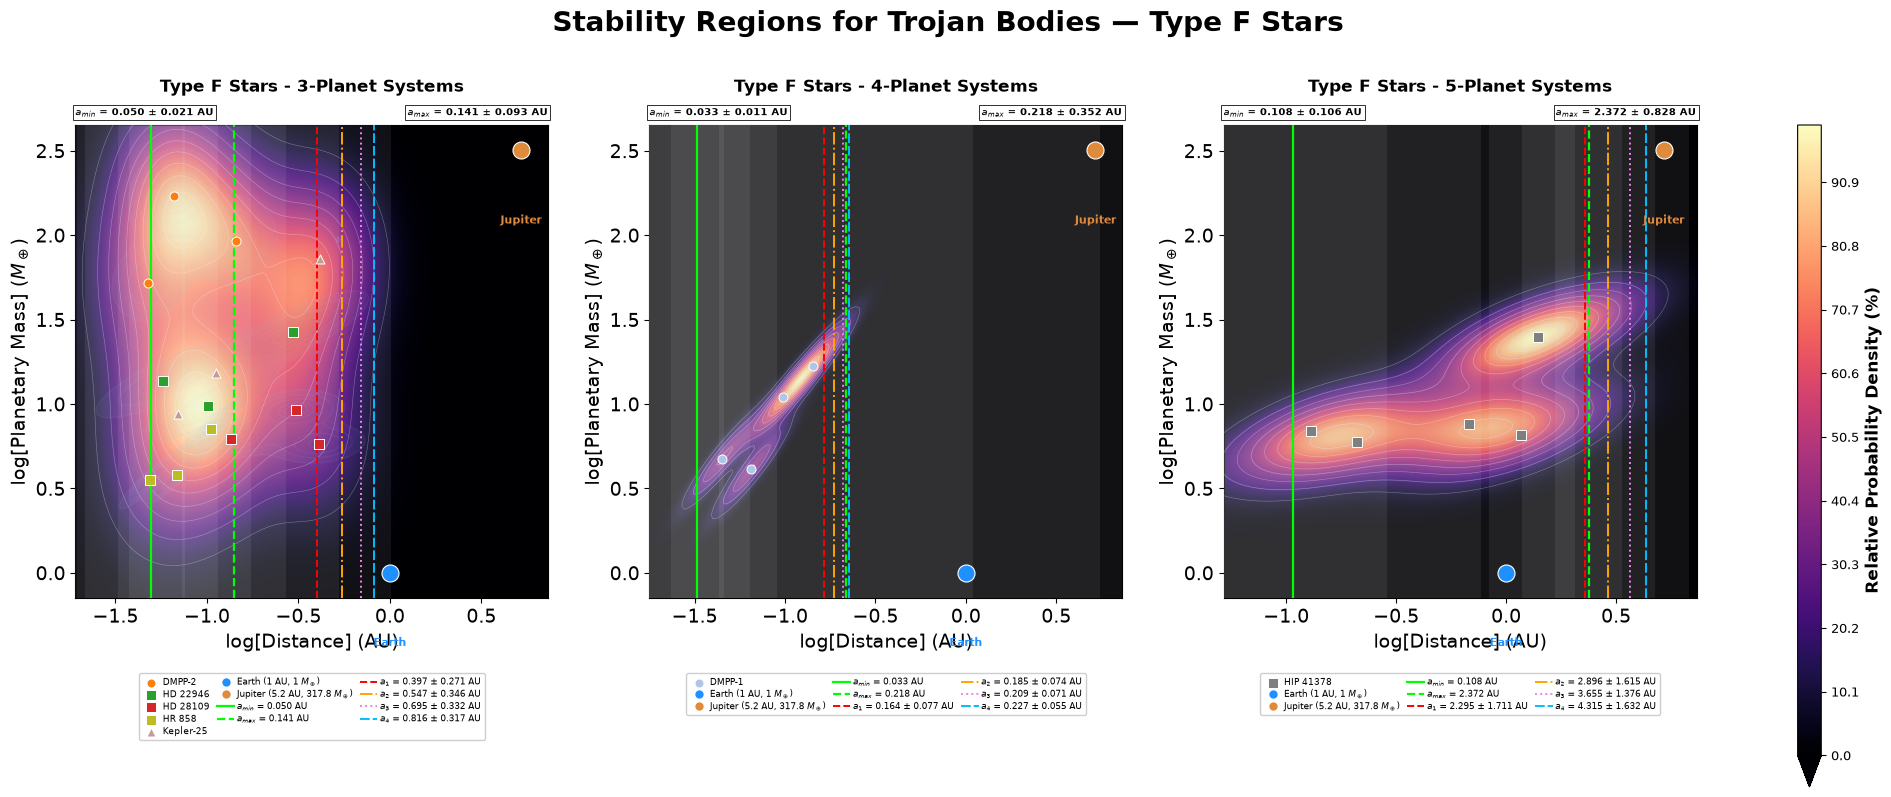

Generando paneles Tipo G: 100%|██████████| 1/1 [00:08<00:00,  8.85s/panel]


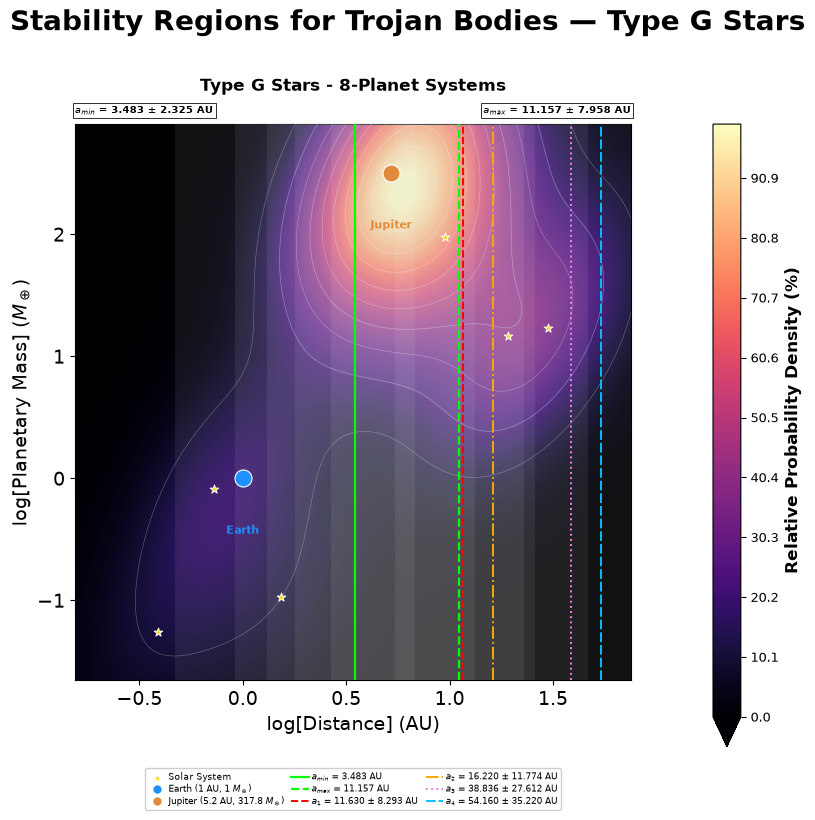

Generando paneles Tipo K: 100%|██████████| 4/4 [02:41<00:00, 40.49s/panel]


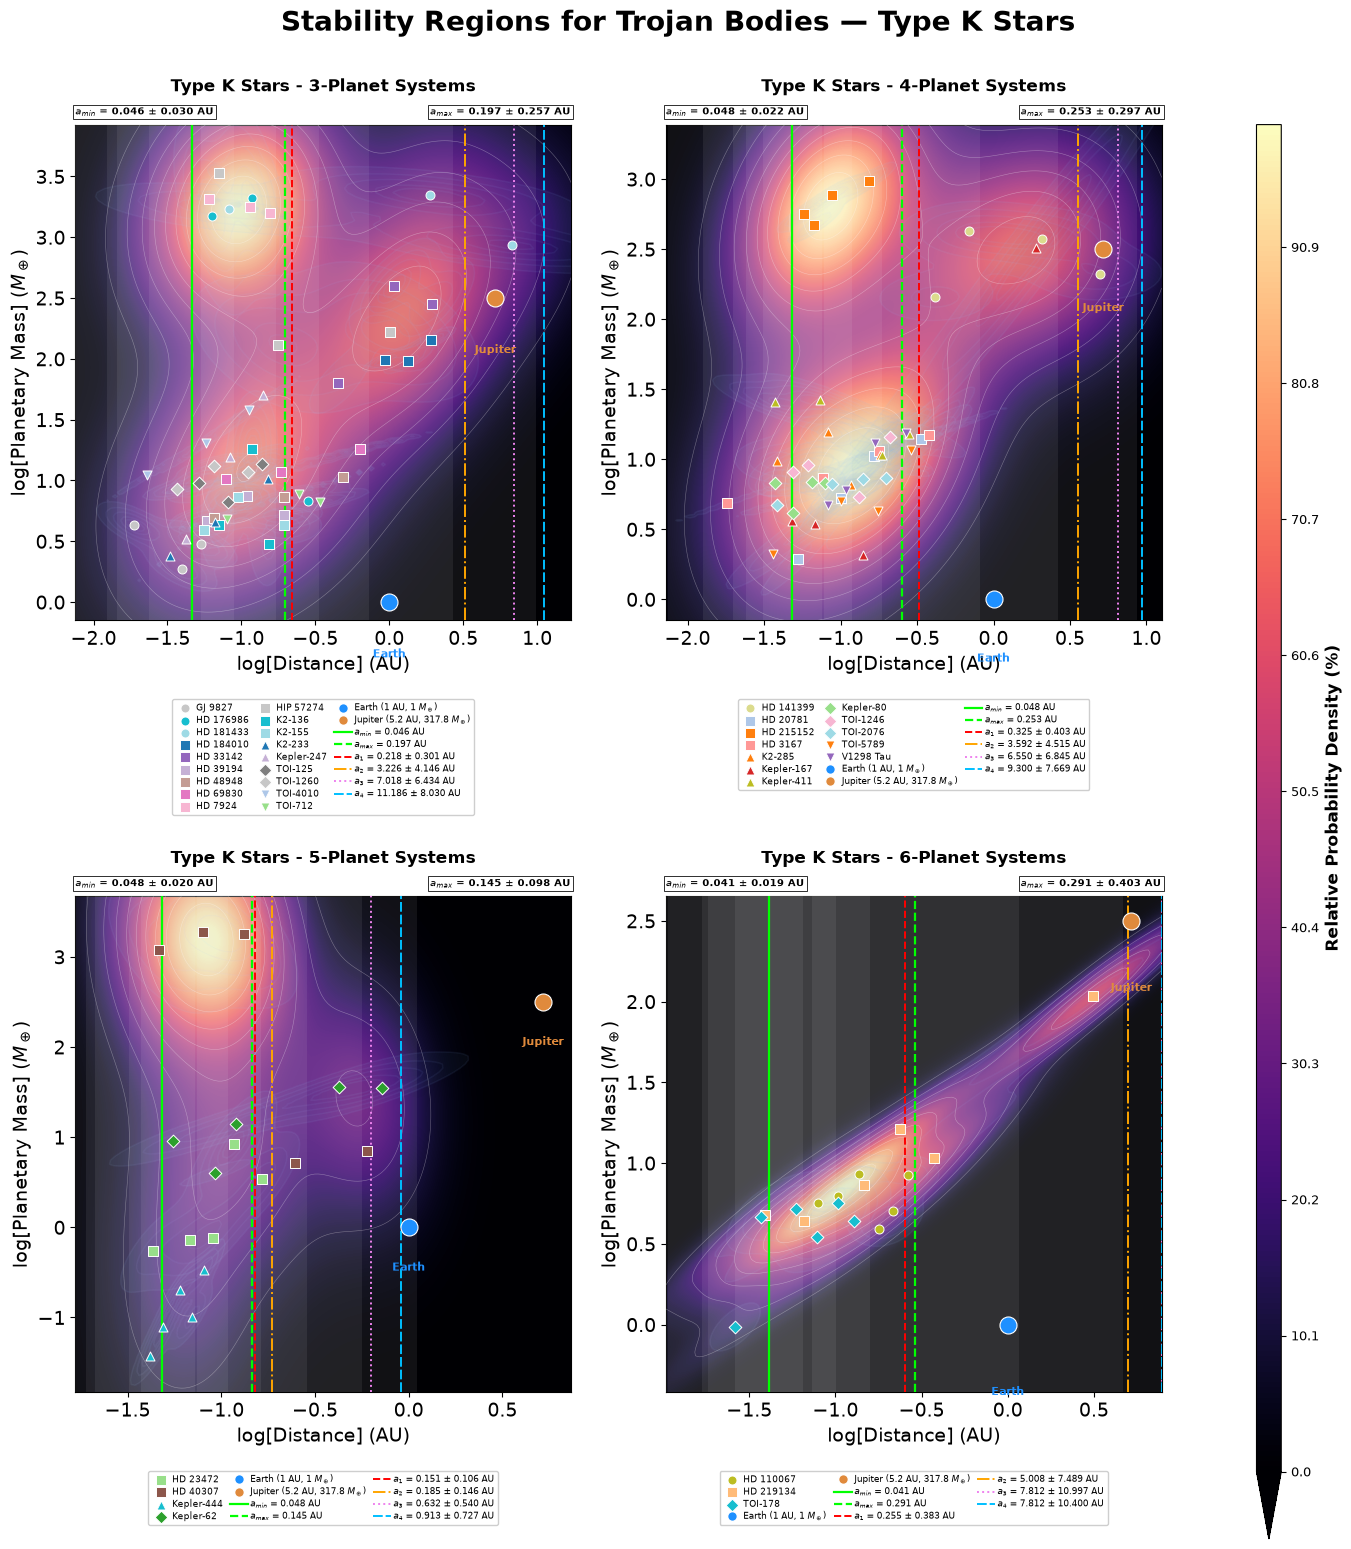

Generando paneles Tipo M: 100%|██████████| 4/4 [03:21<00:00, 50.29s/panel] 


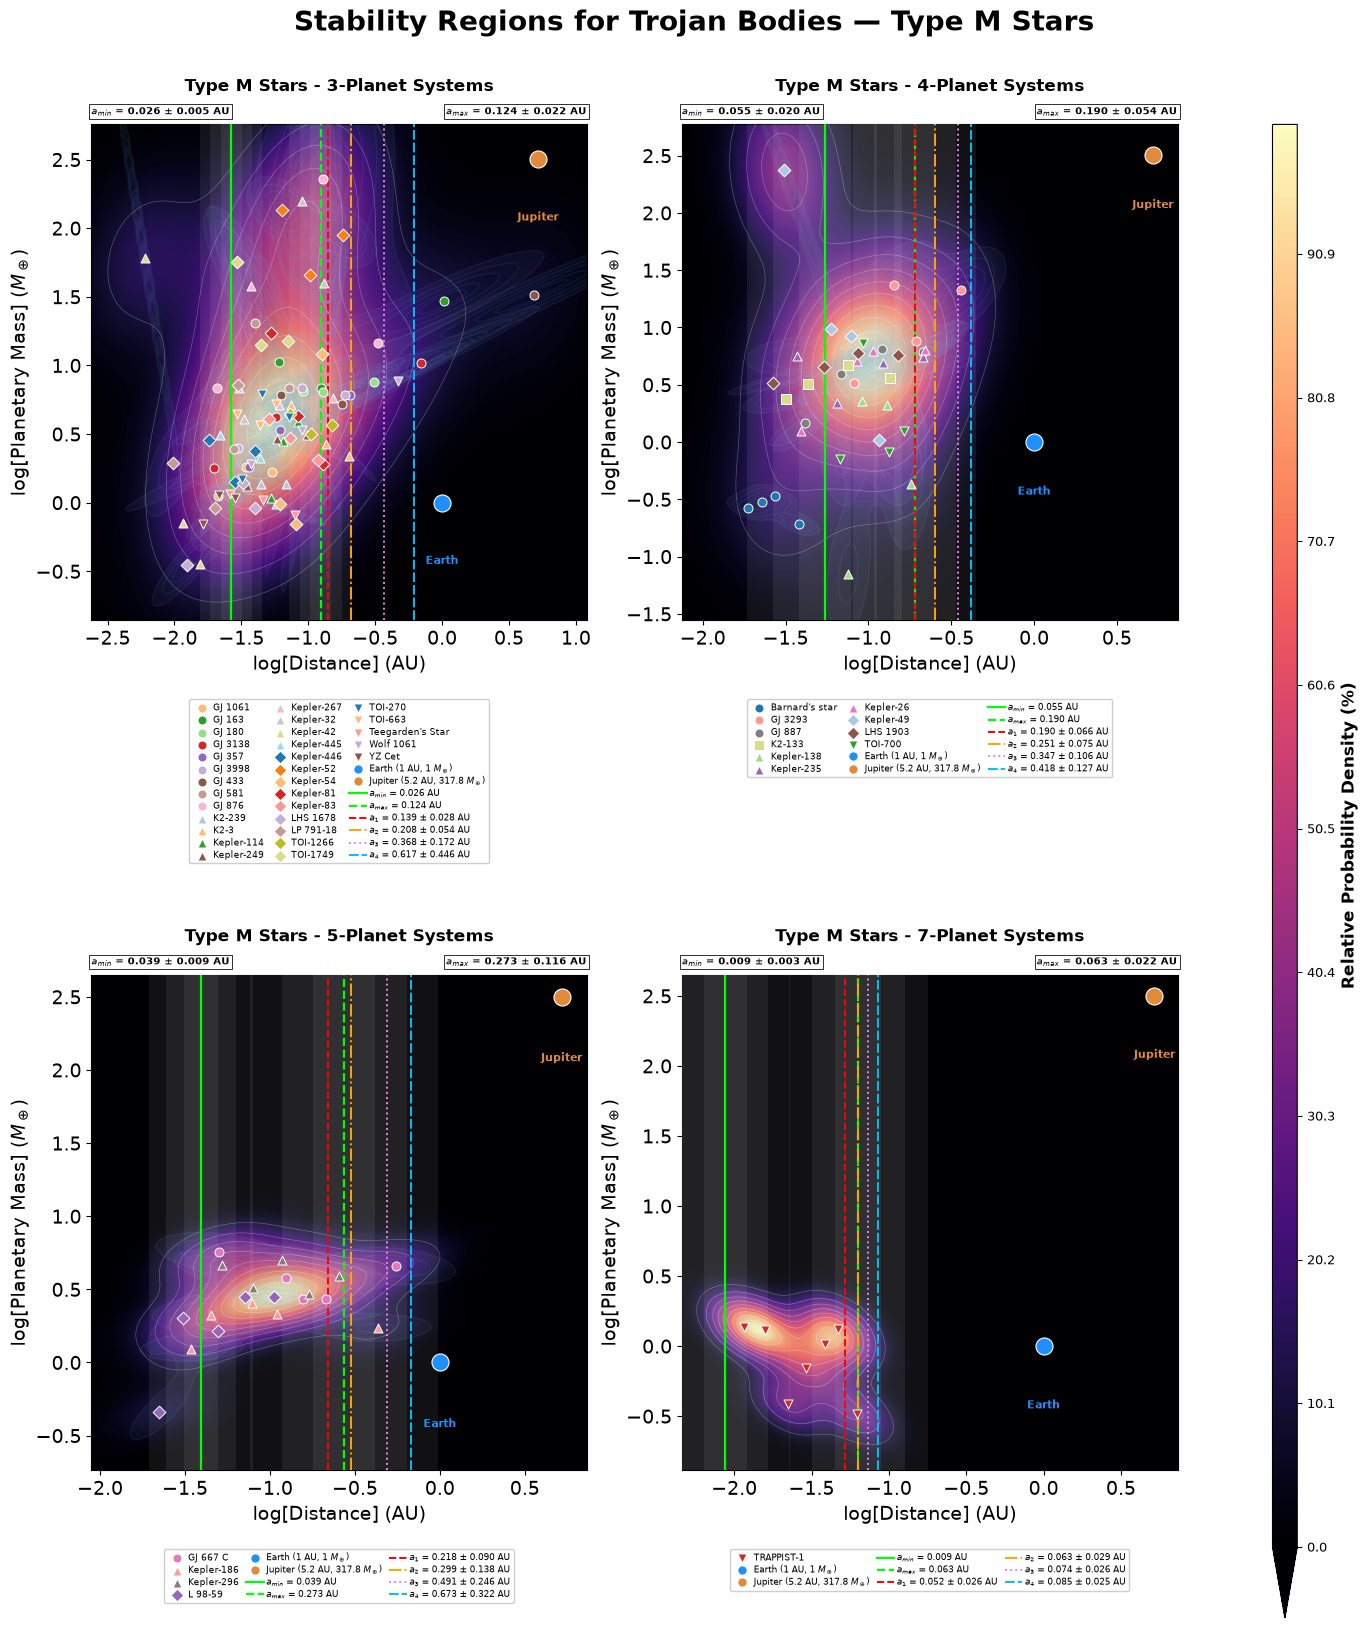

Intervalos σ guardados en: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_F\graficos_magma_con_sistemas_azules\intervalos_sigma_fraccion.csv
   Aviso: con 637 réplicas cada cola de 3σ queda apoyada en ~0.9 réplicas; el 3σ por percentil es poco fiable. Sube kde['n_bootstrap'] a 5000-10000 si lo vas a reportar.
Análisis del Sistema Solar omitido: faltan planetas solares o sistemas G de referencia.
Gráficos guardados en: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_F\graficos_magma_con_sistemas_azules


In [4]:
if __name__ == "__main__":
    if len(sys.argv) > 1 and sys.argv[1].lower() == "solar":
        ejecutar_sistema_solar()
    else:
        ejecutar()